# Temporal Analysis of Concept Drift and Class Imbalance in Card Payment Fraud Detection Using Machine Learning

**MSc Dissertation: AI and Data Science**

## Overview

This notebook contains the full machine learning pipeline used in this dissertation. It runs in seven parts, in order, from top to bottom:

1. **Data Enrichment**: the Sparkov simulated transaction dataset (`fraudTrain` / `fraudTest`, ~1.85 million transactions, January 2019 to December 2020) is joined with US Census ACS 2019 socioeconomic data at zip code level.
2. **Exploratory Data Analysis**: the enriched dataset is examined for class imbalance, transaction patterns, and early signs of concept drift.
3. **Data Preprocessing**: irrelevant columns are removed, new features are engineered, missing values are imputed, categorical variables are encoded, and class imbalance is corrected using SMOTE.
4. **Model Training and Evaluation**: four classifiers (Logistic Regression, Random Forest, XGBoost, and a Deep Neural Network) are trained and compared using AUPRC, ROC AUC, precision, recall and F1, alongside SHAP feature importance.
5. **Threshold Optimisation**: the default 0.5 classification cut off is tested against alternative thresholds to find the point that best balances catching fraud against raising false alerts.
6. **Concept Drift Detection**: ADWIN and DDM are applied to the XGBoost prediction error stream to detect where the fraud pattern shifts over time.
7. **Final Results Summary**: the key results from every part above are brought together in one place.

All settings that control the pipeline (file names, random seed, sample sizes, and cost assumptions) are defined once in the **Configuration Constants** cell below, so they only need to be changed in one place.

**Note on hardware:** training on 1.85 million rows, SMOTE resampling, and SHAP are memory intensive. These steps are best run on a machine with sufficient RAM, or on HPC, rather than a standard laptop.

# Part 1: Data Enrichment

This part loads the raw Sparkov transaction files and the US Census ACS 2019 files, extracts a zip code from each, and joins the two together. The result is two enriched CSV files (`fraudTrain_enriched.csv` and `fraudTest_enriched.csv`) that carry nine extra socioeconomic columns alongside the original transaction data. These enriched files are the starting point for every part that follows.

## 1.1 Setup: Import Libraries and Configuration Constants

In [1]:

#  IMPORT LIBRARIES

import pandas as pd    # pandas handles everything to do with tables
import os              # os lets us interact with the file system
import warnings        # warnings lets us silence unhelpful messages

warnings.filterwarnings('ignore')   # switch off warnings we do not need

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# CONFIGURATION CONSTANTS
# Every setting that controls this pipeline is defined here,
# so it only has to be changed in one place.

# Reproducibility
RANDOM_STATE = 42                              # fixed seed used everywhere so results are repeatable

# Raw input files (Sparkov transactions + US Census ACS 2019)
TRAIN_RAW_FILE    = 'fraudTrain.csv'
TEST_RAW_FILE     = 'fraudTest.csv'
CENSUS_DP05_FILE  = 'ACSDP5Y2019.DP05-Data.csv'    # demographics: population, age, sex, ethnicity
CENSUS_S1901_FILE = 'ACSST5Y2019.S1901-Data.csv'   # household income

# Output files after Census enrichment (Part 1)
TRAIN_ENRICHED_FILE = 'fraudTrain_enriched.csv'
TEST_ENRICHED_FILE  = 'fraudTest_enriched.csv'

# Output files after preprocessing and SMOTE (Part 3)
TRAIN_PREPROCESSED_FILE = 'train_preprocessed.csv'
TEST_PREPROCESSED_FILE  = 'test_preprocessed.csv'

# Sampling sizes - used to keep hyperparameter search and SHAP
# fast on a dataset with 1.85 million rows
HYPERPARAM_SAMPLE_SIZE = 100_000    # rows used for Logistic Regression / Random Forest / XGBoost / DNN tuning
SHAP_SAMPLE_SIZE       = 1_000      # rows used to compute SHAP values

# Classification threshold
DEFAULT_THRESHOLD = 0.5    # standard cut off used by every model unless optimised in Part 5

# Cost assumptions for threshold optimisation (Part 5)
# These are relative costs, not real currency - adjust to match
# a real business case if one becomes available
COST_PER_MISSED_FRAUD = 100    # cost of a false negative: fraud that was not caught
COST_PER_FALSE_ALERT  = 5      # cost of a false positive: legitimate transaction flagged as fraud

# Chart settings
CHART_DPI          = 150    # resolution used for every saved chart
AMOUNT_DISPLAY_CAP = 500    # transactions above this amount are excluded from amount charts only, so the histogram is easier to read

print("Configuration constants loaded.")

Configuration constants loaded.


## 1.2 Check All Required Files Exist

In [3]:

#  CHECK ALL REQUIRED FILES EXIST


required_files = [
    TRAIN_RAW_FILE,                    # Sparkov training transactions
    TEST_RAW_FILE,                     # Sparkov test transactions
    CENSUS_DP05_FILE,                  # Census demographics (age, gender, ethnicity)
    CENSUS_S1901_FILE,                 # Census income
]

all_found = True    # we assume all files exist until we find one that does not

for filename in required_files:
    if os.path.exists(filename):
        size_mb = os.path.getsize(filename) / 1_000_000    # convert bytes to megabytes
        print(f"Found:   {filename}   ({size_mb:.1f} MB)")
    else:
        print(f"MISSING: {filename}")
        all_found = False    # mark that at least one file is missing

if all_found:
    print("\nAll four files found. Ready to proceed.")
else:
    print("\nOne or more files are missing. Place all four CSV files")
    print("in the same folder as this script and try again.")

Found:   fraudTrain.csv   (351.2 MB)
Found:   fraudTest.csv   (150.4 MB)
Found:   ACSDP5Y2019.DP05-Data.csv   (70.0 MB)
Found:   ACSST5Y2019.S1901-Data.csv   (28.0 MB)

All four files found. Ready to proceed.


## 1.3 Load the Sparkov Transaction Files

In [4]:

# LOAD THE SPARKOV TRANSACTION FILES


train = pd.read_csv(TRAIN_RAW_FILE)      # load training transactions
test  = pd.read_csv(TEST_RAW_FILE)       # load test transactions

# Print the size of each file so we know what we are working with
print(f"Training set:  {len(train):,} rows  x  {train.shape[1]} columns")
print(f"Test set:      {len(test):,} rows  x  {test.shape[1]} columns")

# Show all the column names in the training set
print(f"\nColumns in the Sparkov dataset:")
for i, col in enumerate(train.columns, 1):
    print(f"  {i:>2}. {col}")

# Check the target variable: is_fraud
# value_counts() counts how many 0s (legitimate) and 1s (fraud) there are
fraud_counts = train['is_fraud'].value_counts()
fraud_rate   = fraud_counts[1] / len(train) * 100

print(f"\nClass distribution in training set:")
print(f"  Legitimate (0):  {fraud_counts[0]:,}   ({100 - fraud_rate:.3f}%)")
print(f"  Fraud      (1):  {fraud_counts[1]:,}   ({fraud_rate:.3f}%)")

# Check the zip code column: this is the key we will use for joining
print(f"\nZip code column:")
print(f"  Data type:         {train['zip'].dtype}")
print(f"  Unique zip codes:  {train['zip'].nunique():,}")
print(f"  Sample values:     {train['zip'].head(5).tolist()}")

Training set:  1,296,675 rows  x  23 columns
Test set:      555,719 rows  x  23 columns

Columns in the Sparkov dataset:
   1. Unnamed: 0
   2. trans_date_trans_time
   3. cc_num
   4. merchant
   5. category
   6. amt
   7. first
   8. last
   9. gender
  10. street
  11. city
  12. state
  13. zip
  14. lat
  15. long
  16. city_pop
  17. job
  18. dob
  19. trans_num
  20. unix_time
  21. merch_lat
  22. merch_long
  23. is_fraud

Class distribution in training set:
  Legitimate (0):  1,289,169   (99.421%)
  Fraud      (1):  7,506   (0.579%)

Zip code column:
  Data type:         int64
  Unique zip codes:  970
  Sample values:     [28654, 99160, 83252, 59632, 24433]


## 1.4 Load the Census Files

In [5]:

# STEP 4: LOAD THE CENSUS FILES


dp05 = pd.read_csv(
    CENSUS_DP05_FILE,
    low_memory=False,    # prevents a warning about mixed data types in large files
    skiprows=[1]         # skip the description row go straight to the data
)

s1901 = pd.read_csv(
    CENSUS_S1901_FILE,
    low_memory=False,    # same reason as above
    skiprows=[1]         # same reason as above
)

# Print the size of each Census file
print(f"DP05  (demographics):  {len(dp05):,} rows  x  {dp05.shape[1]} columns")
print(f"S1901 (income):        {len(s1901):,} rows  x  {s1901.shape[1]} columns")
print(f"\nEach row represents one zip code area in the United States.")

# Show what the GEO_ID column looks like
# This is important because the zip code is hidden inside it
print(f"\nSample GEO_ID values from DP05:")
for val in dp05['GEO_ID'].head(3).tolist():
    print(f"  {val}")
print(f"\nThe last 5 characters of each GEO_ID is the zip code we need.")

DP05  (demographics):  33,120 rows  x  359 columns
S1901 (income):        33,120 rows  x  131 columns

Each row represents one zip code area in the United States.

Sample GEO_ID values from DP05:
  8600000US00601
  8600000US00602
  8600000US00603

The last 5 characters of each GEO_ID is the zip code we need.


## 1.5 Extract Zip Codes from the Census Data

The zip code is hidden inside the `GEO_ID` column of each Census file. This step pulls it out so it can be used as the join key later, and previews how many Sparkov zip codes are likely to find a match.

In [6]:

# EXTRACT ZIP CODE FROM CENSUS GEO_ID

# Extract last 5 characters of GEO_ID to get the zip code
dp05['zip']  = dp05['GEO_ID'].str[-5:].str.zfill(5)
s1901['zip'] = s1901['GEO_ID'].str[-5:].str.zfill(5)

# Confirm the extraction worked by printing sample values
print("Sample GEO_ID values and their extracted zip codes:")
print()

print(f"  {'GEO_ID':<20}  {'Extracted zip'}")

for geo_id, zip_code in zip(dp05['GEO_ID'].head(5), dp05['zip'].head(5)):
    print(f"  {geo_id:<20}  {zip_code}")

# Confirm both files have the same number of unique zip codes
print(f"\nUnique zip codes in DP05:  {dp05['zip'].nunique():,}")
print(f"Unique zip codes in S1901: {s1901['zip'].nunique():,}")
print(f"\nBoth files have the same zip codes: {dp05['zip'].nunique() == s1901['zip'].nunique()}")

# Check how many Sparkov zip codes exist in the Census data
# This tells us what our match rate will be before we even merge
sparkov_zips = set(train['zip'].astype(str).str.zfill(5).unique())
census_zips  = set(dp05['zip'].unique())

matched   = len(sparkov_zips & census_zips)   # zip codes in BOTH datasets
unmatched = len(sparkov_zips - census_zips)   # zip codes in Sparkov but NOT in Census

print(f"\nMatch rate preview:")
print(f"  Unique zip codes in Sparkov:        {len(sparkov_zips):,}")
print(f"  Found in Census data:               {matched:,}  ({matched/len(sparkov_zips)*100:.2f}%)")
print(f"  Not found in Census data:           {unmatched:,}  ({unmatched/len(sparkov_zips)*100:.2f}%)")

Sample GEO_ID values and their extracted zip codes:

  GEO_ID                Extracted zip
  8600000US00601        00601
  8600000US00602        00602
  8600000US00603        00603
  8600000US00606        00606
  8600000US00610        00610

Unique zip codes in DP05:  33,120
Unique zip codes in S1901: 33,120

Both files have the same zip codes: True

Match rate preview:
  Unique zip codes in Sparkov:        970
  Found in Census data:               970  (100.00%)
  Not found in Census data:           0  (0.00%)


## 1.6 Select and Rename the Demographic Columns (DP05)

DP05 contains hundreds of columns. Only the nine relevant to this dissertation (population, age, sex, and ethnicity) are kept and renamed to something readable.

In [7]:

#  SELECT AND RENAME COLUMNS FROM DP05

# Dictionary mapping Census column codes to readable names
# Key   = the original Census column code in the file
# Value = the clean readable name we want to use instead
dp05_columns = {
    'DP05_0001E':  'total_population',      # total number of people in the zip area
    'DP05_0002E':  'population_male',        # number of males (raw count)
    'DP05_0003E':  'population_female',      # number of females (raw count)
    'DP05_0018E':  'median_age',             # median age of all residents in years
    'DP05_0071PE': 'pct_hispanic_latino',    # percentage Hispanic or Latino
    'DP05_0077PE': 'pct_white',              # percentage White alone, not Hispanic
    'DP05_0078PE': 'pct_black',              # percentage Black or African American
    'DP05_0079PE': 'pct_native_american',    # percentage American Indian Alaska Native
    'DP05_0080PE': 'pct_asian',              # percentage Asian alone
}

# Before selecting, verify every column code exists in the file
# This protects against the Census changing column numbering
# between different years of the survey
print("Verifying column codes exist in DP05:")
print()
all_found = True
for code, readable_name in dp05_columns.items():
    exists = code in dp05.columns
    status = "Found" if exists else "NOT FOUND"
    print(f"  {code}  ->  {readable_name:<25}  {status}")
    if not exists:
        all_found = False

print()
if all_found:
    print("All column codes verified successfully.")
else:
    print("WARNING: One or more column codes were not found.")
    print("Check the column codes against the actual file.")

# Select only the zip column plus our 9 chosen columns
# then rename them all to readable names
demo = dp05[['zip'] + list(dp05_columns.keys())].copy()
demo = demo.rename(columns=dp05_columns)

# Confirm the result
print(f"\nDP05 demographic table after selection and renaming:")
print(f"  Rows:    {len(demo):,}")
print(f"  Columns: {demo.shape[1]}")
print(f"\n  Column list:")
for i, col in enumerate(demo.columns, 1):
    print(f"    {i:>2}. {col}")

# Show a sample row so we can see the actual values
print(f"\nFirst 3 rows of the demographic table:")
print(demo.head(3).to_string(index=False))

Verifying column codes exist in DP05:

  DP05_0001E  ->  total_population           Found
  DP05_0002E  ->  population_male            Found
  DP05_0003E  ->  population_female          Found
  DP05_0018E  ->  median_age                 Found
  DP05_0071PE  ->  pct_hispanic_latino        Found
  DP05_0077PE  ->  pct_white                  Found
  DP05_0078PE  ->  pct_black                  Found
  DP05_0079PE  ->  pct_native_american        Found
  DP05_0080PE  ->  pct_asian                  Found

All column codes verified successfully.

DP05 demographic table after selection and renaming:
  Rows:    33,120
  Columns: 10

  Column list:
     1. zip
     2. total_population
     3. population_male
     4. population_female
     5. median_age
     6. pct_hispanic_latino
     7. pct_white
     8. pct_black
     9. pct_native_american
    10. pct_asian

First 3 rows of the demographic table:
  zip  total_population  population_male  population_female median_age pct_hispanic_latino pct_whi

## 1.7 Select and Clean the Income Column (S1901)

S1901 provides median household income by zip code. The raw values contain commas (e.g. `61,000`), so these are stripped out before converting to a number.

In [8]:

#  SELECT AND RENAME COLUMNS FROM S1901

# The Census code for median household income
income_code = 'S1901_C01_012E'

print("Verifying income column exists in S1901:")
print()

if income_code in s1901.columns:
    print(f"  {income_code}  ->  median_household_income  Found")
else:
    print(f"  {income_code}  ->  median_household_income  NOT FOUND")

# Select only the zip column and the income column
inc = s1901[['zip', income_code]].copy()
inc = inc.rename(columns={income_code: 'median_household_income'})

# Clean the income column before converting to numbers.
# Census files sometimes store values with commas inside them
# for example 61,000 instead of 61000.
# We strip those commas out first, then convert to numeric.
# errors='coerce' means any value that still cannot be
# converted (like '-' or 'N') becomes NaN instead of crashing.
inc['median_household_income'] = (
    inc['median_household_income']
    .astype(str)                          # make sure it is text first
    .str.replace(',', '', regex=False)    # remove all commas
    .str.strip()                          # remove any extra spaces
    .pipe(pd.to_numeric, errors='coerce') # now convert to a number
)

# Confirm the result
print(f"\nS1901 income table after selection and renaming:")
print(f"  Rows:    {len(inc):,}")
print(f"  Columns: {inc.shape[1]}")
print(f"\n  Column list:")
for i, col in enumerate(inc.columns, 1):
    print(f"    {i}. {col}")

# Show the first 5 rows to confirm the values look realistic
print(f"\nFirst 5 rows of the income table:")
print(inc.head(5).to_string(index=False))

# Basic statistics on the income column
print(f"\nIncome column summary statistics:")
print(f"  Lowest  median income:  ${inc['median_household_income'].min():>10,.0f}")
print(f"  Highest median income:  ${inc['median_household_income'].max():>10,.0f}")
print(f"  Average median income:  ${inc['median_household_income'].mean():>10,.0f}")
print(f"  Null values:             {inc['median_household_income'].isnull().sum():,}")

Verifying income column exists in S1901:

  S1901_C01_012E  ->  median_household_income  Found

S1901 income table after selection and renaming:
  Rows:    33,120
  Columns: 2

  Column list:
    1. zip
    2. median_household_income

First 5 rows of the income table:
  zip  median_household_income
00601                  14361.0
00602                  16807.0
00603                  16049.0
00606                  12119.0
00610                  19898.0

Income column summary statistics:
  Lowest  median income:  $     6,493
  Highest median income:  $   248,243
  Average median income:  $    61,228
  Null values:             2,323


## 1.8 Convert Population Counts to Percentages

Raw male and female counts are converted to percentages so they are comparable across zip codes of very different sizes.

In [9]:

# CONVERT MALE AND FEMALE COUNTS TO PERCENTAGES

print("Converting raw population counts to percentages...")
print()

# Show a sample BEFORE the conversion so we can compare
print("Before conversion (first 3 rows):")
print(demo[['zip','total_population','population_male',
            'population_female','median_age']].head(3).to_string(index=False))

# Calculate percentage male
# Divide the male count by the total population and multiply
# by 100 to get a percentage. Round to 2 decimal places.
demo['pct_male'] = (
    demo['population_male'] / demo['total_population'] * 100
).round(2)

# Calculate percentage female using the same approach
demo['pct_female'] = (
    demo['population_female'] / demo['total_population'] * 100
).round(2)

# Drop the raw count columns: we no longer need them
# now that we have the percentages. These columns were just used
# above to compute pct_male/pct_female, so they are always
# present here; no errors= parameter is needed.
demo = demo.drop(
    columns=['population_male', 'population_female', 'total_population']
)

# Show the result AFTER the conversion
print()
print("After conversion (first 3 rows):")
print(demo.head(3).to_string(index=False))

# Confirm the final columns in the demo table
print(f"\nFinal columns in demographic table:")
for i, col in enumerate(demo.columns, 1):
    print(f"  {i}. {col}")

# Quick sanity check: pct_male + pct_female should be
# very close to 100% for every row
demo['check'] = demo['pct_male'] + demo['pct_female']
perfect = (demo['check'].between(99.9, 100.1)).sum()
print(f"\nSanity check: pct_male + pct_female is approximately 100%")
print(f"  Rows where total is between 99.9% and 100.1%: {perfect:,}")
print(f"  Total rows: {len(demo):,}")

# Remove the temporary check column
demo = demo.drop(columns=['check'])

print(f"\nConversion complete.")

Converting raw population counts to percentages...

Before conversion (first 3 rows):
  zip  total_population  population_male  population_female median_age
00601             17113             8533               8580       41.9
00602             37751            18488              19263       42.9
00603             47081            23120              23961       42.1

After conversion (first 3 rows):
  zip median_age pct_hispanic_latino pct_white pct_black pct_native_american pct_asian  pct_male  pct_female
00601       41.9                99.6       0.3       0.0                 0.0       0.0     49.86       50.14
00602       42.9                92.5       6.7       0.0                 0.1       0.0     48.97       51.03
00603       42.1                97.4       1.7       0.2                 0.0       0.1     49.11       50.89

Final columns in demographic table:
  1. zip
  2. median_age
  3. pct_hispanic_latino
  4. pct_white
  5. pct_black
  6. pct_native_american
  7. pct_asian
  8

## 1.9 Merge the Demographic and Income Tables

The DP05 and S1901 tables are combined into a single Census enrichment table, joined on zip code.

In [10]:
#  MERGE DP05 AND S1901 INTO ONE CENSUS TABLE

print("Merging DP05 demographic table and S1901 income table...")
print()

# Show the size of each table before merging
print(f"Before merge:")
print(f"  demo table:  {len(demo):,} rows  x  {demo.shape[1]} columns")
print(f"  inc  table:  {len(inc):,} rows  x  {inc.shape[1]} columns")

# Merge the two Census tables together using zip as the key
# on='zip'   means match rows where the zip code is equal
# how='left' means keep all rows from demo whether or not
#            they find a match in inc
census = demo.merge(
    inc,
    on='zip',
    how='left'
)

# Show the size after merging
print(f"\nAfter merge:")
print(f"  census table: {len(census):,} rows  x  {census.shape[1]} columns")

# Confirm the column list of the combined Census table
print(f"\nColumns in the combined Census enrichment table:")
for i, col in enumerate(census.columns, 1):
    print(f"  {i:>2}. {col}")

# Show the first 3 rows to confirm everything looks right
print(f"\nFirst 3 rows of the Census enrichment table:")
print(census.head(3).to_string(index=False))

# Check that no rows were lost during the merge
rows_match = len(census) == len(demo)
print(f"\nRow count check:")
print(f"  demo rows:   {len(demo):,}")
print(f"  census rows: {len(census):,}")
print(f"  Row count unchanged: {rows_match}")

# Check how many zip codes have both demographic AND income data
complete = census['median_household_income'].notna().sum()
missing  = census['median_household_income'].isna().sum()
print(f"\nIncome data availability:")
print(f"  Zip codes with income data:    {complete:,}  ({complete/len(census)*100:.2f}%)")
print(f"  Zip codes without income data: {missing:,}   ({missing/len(census)*100:.2f}%)")
print(f"\nCensus enrichment table is ready.")

Merging DP05 demographic table and S1901 income table...

Before merge:
  demo table:  33,120 rows  x  9 columns
  inc  table:  33,120 rows  x  2 columns

After merge:
  census table: 33,120 rows  x  10 columns

Columns in the combined Census enrichment table:
   1. zip
   2. median_age
   3. pct_hispanic_latino
   4. pct_white
   5. pct_black
   6. pct_native_american
   7. pct_asian
   8. pct_male
   9. pct_female
  10. median_household_income

First 3 rows of the Census enrichment table:
  zip median_age pct_hispanic_latino pct_white pct_black pct_native_american pct_asian  pct_male  pct_female  median_household_income
00601       41.9                99.6       0.3       0.0                 0.0       0.0     49.86       50.14                  14361.0
00602       42.9                92.5       6.7       0.0                 0.1       0.0     48.97       51.03                  16807.0
00603       42.1                97.4       1.7       0.2                 0.0       0.1     49.11      

## 1.10 Standardise Zip Code Formats

Sparkov stores zip codes as integers, which drops any leading zeros, while the Census files store them as 5 digit strings. Both are converted to the same 5 digit string format so the join in the next two steps works correctly.

In [11]:

#  STANDARDISE SPARKOV ZIP CODES TO STRING FORMAT

# The fix is to convert Sparkov zip codes to strings and
# then zero pad them to exactly 5 characters using zfill(5).
# This turns 601 into '00601' and 28654 into '28654'.

print("Standardising Sparkov zip codes to 5 digit string format...")
print()

# Show the zip column BEFORE standardising
print("Train zip codes BEFORE standardising:")
print(f"  Data type:     {train['zip'].dtype}")
print(f"  Sample values: {train['zip'].head(5).tolist()}")

print()
print("Test zip codes BEFORE standardising:")
print(f"  Data type:     {test['zip'].dtype}")
print(f"  Sample values: {test['zip'].head(5).tolist()}")

# Convert train zip codes from integer to 5 digit string
# .astype(str)  converts the integer to a string
# .str.zfill(5) pads with leading zeros to make it 5 chars
train['zip_str'] = train['zip'].astype(str).str.zfill(5)

# Same conversion for the test zip codes
test['zip_str'] = test['zip'].astype(str).str.zfill(5)

# Show the zip column AFTER standardising
print()
print("Train zip codes AFTER standardising:")
print(f"  Data type:     {train['zip_str'].dtype}")
print(f"  Sample values: {train['zip_str'].head(5).tolist()}")

print()
print("Test zip codes AFTER standardising:")
print(f"  Data type:     {test['zip_str'].dtype}")
print(f"  Sample values: {test['zip_str'].head(5).tolist()}")

# Confirm the Census zip format matches
print()
print(f"Census zip codes format (for comparison):")
print(f"  Data type:     {census['zip'].dtype}")
print(f"  Sample values: {census['zip'].head(5).tolist()}")

# Final confirmation that formats now match
sparkov_type = train['zip_str'].dtype
census_type  = census['zip'].dtype
print()
print(f"Format match check:")
print(f"  Sparkov zip type: {sparkov_type}")
print(f"  Census  zip type: {census_type}")
print(f"  Types match: {sparkov_type == census_type}")

# Check for any zip codes that might have been affected
# by the leading zero issue
leading_zero_zips = train[train['zip_str'].str.startswith('0')]['zip_str'].unique()
print(f"\nZip codes with leading zeros in Sparkov data:")
if len(leading_zero_zips) > 0:
    print(f"  Found {len(leading_zero_zips)} zip codes with leading zeros")
    print(f"  Examples: {sorted(leading_zero_zips)[:5]}")
else:
    print(f"  None found")
print(f"\nStandardisation complete. Ready to merge.")

Standardising Sparkov zip codes to 5 digit string format...

Train zip codes BEFORE standardising:
  Data type:     int64
  Sample values: [28654, 99160, 83252, 59632, 24433]

Test zip codes BEFORE standardising:
  Data type:     int64
  Sample values: [29209, 84002, 11710, 32780, 49632]

Train zip codes AFTER standardising:
  Data type:     object
  Sample values: ['28654', '99160', '83252', '59632', '24433']

Test zip codes AFTER standardising:
  Data type:     object
  Sample values: ['29209', '84002', '11710', '32780', '49632']

Census zip codes format (for comparison):
  Data type:     object
  Sample values: ['00601', '00602', '00603', '00606', '00610']

Format match check:
  Sparkov zip type: object
  Census  zip type: object
  Types match: True

Zip codes with leading zeros in Sparkov data:
  Found 58 zip codes with leading zeros
  Examples: ['01257', '01330', '01535', '01545', '01612']

Standardisation complete. Ready to merge.


## 1.11 Merge Census Data into the Training Transactions

A left join keeps every transaction and fills in the nine Census columns wherever a zip code match is found.

In [12]:

#  MERGE CENSUS DATA INTO TRAINING TRANSACTIONS

# We use a LEFT JOIN which means:
#   - Every transaction is ALWAYS kept in the result
#   - If the zip code is found in Census: fill in the 9 values
#   - If the zip code is NOT found: leave as NaN


print("Merging Census enrichment into TRAINING transactions...")
print()

# Define the Census columns we want to bring across
# We include zip so pandas knows what to join on,
# but it will be removed after the merge
enrich_cols = [
    'zip',                      # the joining key
    'median_age',               # Age  
    'pct_male',                 # Sex 
    'pct_female',               # Sex  
    'median_household_income',  # Income 
    'pct_hispanic_latino',      # Ethnicity
    'pct_white',                # Ethnicity 
    'pct_black',                # Ethnicity
    'pct_native_american',      # Ethnicity 
    'pct_asian',                # Ethnicity 
]

# Print the sizes before merging
print(f"Before merge:")
print(f"  train:  {len(train):,} rows  x  {train.shape[1]} columns")
print(f"  census: {len(census):,} rows  x  {census.shape[1]} columns")

# Perform the LEFT JOIN
# left_on='zip_str' = the standardised zip column in Sparkov
# right_on='zip'    = the zip column in Census
# how='left'        = keep ALL training transactions
train_enriched = train.merge(
    census[enrich_cols],
    left_on='zip_str',
    right_on='zip',
    how='left'
)

# The merge creates two zip columns:
#   zip_x = the original zip from the train table
#   zip_y = the zip from the census table
# We drop zip_y and zip_str as we no longer need them
# and rename zip_x back to zip. Both columns are always
# created by this merge, so no errors= parameter is needed.
train_enriched = train_enriched.drop(
    columns=['zip_y', 'zip_str']
)
train_enriched = train_enriched.rename(
    columns={'zip_x': 'zip'}
)

# Print the result
print(f"\nAfter merge:")
print(f"  train_enriched: {len(train_enriched):,} rows  x  {train_enriched.shape[1]} columns")

# Confirm no transactions were lost
rows_match = len(train_enriched) == len(train)
print(f"\nRow count check:")
print(f"  Original train rows:  {len(train):,}")
print(f"  Enriched train rows:  {len(train_enriched):,}")
print(f"  No transactions lost: {rows_match}")

# Check the match rate
matched   = train_enriched['median_age'].notna().sum()
unmatched = train_enriched['median_age'].isna().sum()
match_rate = matched / len(train_enriched) * 100

print(f"\nMatch rate:")
print(f"  Successfully enriched: {matched:,}  ({match_rate:.2f}%)")
print(f"  Got NaN (no match):    {unmatched:,}  ({100-match_rate:.2f}%)")

# Show null counts for each new column
print(f"\nNull values per enrichment column:")
new_cols = [c for c in enrich_cols if c != 'zip']
for col in new_cols:
    nulls = train_enriched[col].isnull().sum()
    pct   = nulls / len(train_enriched) * 100
    print(f"  {col:<30} {nulls:>8,}  ({pct:.2f}%)")

# Preview the merged result
print(f"\nPreview of enriched training data (selected columns):")
preview = ['trans_date_trans_time','category','amt','zip',
           'median_age','pct_male','median_household_income',
           'pct_white','is_fraud']
print(train_enriched[preview].head(5).to_string(index=False))

print(f"\nTraining merge complete.")

Merging Census enrichment into TRAINING transactions...

Before merge:
  train:  1,296,675 rows  x  24 columns
  census: 33,120 rows  x  10 columns

After merge:
  train_enriched: 1,296,675 rows  x  32 columns

Row count check:
  Original train rows:  1,296,675
  Enriched train rows:  1,296,675
  No transactions lost: True

Match rate:
  Successfully enriched: 1,296,675  (100.00%)
  Got NaN (no match):    0  (0.00%)

Null values per enrichment column:
  median_age                            0  (0.00%)
  pct_male                         14,935  (1.15%)
  pct_female                       14,935  (1.15%)
  median_household_income          87,062  (6.71%)
  pct_hispanic_latino                   0  (0.00%)
  pct_white                             0  (0.00%)
  pct_black                             0  (0.00%)
  pct_native_american                   0  (0.00%)
  pct_asian                             0  (0.00%)

Preview of enriched training data (selected columns):
trans_date_trans_time      cat

## 1.12 Merge Census Data into the Test Transactions

The same Census table and the same join logic are applied to the test set, so the two sets are enriched in exactly the same way.

In [13]:

#  MERGE CENSUS DATA INTO TEST TRANSACTIONS

print("Merging Census enrichment into TEST transactions...")
print()

# Print sizes before merging
print(f"Before merge:")
print(f"  test:   {len(test):,} rows  x  {test.shape[1]} columns")
print(f"  census: {len(census):,} rows  x  {census.shape[1]} columns")
print(f"  (Using the SAME Census table as training, no leakage)")

# Perform the LEFT JOIN on the test set
# Identical approach to Step 11
test_enriched = test.merge(
    census[enrich_cols],       # same Census columns as Step 11
    left_on='zip_str',         # standardised zip from test set
    right_on='zip',            # zip from Census table
    how='left'                 # LEFT JOIN: keep all test transactions
)

# Clean up the duplicate zip columns created by the merge.
# Both columns are always created by this merge (same as
# Step 11 above), so no errors= parameter is needed.
test_enriched = test_enriched.drop(
    columns=['zip_y', 'zip_str']
)
test_enriched = test_enriched.rename(
    columns={'zip_x': 'zip'}
)

# Print the result
print(f"\nAfter merge:")
print(f"  test_enriched: {len(test_enriched):,} rows  x  {test_enriched.shape[1]} columns")

# Confirm no transactions were lost
rows_match = len(test_enriched) == len(test)
print(f"\nRow count check:")
print(f"  Original test rows:  {len(test):,}")
print(f"  Enriched test rows:  {len(test_enriched):,}")
print(f"  No transactions lost: {rows_match}")

# Check the match rate
matched   = test_enriched['median_age'].notna().sum()
unmatched = test_enriched['median_age'].isna().sum()
match_rate = matched / len(test_enriched) * 100

print(f"\nMatch rate:")
print(f"  Successfully enriched: {matched:,}  ({match_rate:.2f}%)")
print(f"  Got NaN (no match):    {unmatched:,}  ({100-match_rate:.2f}%)")

# Check null values per enrichment column
print(f"\nNull values per enrichment column:")
for col in new_cols:
    nulls = test_enriched[col].isnull().sum()
    pct   = nulls / len(test_enriched) * 100
    print(f"  {col:<30} {nulls:>8,}  ({pct:.2f}%)")

# Compare train and test null rates side by side
print(f"\nNull rate comparison (train vs test):")
print(f"  {'Column':<30} {'Train':>10} {'Test':>10}")
for col in new_cols:
    train_pct = train_enriched[col].isnull().sum() / len(train_enriched) * 100
    test_pct  = test_enriched[col].isnull().sum()  / len(test_enriched)  * 100
    print(f"  {col:<30} {train_pct:>9.2f}% {test_pct:>9.2f}%")

# Preview the enriched test data
print(f"\nPreview of enriched test data (selected columns):")
preview = ['trans_date_trans_time','category','amt','zip',
           'median_age','pct_male','median_household_income',
           'pct_white','is_fraud']
print(test_enriched[preview].head(5).to_string(index=False))

print(f"\nTest merge complete.")

Merging Census enrichment into TEST transactions...

Before merge:
  test:   555,719 rows  x  24 columns
  census: 33,120 rows  x  10 columns
  (Using the SAME Census table as training, no leakage)

After merge:
  test_enriched: 555,719 rows  x  32 columns

Row count check:
  Original test rows:  555,719
  Enriched test rows:  555,719
  No transactions lost: True

Match rate:
  Successfully enriched: 555,719  (100.00%)
  Got NaN (no match):    0  (0.00%)

Null values per enrichment column:
  median_age                            0  (0.00%)
  pct_male                          6,271  (1.13%)
  pct_female                        6,271  (1.13%)
  median_household_income          37,272  (6.71%)
  pct_hispanic_latino                   0  (0.00%)
  pct_white                             0  (0.00%)
  pct_black                             0  (0.00%)
  pct_native_american                   0  (0.00%)
  pct_asian                             0  (0.00%)

Null rate comparison (train vs test):
  Colum

## 1.13 Verify the Merged Datasets

Before saving anything, both enriched datasets are checked for shape, column list, class balance, Census value ranges, correct temporal ordering (test transactions all come after training transactions), and whether the Census features actually differ between fraud and legitimate transactions.

In [14]:
# STEP 13: VERIFY THE FINAL MERGED DATASETS
# Before saving anything to disk, we do a thorough final
# check of both enriched datasets to make sure everything
# is correct and the merge has produced clean, reliable data.

print("FINAL VERIFICATION OF ENRICHED DATASETS")
print()

census_cols = ['median_age', 'pct_male', 'pct_female',
               'median_household_income', 'pct_hispanic_latino',
               'pct_white', 'pct_black', 'pct_native_american', 'pct_asian']

# Convert all Census columns to numeric in both datasets
# This is necessary because Census CSV files store values
# as text strings. errors='coerce' means any value that
# cannot be converted becomes NaN instead of crashing.
for col in census_cols:
    train_enriched[col] = pd.to_numeric(
        train_enriched[col], errors='coerce'
    )
    test_enriched[col] = pd.to_numeric(
        test_enriched[col], errors='coerce'
    )

print("Census columns converted to numeric successfully.")
print()

# CHECK 1: SHAPE
print("Check 1: Shape")
print(f"  train_enriched: {train_enriched.shape[0]:,} rows  "
      f"x  {train_enriched.shape[1]} columns")
print(f"  test_enriched:  {test_enriched.shape[0]:,} rows  "
      f"x  {test_enriched.shape[1]} columns")
print(f"  Both have 32 columns: "
      f"{train_enriched.shape[1] == test_enriched.shape[1] == 32}")

# CHECK 2: COLUMN LIST
print()
print("Check 2: Column list")
print(f"  {'No.':<5}  {'Column':<30}  Source")
print()

for i, col in enumerate(train_enriched.columns, 1):
    source = "NEW  Census ACS 2019" if col in census_cols else "Original Sparkov"
    print(f"  {i:>3}.  {col:<30}  {source}")

# CHECK 3: TARGET VARIABLE
print()
print("Check 3: Target variable (is_fraud)")
for name, df in [('TRAIN', train_enriched), ('TEST', test_enriched)]:
    vc   = df['is_fraud'].value_counts()
    rate = vc[1] / len(df) * 100
    print(f"  {name}:")
    print(f"    Legitimate (0): {vc[0]:>10,}  ({100-rate:.3f}%)")
    print(f"    Fraud      (1): {vc[1]:>10,}  ({rate:.3f}%)")

# CHECK 4: CENSUS COLUMN VALUE RANGES
print()
print("Check 4: Census column value ranges")
print(f"  {'Column':<30}  {'Min':>10}  {'Max':>10}  {'Mean':>10}")
print()

for col in census_cols:
    col_min  = train_enriched[col].min()
    col_max  = train_enriched[col].max()
    col_mean = train_enriched[col].mean()
    print(f"  {col:<30}  {col_min:>10.2f}  {col_max:>10.2f}  {col_mean:>10.2f}")

# CHECK 5: TEMPORAL ORDERING
print()
print("Check 5: Temporal ordering")

train_enriched['trans_dt'] = pd.to_datetime(
    train_enriched['trans_date_trans_time']
)
test_enriched['trans_dt'] = pd.to_datetime(
    test_enriched['trans_date_trans_time']
)

print(f"  Train date range: "
      f"{train_enriched['trans_dt'].min().date()} "
      f"to {train_enriched['trans_dt'].max().date()}")
print(f"  Test  date range: "
      f"{test_enriched['trans_dt'].min().date()} "
      f"to {test_enriched['trans_dt'].max().date()}")

no_overlap = (test_enriched['trans_dt'].min() >
              train_enriched['trans_dt'].max())
print(f"  Test starts after train ends: {no_overlap}")

# Remove the temporary datetime column
train_enriched = train_enriched.drop(columns=['trans_dt'])
test_enriched  = test_enriched.drop(columns=['trans_dt'])

# CHECK 6: SIGNAL CHECK
print()
print("Check 6: Signal check")
print("  Do Census features differ between fraud and legitimate?")
print()
print(f"  {'Feature':<30}  {'Legitimate':>12}  "
      f"{'Fraud':>12}  {'Difference':>12}")
print()

for col in census_cols:
    legit = train_enriched[
        train_enriched['is_fraud']==0][col].mean()
    fraud = train_enriched[
        train_enriched['is_fraud']==1][col].mean()
    diff  = fraud - legit
    print(f"  {col:<30}  {legit:>12.3f}  "
          f"{fraud:>12.3f}  {diff:>+12.3f}")

print()
print("ALL CHECKS COMPLETE")

FINAL VERIFICATION OF ENRICHED DATASETS

Census columns converted to numeric successfully.

Check 1: Shape
  train_enriched: 1,296,675 rows  x  32 columns
  test_enriched:  555,719 rows  x  32 columns
  Both have 32 columns: True

Check 2: Column list
  No.    Column                          Source

    1.  Unnamed: 0                      Original Sparkov
    2.  trans_date_trans_time           Original Sparkov
    3.  cc_num                          Original Sparkov
    4.  merchant                        Original Sparkov
    5.  category                        Original Sparkov
    6.  amt                             Original Sparkov
    7.  first                           Original Sparkov
    8.  last                            Original Sparkov
    9.  gender                          Original Sparkov
   10.  street                          Original Sparkov
   11.  city                            Original Sparkov
   12.  state                           Original Sparkov
   13.  zip    

## 1.14 Save the Enriched Datasets

The final enriched training and test sets are written to disk. Everything from Part 2 onward starts from these two files.

In [15]:

# SAVE THE FINAL ENRICHED DATASETS



print("Preparing to save final enriched datasets...")
print()

# Drop the 'Unnamed: 0' column from both datasets, if present.
# This is a leftover index column that only appears if the
# raw CSV was saved with its index included, so its presence
# is checked explicitly rather than silently ignored.
if 'Unnamed: 0' in train_enriched.columns:
    train_enriched = train_enriched.drop(columns=['Unnamed: 0'])
    print("Dropped leftover index column from train_enriched.")
if 'Unnamed: 0' in test_enriched.columns:
    test_enriched = test_enriched.drop(columns=['Unnamed: 0'])
    print("Dropped leftover index column from test_enriched.")

# Confirm the column was removed
print(f"Columns after dropping Unnamed: 0:")
print(f"  train_enriched: {train_enriched.shape[1]} columns")
print(f"  test_enriched:  {test_enriched.shape[1]} columns")
print()

# Show the final column list so we can confirm everything
# looks right before saving
print("Final column list:")
for i, col in enumerate(train_enriched.columns, 1):
    print(f"  {i:>2}. {col}")

# Save the training dataset to CSV
print()
print(f"Saving {TRAIN_ENRICHED_FILE} ...")
train_enriched.to_csv(
    TRAIN_ENRICHED_FILE,
    index=False     # do not write row numbers as a column
)
print("  Saved successfully.")

# Save the test dataset to CSV
print(f"Saving {TEST_ENRICHED_FILE} ...")
test_enriched.to_csv(
    TEST_ENRICHED_FILE,
    index=False     # do not write row numbers as a column
)
print("  Saved successfully.")

# Confirm the file sizes on disk
import os
train_size = os.path.getsize(TRAIN_ENRICHED_FILE) / 1_000_000
test_size  = os.path.getsize(TEST_ENRICHED_FILE)  / 1_000_000

print()
print("File sizes on disk:")
print(f"  {TRAIN_ENRICHED_FILE}:  {train_size:.1f} MB")
print(f"  {TEST_ENRICHED_FILE}:   {test_size:.1f} MB")

print()
print("MERGE COMPLETE")
print()
print("Summary:")
print(f"  {TRAIN_ENRICHED_FILE}")
print(f"    Rows:    {len(train_enriched):,}")
print(f"    Columns: {train_enriched.shape[1]}")
print(f"    Period:  January 2019 to June 2020")
print()
print(f"  {TEST_ENRICHED_FILE}")
print(f"    Rows:    {len(test_enriched):,}")
print(f"    Columns: {test_enriched.shape[1]}")
print(f"    Period:  June 2020 to December 2020")
print()
print("Both files contain the original 22 Sparkov columns")
print("plus 9 new Census ACS 2019 socioeconomic variables:")
print("  median_age, pct_male, pct_female,")
print("  median_household_income, pct_hispanic_latino,")
print("  pct_white, pct_black, pct_native_american, pct_asian")
print()
print("These files are ready for the ML pipeline.")

Preparing to save final enriched datasets...

Dropped leftover index column from train_enriched.
Dropped leftover index column from test_enriched.
Columns after dropping Unnamed: 0:
  train_enriched: 31 columns
  test_enriched:  31 columns

Final column list:
   1. trans_date_trans_time
   2. cc_num
   3. merchant
   4. category
   5. amt
   6. first
   7. last
   8. gender
   9. street
  10. city
  11. state
  12. zip
  13. lat
  14. long
  15. city_pop
  16. job
  17. dob
  18. trans_num
  19. unix_time
  20. merch_lat
  21. merch_long
  22. is_fraud
  23. median_age
  24. pct_male
  25. pct_female
  26. median_household_income
  27. pct_hispanic_latino
  28. pct_white
  29. pct_black
  30. pct_native_american
  31. pct_asian

Saving fraudTrain_enriched.csv ...
  Saved successfully.
Saving fraudTest_enriched.csv ...
  Saved successfully.

File sizes on disk:
  fraudTrain_enriched.csv:  397.8 MB
  fraudTest_enriched.csv:   170.5 MB

MERGE COMPLETE

Summary:
  fraudTrain_enriched.csv
 

# Part 2: Exploratory Data Analysis

This part explores the enriched dataset before any preprocessing happens. It covers class imbalance, transaction amounts, merchant category, gender, time, the new Census features, feature correlation, and an early look at concept drift between the training and test periods. Every chart produced here is also saved to disk as a PNG file.

## 2.1 Setup: Import Libraries

In [16]:
import pandas as pd                        # for working with data tables
import numpy as np                         # for numerical operations
import matplotlib.pyplot as plt            # for creating charts
import seaborn as sns                      # for nicer looking charts
import warnings                            # to handle warning messages
warnings.filterwarnings('ignore')          # hide unnecessary warnings

sns.set_style('whitegrid')                 # clean white background for charts
np.random.seed(42)                         # fix randomness for reproducibility

print("All libraries imported successfully.")

All libraries imported successfully.


## 2.2 Load the Enriched Data

In [17]:
train = pd.read_csv(TRAIN_ENRICHED_FILE)   # load training data
test  = pd.read_csv(TEST_ENRICHED_FILE)    # load test data

print(f"Training set:  {len(train):,} rows  x  {train.shape[1]} columns")
print(f"Test set:      {len(test):,} rows  x  {test.shape[1]} columns")

Training set:  1,296,675 rows  x  31 columns
Test set:      555,719 rows  x  31 columns


## 2.3 Dataset Overview

In [18]:
print("Basic information about the training set:")
print()
print(train.info())                                # shows columns, data types and null counts

Basic information about the training set:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 31 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   trans_date_trans_time    1296675 non-null  object 
 1   cc_num                   1296675 non-null  int64  
 2   merchant                 1296675 non-null  object 
 3   category                 1296675 non-null  object 
 4   amt                      1296675 non-null  float64
 5   first                    1296675 non-null  object 
 6   last                     1296675 non-null  object 
 7   gender                   1296675 non-null  object 
 8   street                   1296675 non-null  object 
 9   city                     1296675 non-null  object 
 10  state                    1296675 non-null  object 
 11  zip                      1296675 non-null  int64  
 12  lat                      1296675 non-null  float64
 13 

## 2.4 Summary Statistics

In [19]:
print("Summary statistics for numeric columns:")
print()
print(train.describe().T.to_string())              # .T flips the table so it is easier to read

Summary statistics for numeric columns:

                             count          mean           std           min           25%           50%           75%           max
cc_num                   1296675.0  4.171920e+17  1.308806e+18  6.041621e+10  1.800429e+14  3.521417e+15  4.642255e+15  4.992346e+18
amt                      1296675.0  7.035104e+01  1.603160e+02  1.000000e+00  9.650000e+00  4.752000e+01  8.314000e+01  2.894890e+04
zip                      1296675.0  4.880067e+04  2.689322e+04  1.257000e+03  2.623700e+04  4.817400e+04  7.204200e+04  9.978300e+04
lat                      1296675.0  3.853762e+01  5.075808e+00  2.002710e+01  3.462050e+01  3.935430e+01  4.194040e+01  6.669330e+01
long                     1296675.0 -9.022634e+01  1.375908e+01 -1.656723e+02 -9.679800e+01 -8.747690e+01 -8.015800e+01 -6.795030e+01
city_pop                 1296675.0  8.882444e+04  3.019564e+05  2.300000e+01  7.430000e+02  2.456000e+03  2.032800e+04  2.906700e+06
unix_time                129

## 2.5 Class Distribution

Fraud is a rare event in this dataset. This step quantifies exactly how rare, and plots it on both a normal and a log scale: the log scale is needed simply to make the fraud bar visible.

Class distribution in training set:

  Legitimate (0):  1,289,169   (99.421%)
  Fraud      (1):  7,506   (0.579%)
  Imbalance ratio: 1 fraud for every 171 legitimate transactions



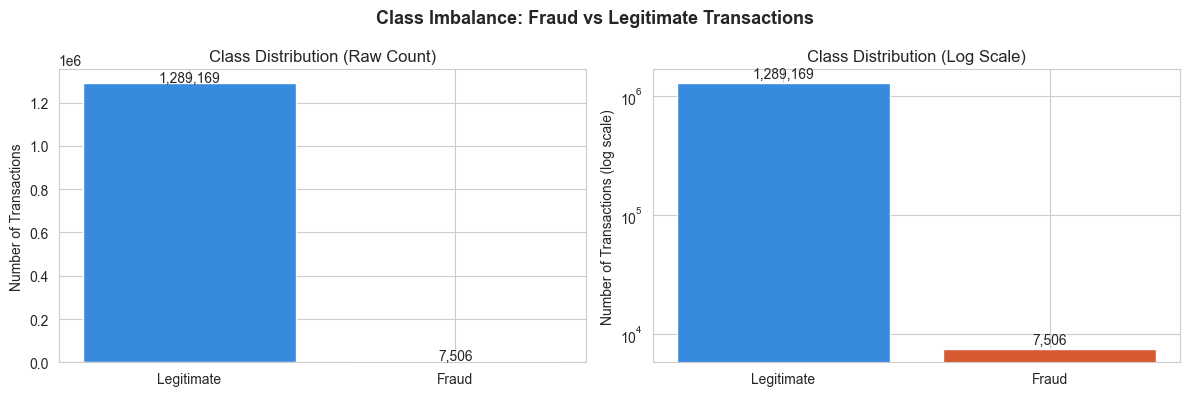

Chart saved: chart_class_imbalance.png


In [20]:
fraud_counts = train['is_fraud'].value_counts()        # count fraud and legitimate
fraud_rate   = fraud_counts[1] / len(train) * 100      # fraud percentage

print("Class distribution in training set:")
print()
print(f"  Legitimate (0):  {fraud_counts[0]:,}   ({100 - fraud_rate:.3f}%)")
print(f"  Fraud      (1):  {fraud_counts[1]:,}   ({fraud_rate:.3f}%)")
print(f"  Imbalance ratio: 1 fraud for every {fraud_counts[0]//fraud_counts[1]:,} legitimate transactions")
print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))        # create 2 side by side charts

# left chart: raw counts
axes[0].bar(['Legitimate', 'Fraud'],
            [fraud_counts[0], fraud_counts[1]],
            color=['#378ADD', '#D85A30'])               # blue for legit, orange for fraud
axes[0].set_title('Class Distribution (Raw Count)')
axes[0].set_ylabel('Number of Transactions')
for i, v in enumerate([fraud_counts[0], fraud_counts[1]]):
    axes[0].text(i, v + 5000, f'{v:,}',
                 ha='center', fontsize=10)              # add count labels on bars

# right chart: log scale so fraud bar is visible
axes[1].bar(['Legitimate', 'Fraud'],
            [fraud_counts[0], fraud_counts[1]],
            color=['#378ADD', '#D85A30'])
axes[1].set_title('Class Distribution (Log Scale)')
axes[1].set_ylabel('Number of Transactions (log scale)')
axes[1].set_yscale('log')                              # log scale makes fraud bar visible
for i, v in enumerate([fraud_counts[0], fraud_counts[1]]):
    axes[1].text(i, v * 1.1, f'{v:,}',
                 ha='center', fontsize=10)

plt.suptitle('Class Imbalance: Fraud vs Legitimate Transactions',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_class_imbalance.png', dpi=CHART_DPI,
            bbox_inches='tight')                       # save chart to file
plt.show()
print("Chart saved: chart_class_imbalance.png")

## 2.6 Transaction Amount Analysis

Compares the transaction amount for fraud vs legitimate transactions. Amounts above the display cap are excluded from the charts only, so the histogram is not dominated by a handful of large outliers.

Transaction amount statistics:

  Overall mean amount:      $     70.35
  Overall median amount:    $     47.52
  Overall max amount:       $  28948.90

  Legitimate mean amount:   $     67.67
  Fraud mean amount:        $    531.32

  Legitimate median amount: $     47.28
  Fraud median amount:      $    396.50


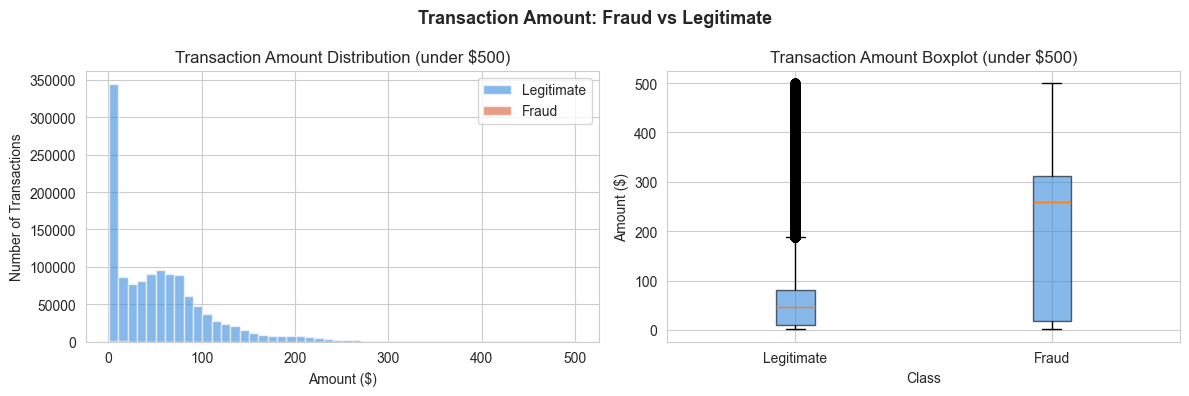

Chart saved: chart_amount_analysis.png


In [21]:
print("Transaction amount statistics:")
print()
print(f"  Overall mean amount:      ${train['amt'].mean():>10.2f}")
print(f"  Overall median amount:    ${train['amt'].median():>10.2f}")
print(f"  Overall max amount:       ${train['amt'].max():>10.2f}")
print()

legit_amt = train[train['is_fraud']==0]['amt']   # amounts for legitimate transactions
fraud_amt = train[train['is_fraud']==1]['amt']   # amounts for fraudulent transactions

print(f"  Legitimate mean amount:   ${legit_amt.mean():>10.2f}")
print(f"  Fraud mean amount:        ${fraud_amt.mean():>10.2f}")
print()
print(f"  Legitimate median amount: ${legit_amt.median():>10.2f}")
print(f"  Fraud median amount:      ${fraud_amt.median():>10.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left chart: distribution of amounts for both classes
axes[0].hist(legit_amt[legit_amt < AMOUNT_DISPLAY_CAP],
             bins=50, alpha=0.6,
             color='#378ADD', label='Legitimate')       # legitimate histogram
axes[0].hist(fraud_amt[fraud_amt < AMOUNT_DISPLAY_CAP],
             bins=50, alpha=0.6,
             color='#D85A30', label='Fraud')            # fraud histogram
axes[0].set_title('Transaction Amount Distribution (under $500)')
axes[0].set_xlabel('Amount ($)')
axes[0].set_ylabel('Number of Transactions')
axes[0].legend()

# right chart: boxplot comparison
axes[1].boxplot([legit_amt[legit_amt < AMOUNT_DISPLAY_CAP],
                 fraud_amt[fraud_amt < AMOUNT_DISPLAY_CAP]],
                labels=['Legitimate', 'Fraud'],
                patch_artist=True,
                boxprops=dict(facecolor='#378ADD', alpha=0.6))  # filled boxes
axes[1].set_title('Transaction Amount Boxplot (under $500)')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Amount ($)')

plt.suptitle('Transaction Amount: Fraud vs Legitimate',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_amount_analysis.png', dpi=CHART_DPI,
            bbox_inches='tight')                        # save chart
plt.show()
print("Chart saved: chart_amount_analysis.png")

## 2.7 Fraud Rate by Merchant Category

Fraud rate by merchant category:

  Category                       Total    Fraud   Fraud Rate

  shopping_net                  97,543    1,713       1.756%
  misc_net                      63,287      915       1.446%
  grocery_pos                  123,638    1,743       1.410%
  shopping_pos                 116,672      843       0.723%
  gas_transport                131,659      618       0.469%
  misc_pos                      79,655      250       0.314%
  grocery_net                   45,452      134       0.295%
  travel                        40,507      116       0.286%
  entertainment                 94,014      233       0.248%
  personal_care                 90,758      220       0.242%
  kids_pets                    113,035      239       0.211%
  food_dining                   91,461      151       0.165%
  home                         123,115      198       0.161%
  health_fitness                85,879      133       0.155%


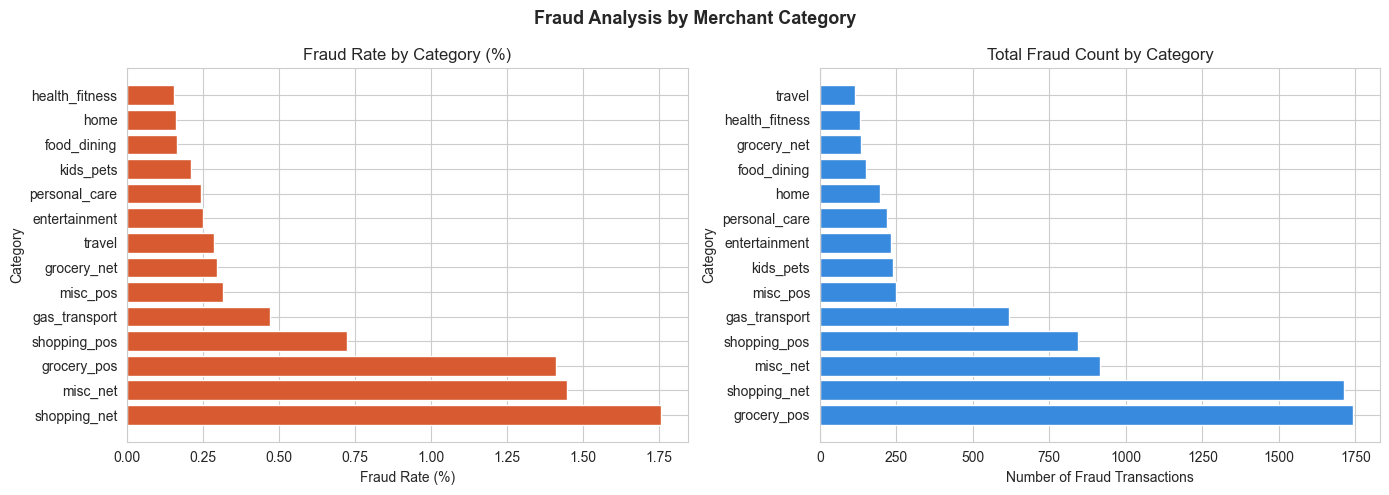

Chart saved: chart_fraud_by_category.png


In [22]:
category_stats = train.groupby('category')['is_fraud'].agg(
    total='count',                                      # total transactions per category
    fraud_count='sum',                                  # fraud transactions per category
    fraud_rate='mean'                                   # fraud rate per category
).reset_index()

category_stats['fraud_rate_pct'] = (
    category_stats['fraud_rate'] * 100                 # convert to percentage
).round(3)

category_stats = category_stats.sort_values(
    'fraud_rate_pct', ascending=False                  # sort by highest fraud rate
)

print("Fraud rate by merchant category:")
print()
print(f"  {'Category':<25} {'Total':>10} {'Fraud':>8} {'Fraud Rate':>12}")
print()
for _, row in category_stats.iterrows():
    print(f"  {row['category']:<25} {row['total']:>10,} "
          f"{row['fraud_count']:>8,} {row['fraud_rate_pct']:>11.3f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(
    category_stats['category'],
    category_stats['fraud_rate_pct'],
    color='#D85A30')
axes[0].set_title('Fraud Rate by Category (%)')
axes[0].set_xlabel('Fraud Rate (%)')
axes[0].set_ylabel('Category')

category_fraud = category_stats.sort_values(
    'fraud_count', ascending=False)

axes[1].barh(
    category_fraud['category'],
    category_fraud['fraud_count'],
    color='#378ADD')
axes[1].set_title('Total Fraud Count by Category')
axes[1].set_xlabel('Number of Fraud Transactions')
axes[1].set_ylabel('Category')

plt.suptitle('Fraud Analysis by Merchant Category',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_fraud_by_category.png', dpi=CHART_DPI,
            bbox_inches='tight')
plt.show()
print("Chart saved: chart_fraud_by_category.png")

## 2.8 Fraud Rate by Gender

Fraud rate by gender:

  Gender          Total    Fraud   Fraud Rate

  F             709,863    3,735       0.526%
  M             586,812    3,771       0.643%


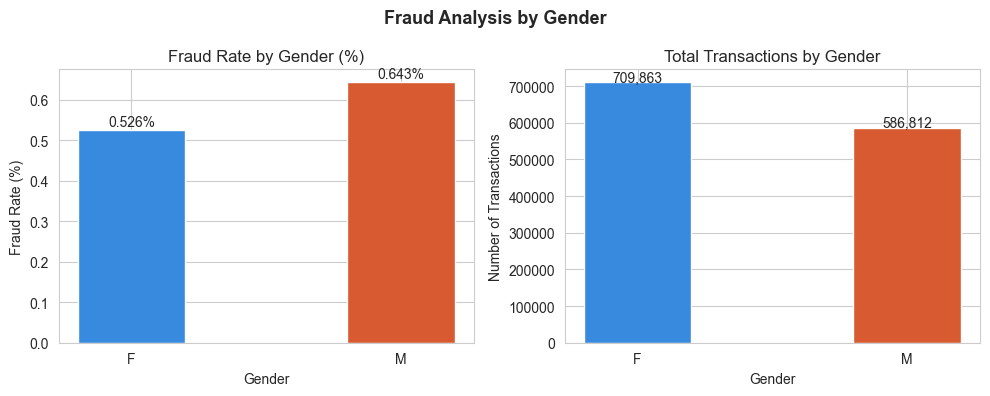

Chart saved: chart_fraud_by_gender.png


In [23]:
gender_stats = train.groupby('gender')['is_fraud'].agg(
    total='count',                                     # total transactions per gender
    fraud_count='sum',                                 # fraud count per gender
    fraud_rate='mean'                                  # fraud rate per gender
).reset_index()

gender_stats['fraud_rate_pct'] = (
    gender_stats['fraud_rate'] * 100                  # convert to percentage
).round(3)

print("Fraud rate by gender:")
print()
print(f"  {'Gender':<10} {'Total':>10} {'Fraud':>8} {'Fraud Rate':>12}")
print()
for _, row in gender_stats.iterrows():
    print(f"  {row['gender']:<10} {row['total']:>10,} "
          f"{row['fraud_count']:>8,} {row['fraud_rate_pct']:>11.3f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# left chart: fraud rate by gender
axes[0].bar(
    gender_stats['gender'],
    gender_stats['fraud_rate_pct'],
    color=['#378ADD', '#D85A30'],                     # different colour per gender
    width=0.4)
axes[0].set_title('Fraud Rate by Gender (%)')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Fraud Rate (%)')
for i, v in enumerate(gender_stats['fraud_rate_pct']):
    axes[0].text(i, v + 0.01, f'{v:.3f}%',
                 ha='center', fontsize=10)            # add labels on bars

# right chart: total transactions by gender
axes[1].bar(
    gender_stats['gender'],
    gender_stats['total'],
    color=['#378ADD', '#D85A30'],
    width=0.4)
axes[1].set_title('Total Transactions by Gender')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Number of Transactions')
for i, v in enumerate(gender_stats['total']):
    axes[1].text(i, v + 1000, f'{v:,}',
                 ha='center', fontsize=10)            # add labels on bars

plt.suptitle('Fraud Analysis by Gender',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_fraud_by_gender.png', dpi=CHART_DPI,
            bbox_inches='tight')                      # save chart
plt.show()
print("Chart saved: chart_fraud_by_gender.png")

## 2.9 Fraud Patterns Over Time

Extracts the month from each transaction timestamp and tracks how the fraud rate moves across the full 24 month period. This is the first indication of the concept drift examined more closely later.

Monthly fraud rate over time:

  Month             Total    Fraud   Fraud Rate

  2019-01          52,525      506       0.963%
  2019-02          49,866      517       1.037%
  2019-03          70,939      494       0.696%
  2019-04          68,078      376       0.552%
  2019-05          72,532      408       0.563%
  2019-06          86,064      354       0.411%
  2019-07          86,596      331       0.382%
  2019-08          87,359      382       0.437%
  2019-09          70,652      418       0.592%
  2019-10          68,758      454       0.660%
  2019-11          70,421      388       0.551%
  2019-12         141,060      592       0.420%
  2020-01          52,202      343       0.657%
  2020-02          47,791      336       0.703%
  2020-03          72,850      444       0.609%
  2020-04          66,892      302       0.451%
  2020-05          74,343      527       0.709%
  2020-06          57,747      334       0.578%


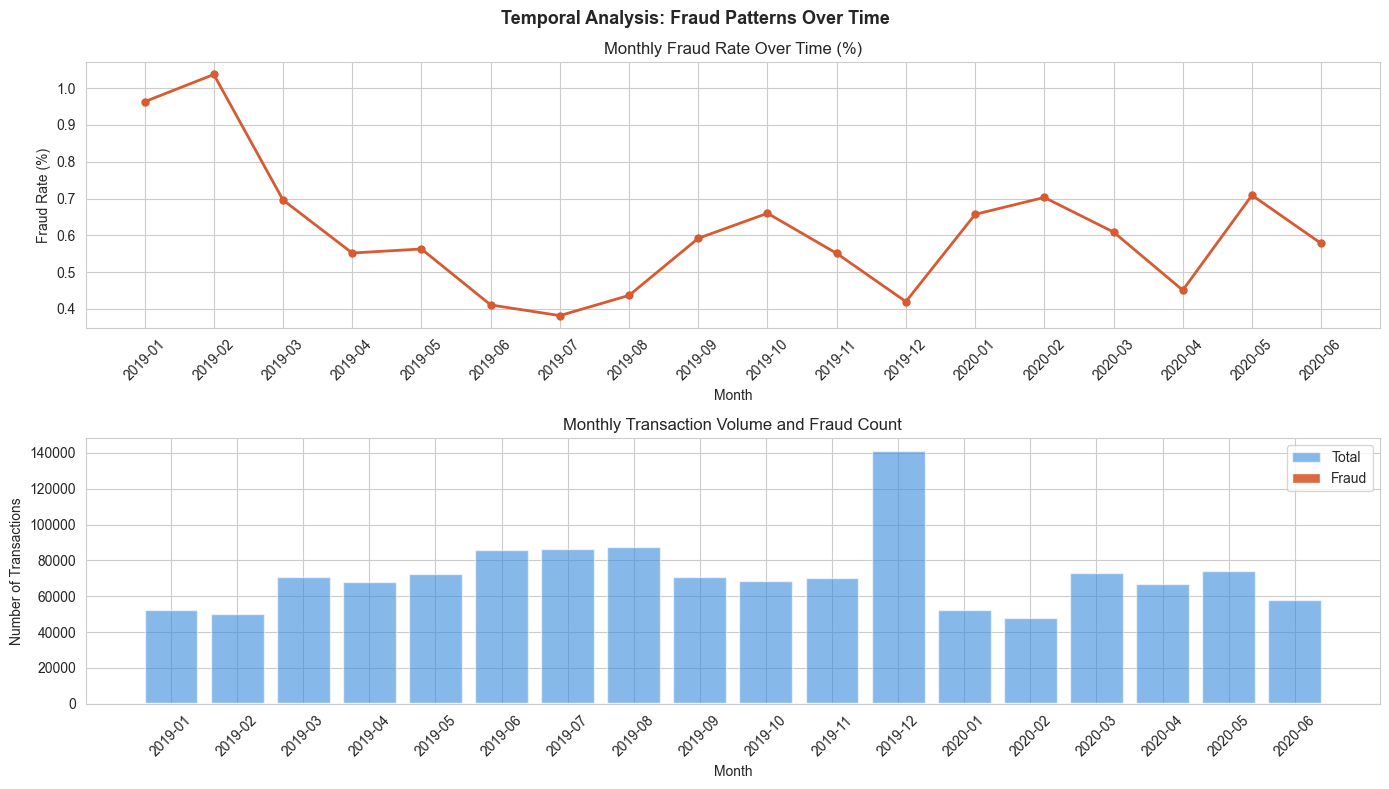

Chart saved: chart_temporal_analysis.png


In [24]:
# work on a local copy: this temporary 'month' column should not
# leak forward into train, which is reused again later in Part 2.12
# and in Part 3
train_time = train.copy()
train_time['trans_date_trans_time'] = pd.to_datetime(
    train_time['trans_date_trans_time']                # convert to datetime format
)

train_time['month'] = train_time['trans_date_trans_time'].dt.to_period('M')  # extract month

monthly = train_time.groupby('month')['is_fraud'].agg(
    total='count',                                     # total transactions per month
    fraud_count='sum',                                 # fraud count per month
    fraud_rate='mean'                                  # fraud rate per month
).reset_index()

monthly['fraud_rate_pct'] = (
    monthly['fraud_rate'] * 100                        # convert to percentage
).round(3)

monthly['month_str'] = monthly['month'].astype(str)   # convert period to string for plotting

print("Monthly fraud rate over time:")
print()
print(f"  {'Month':<12} {'Total':>10} {'Fraud':>8} {'Fraud Rate':>12}")
print()
for _, row in monthly.iterrows():
    print(f"  {row['month_str']:<12} {row['total']:>10,} "
          f"{row['fraud_count']:>8,} {row['fraud_rate_pct']:>11.3f}%")

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# top chart: fraud rate over time
axes[0].plot(
    monthly['month_str'],
    monthly['fraud_rate_pct'],
    marker='o', color='#D85A30',
    linewidth=2, markersize=5)                         # line chart with markers
axes[0].set_title('Monthly Fraud Rate Over Time (%)')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Fraud Rate (%)')
axes[0].tick_params(axis='x', rotation=45)            # rotate x labels for readability

# bottom chart: total transactions and fraud count over time
axes[1].bar(
    monthly['month_str'],
    monthly['total'],
    color='#378ADD', alpha=0.6, label='Total')         # total transactions bars
axes[1].bar(
    monthly['month_str'],
    monthly['fraud_count'],
    color='#D85A30', alpha=0.9, label='Fraud')         # fraud count bars on top
axes[1].set_title('Monthly Transaction Volume and Fraud Count')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Number of Transactions')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.suptitle('Temporal Analysis: Fraud Patterns Over Time',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_temporal_analysis.png', dpi=CHART_DPI,
            bbox_inches='tight')                       # save chart
plt.show()
print("Chart saved: chart_temporal_analysis.png")

## 2.10 Census Feature Distributions

Checks whether the six socioeconomic variables added in Part 1 look different between fraud and legitimate transactions.

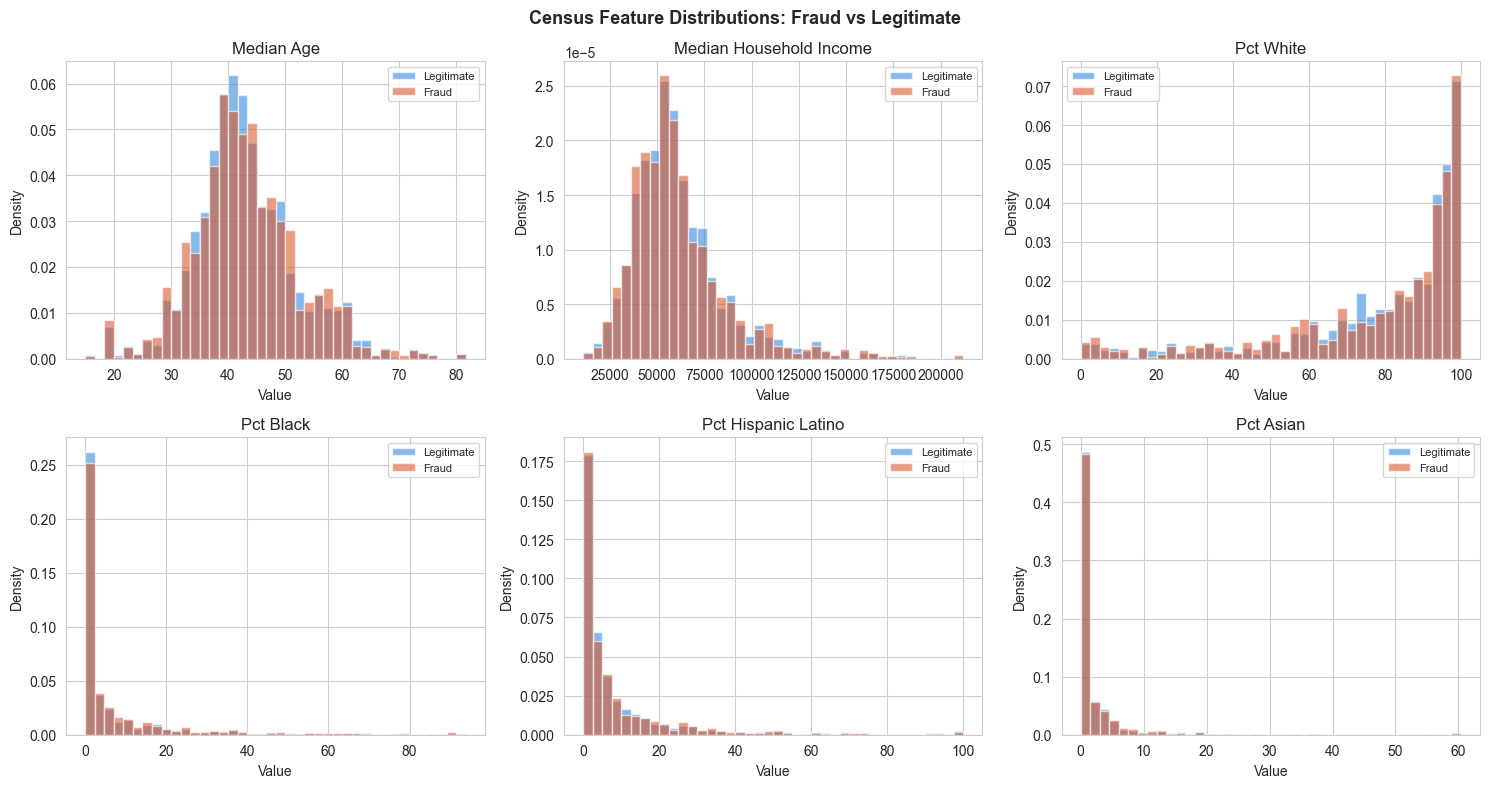

Census feature summary (fraud vs legitimate):

  Feature                          Legitimate        Fraud   Difference

  median_age                            43.14        43.17        +0.03
  median_household_income            61362.30     60842.31      -519.99
  pct_white                             78.33        77.55        -0.78
  pct_black                              7.47         7.87        +0.40
  pct_hispanic_latino                    8.61         8.58        -0.03
  pct_asian                              1.93         2.09        +0.17

Chart saved: chart_census_distributions.png


In [25]:
census_cols = ['median_age', 'median_household_income',
               'pct_white', 'pct_black',
               'pct_hispanic_latino', 'pct_asian']     # Census columns to visualise

fig, axes = plt.subplots(2, 3, figsize=(15, 8))        # 2 rows 3 columns of charts
axes = axes.flatten()                                   # flatten to loop through easily

for i, col in enumerate(census_cols):
    legit = train[train['is_fraud']==0][col].dropna()  # legitimate values
    fraud = train[train['is_fraud']==1][col].dropna()  # fraud values

    axes[i].hist(legit, bins=40, alpha=0.6,
                 color='#378ADD', label='Legitimate',
                 density=True)                         # normalised histogram
    axes[i].hist(fraud, bins=40, alpha=0.6,
                 color='#D85A30', label='Fraud',
                 density=True)
    axes[i].set_title(col.replace('_', ' ').title())   # readable title
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Density')
    axes[i].legend(fontsize=8)

plt.suptitle('Census Feature Distributions: Fraud vs Legitimate',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_census_distributions.png', dpi=CHART_DPI,
            bbox_inches='tight')                       # save chart
plt.show()

print("Census feature summary (fraud vs legitimate):")
print()
print(f"  {'Feature':<30} {'Legitimate':>12} {'Fraud':>12} {'Difference':>12}")
print()
for col in census_cols:
    legit_mean = train[train['is_fraud']==0][col].mean()
    fraud_mean = train[train['is_fraud']==1][col].mean()
    diff       = fraud_mean - legit_mean
    print(f"  {col:<30} {legit_mean:>12.2f} {fraud_mean:>12.2f} {diff:>+12.2f}")

print()
print("Chart saved: chart_census_distributions.png")

## 2.11 Correlation Analysis

A correlation heatmap across all numeric features, with a ranking of which features correlate most strongly with `is_fraud`.

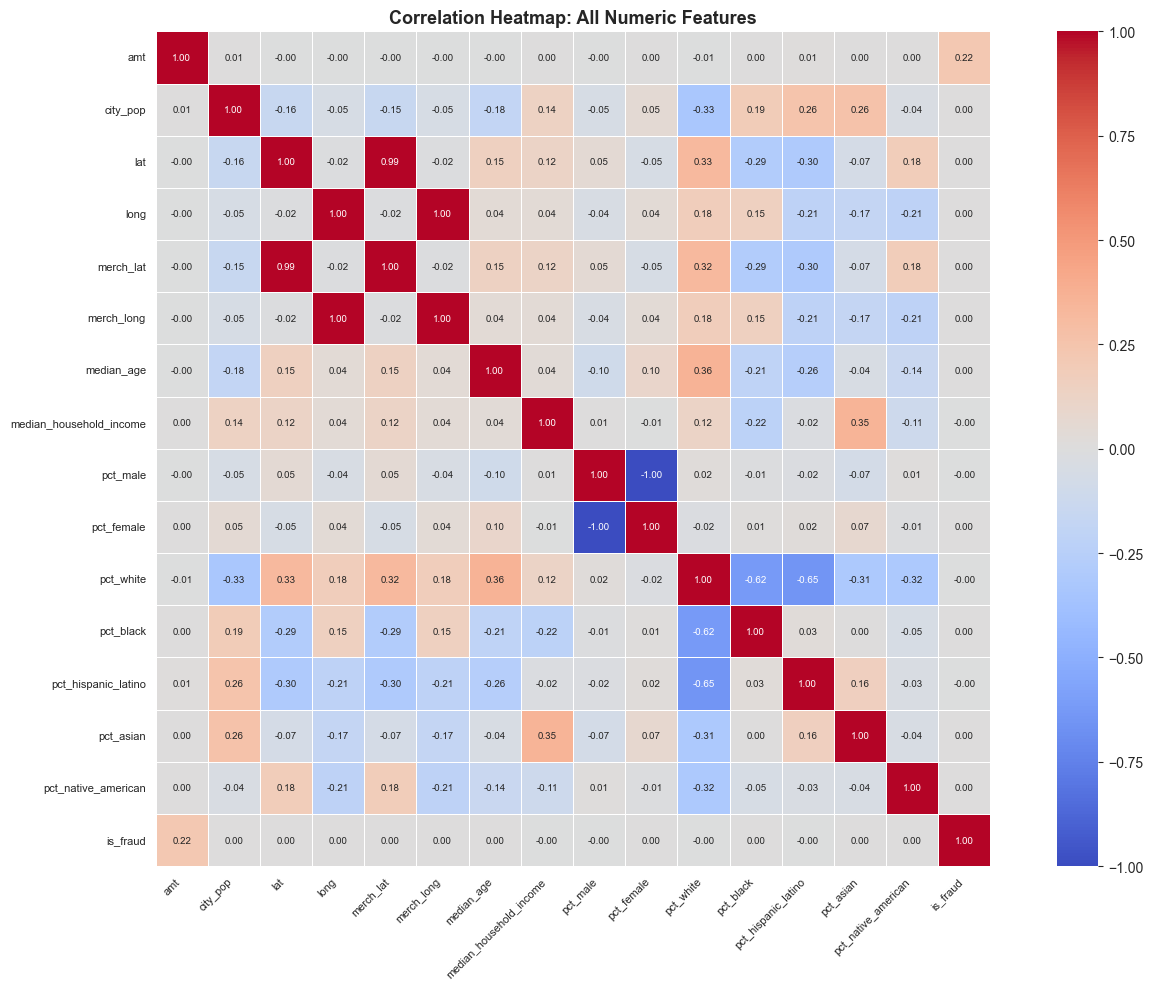

Top correlations with is_fraud:

  amt                              0.2194  (positive)
  pct_asian                        0.0026  (positive)
  pct_white                       -0.0024  (negative)
  city_pop                         0.0021  (positive)
  pct_black                        0.0020  (positive)
  lat                              0.0019  (positive)
  merch_lat                        0.0017  (positive)
  merch_long                       0.0017  (positive)
  long                             0.0017  (positive)
  median_household_income         -0.0015  (negative)
  pct_native_american              0.0010  (positive)
  median_age                       0.0002  (positive)
  pct_hispanic_latino             -0.0001  (negative)
  pct_female                       0.0001  (positive)
  pct_male                        -0.0001  (negative)

Chart saved: chart_correlation_heatmap.png


In [26]:
numeric_cols = ['amt', 'city_pop', 'lat', 'long',
                'merch_lat', 'merch_long',
                'median_age', 'median_household_income',
                'pct_male', 'pct_female',
                'pct_white', 'pct_black',
                'pct_hispanic_latino', 'pct_asian',
                'pct_native_american', 'is_fraud']

corr_matrix = train[numeric_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={'size': 7}
)
plt.title('Correlation Heatmap: All Numeric Features',
          fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig('chart_correlation_heatmap.png', dpi=CHART_DPI, bbox_inches='tight')
plt.show()

print("Top correlations with is_fraud:")
print()  
fraud_corr = corr_matrix['is_fraud'].drop('is_fraud')
fraud_corr_abs = fraud_corr.abs().sort_values(ascending=False)

for col in fraud_corr_abs.index:
    val = corr_matrix['is_fraud'][col]
    direction = "positive" if val > 0 else "negative"
    print(f"  {col:<30} {val:>8.4f}  ({direction})")

print()
print("Chart saved: chart_correlation_heatmap.png")

## 2.12 Concept Drift: Training vs Test Period

Directly compares the monthly fraud rate in the training period against the test period. This is the core evidence for the concept drift referenced throughout this dissertation.

Monthly fraud rate across full dataset (train + test):

  Month        Period        Total    Fraud   Fraud Rate

  2019-01      Train        52,525      506       0.963%
  2019-02      Train        49,866      517       1.037%
  2019-03      Train        70,939      494       0.696%
  2019-04      Train        68,078      376       0.552%
  2019-05      Train        72,532      408       0.563%
  2019-06      Train        86,064      354       0.411%
  2019-07      Train        86,596      331       0.382%
  2019-08      Train        87,359      382       0.437%
  2019-09      Train        70,652      418       0.592%
  2019-10      Train        68,758      454       0.660%
  2019-11      Train        70,421      388       0.551%
  2019-12      Train       141,060      592       0.420%
  2020-01      Train        52,202      343       0.657%
  2020-02      Train        47,791      336       0.703%
  2020-03      Train        72,850      444       0.609%
  2020-04      Train        66,

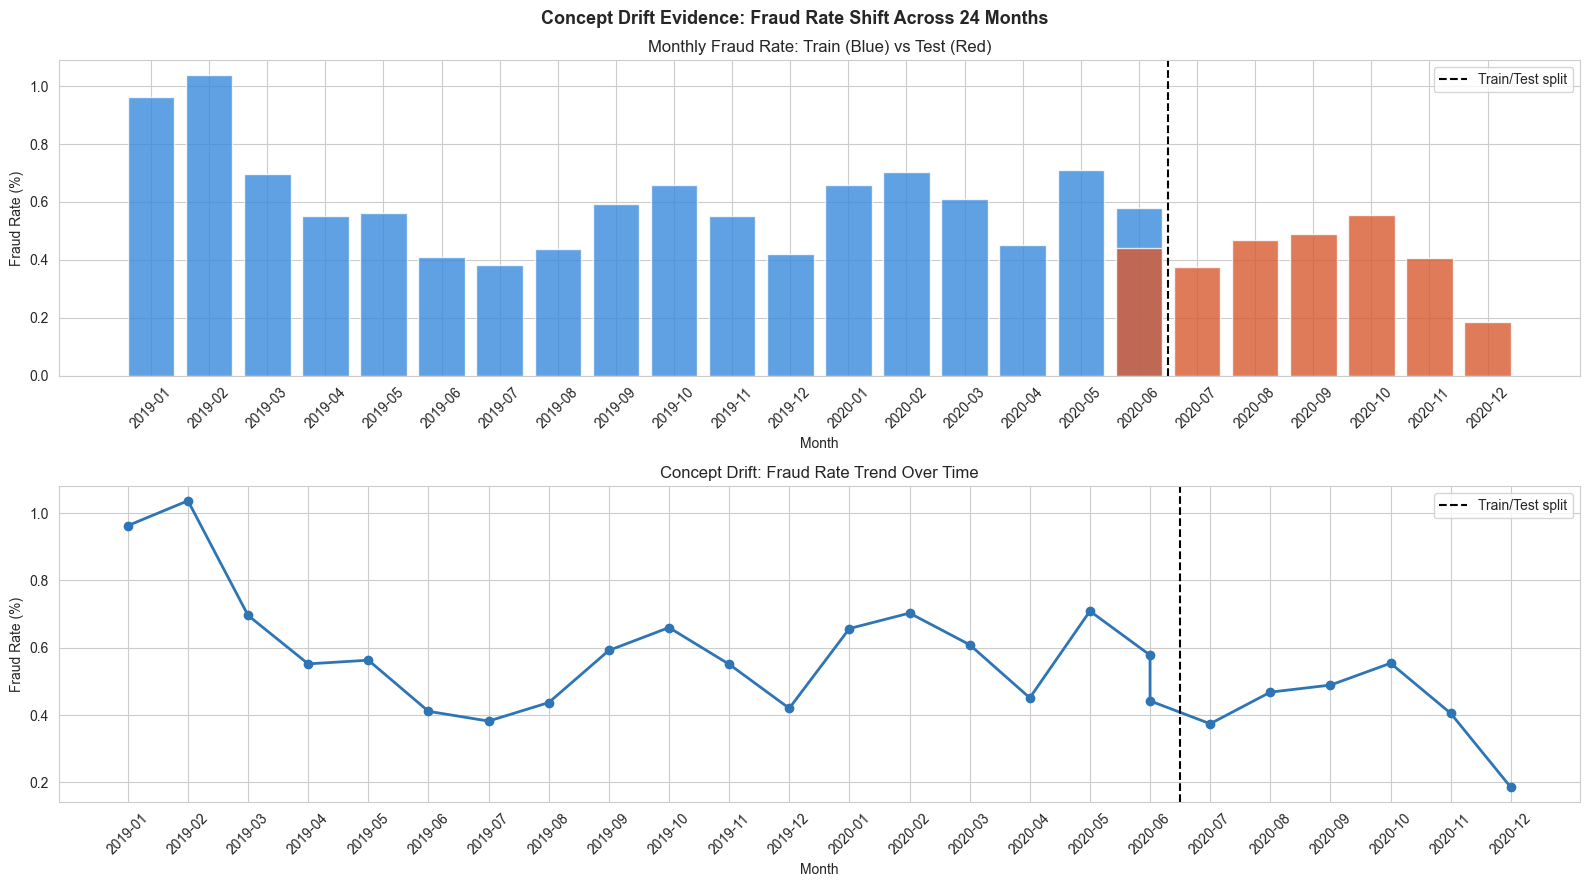


Concept drift summary:

  Highest fraud rate: 1.037% in 2019-02
  Lowest fraud rate:  0.185% in 2020-12
  Range of variation: 0.852 percentage points
  Train avg rate:     0.609%
  Test avg rate:      0.417%
  Drift between periods: 0.193 percentage points

Chart saved: chart_concept_drift.png


In [27]:
# work on local copies rather than mutating train/test directly:
# these variables are reused later in Part 3, and a temporary
# 'month' column here should not leak forward into preprocessing
train_temporal = train.copy()
test_temporal  = test.copy()

train_temporal['trans_date_trans_time'] = pd.to_datetime(
    train_temporal['trans_date_trans_time']             # ensure datetime format
)
test_temporal['trans_date_trans_time'] = pd.to_datetime(
    test_temporal['trans_date_trans_time']              # same for test set
)

train_temporal['month'] = train_temporal[
    'trans_date_trans_time'].dt.to_period('M')         # extract month from train
test_temporal['month']  = test_temporal[
    'trans_date_trans_time'].dt.to_period('M')         # extract month from test

train_monthly = train_temporal.groupby('month')['is_fraud'].agg(
    total='count',
    fraud_count='sum',
    fraud_rate='mean'
).reset_index()
train_monthly['fraud_rate_pct'] = (
    train_monthly['fraud_rate'] * 100).round(3)
train_monthly['period'] = 'Train'                      # label as training period

test_monthly = test_temporal.groupby('month')['is_fraud'].agg(
    total='count',
    fraud_count='sum',
    fraud_rate='mean'
).reset_index()
test_monthly['fraud_rate_pct'] = (
    test_monthly['fraud_rate'] * 100).round(3)
test_monthly['period'] = 'Test'                        # label as test period

all_monthly = pd.concat(
    [train_monthly, test_monthly],
    ignore_index=True                                  # combine train and test monthly data
)
all_monthly['month_str'] = all_monthly['month'].astype(str)

print("Monthly fraud rate across full dataset (train + test):")
print()
print(f"  {'Month':<12} {'Period':<8} {'Total':>10} "
      f"{'Fraud':>8} {'Fraud Rate':>12}")
print()
for _, row in all_monthly.iterrows():
    print(f"  {row['month_str']:<12} {row['period']:<8} "
          f"{row['total']:>10,} {row['fraud_count']:>8,} "
          f"{row['fraud_rate_pct']:>11.3f}%")

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

colors = all_monthly['period'].map(
    {'Train': '#378ADD', 'Test': '#D85A30'}            # blue for train red for test
)

axes[0].bar(
    all_monthly['month_str'],
    all_monthly['fraud_rate_pct'],
    color=colors, alpha=0.8)                           # bar per month coloured by period
axes[0].set_title(
    'Monthly Fraud Rate: Train (Blue) vs Test (Red)')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Fraud Rate (%)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].axvline(x=17.5, color='black',
                linestyle='--', linewidth=1.5,
                label='Train/Test split')              # vertical line at split point
axes[0].legend()

axes[1].plot(
    all_monthly['month_str'],
    all_monthly['fraud_rate_pct'],
    marker='o', color='#2E75B6',
    linewidth=2, markersize=6)                         # line chart of fraud rate
axes[1].set_title('Concept Drift: Fraud Rate Trend Over Time')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].axvline(x=17.5, color='black',
                linestyle='--', linewidth=1.5,
                label='Train/Test split')
axes[1].legend()

plt.suptitle(
    'Concept Drift Evidence: Fraud Rate Shift Across 24 Months',
    fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_concept_drift.png', dpi=CHART_DPI,
            bbox_inches='tight')                       # save chart
plt.show()

max_rate  = all_monthly['fraud_rate_pct'].max()
min_rate  = all_monthly['fraud_rate_pct'].min()
max_month = all_monthly.loc[
    all_monthly['fraud_rate_pct'].idxmax(), 'month_str']
min_month = all_monthly.loc[
    all_monthly['fraud_rate_pct'].idxmin(), 'month_str']

print()
print("Concept drift summary:")
print()
print(f"  Highest fraud rate: {max_rate:.3f}% in {max_month}")
print(f"  Lowest fraud rate:  {min_rate:.3f}% in {min_month}")
print(f"  Range of variation: {max_rate - min_rate:.3f} percentage points")
print(f"  Train avg rate:     "
      f"{train_monthly['fraud_rate_pct'].mean():.3f}%")
print(f"  Test avg rate:      "
      f"{test_monthly['fraud_rate_pct'].mean():.3f}%")
print(f"  Drift between periods: "
      f"{abs(train_monthly['fraud_rate_pct'].mean() - test_monthly['fraud_rate_pct'].mean()):.3f} "
      f"percentage points")
print()
print("Chart saved: chart_concept_drift.png")

## 2.13 Geographic Distribution of Transactions and Fraud

The dataset carries transaction level coordinates (`merch_lat`, `merch_long`) and a two letter US state code for every customer. Both are dropped later in Part 3 once the Census enrichment and the engineered `distance` feature have captured the geographic signal they contain, so this is the only point in the notebook where they are mapped directly.

Two maps are produced. The first is a choropleth showing the fraud rate for each state, shaded from light to dark and labelled with the state code and its rate. Alaska and Hawaii are drawn as insets, since plotting them in their true positions would stretch the map far beyond the continental United States, and the small north eastern states are labelled in a column to the right because they are too small to hold a readable label inside their own borders. The second map plots a sample of individual transaction coordinates over the same state outlines, showing where transactions occur and where fraud falls within that spread.

State boundaries are read from a standard GeoJSON file, downloaded once and cached locally, so both maps are drawn using matplotlib alone and need no mapping library or browser based image renderer.


Building geographic visualisations...

Excluded 1 state(s) with fewer than 500 transactions (rate too noisy to be meaningful): DE

Fraud rate by state (10 highest, reliable states only):

  RI      2.727%   (15 of 550 transactions)
  AK      1.698%   (36 of 2,120 transactions)
  NV      0.838%   (47 of 5,607 transactions)
  CO      0.814%   (113 of 13,880 transactions)
  OR      0.801%   (149 of 18,597 transactions)
  TN      0.798%   (140 of 17,554 transactions)
  NE      0.745%   (180 of 24,168 transactions)
  ME      0.721%   (119 of 16,505 transactions)
  NH      0.713%   (59 of 8,278 transactions)
  OH      0.691%   (321 of 46,480 transactions)

State boundaries loaded: 52 features.

Drawing choropleth map...


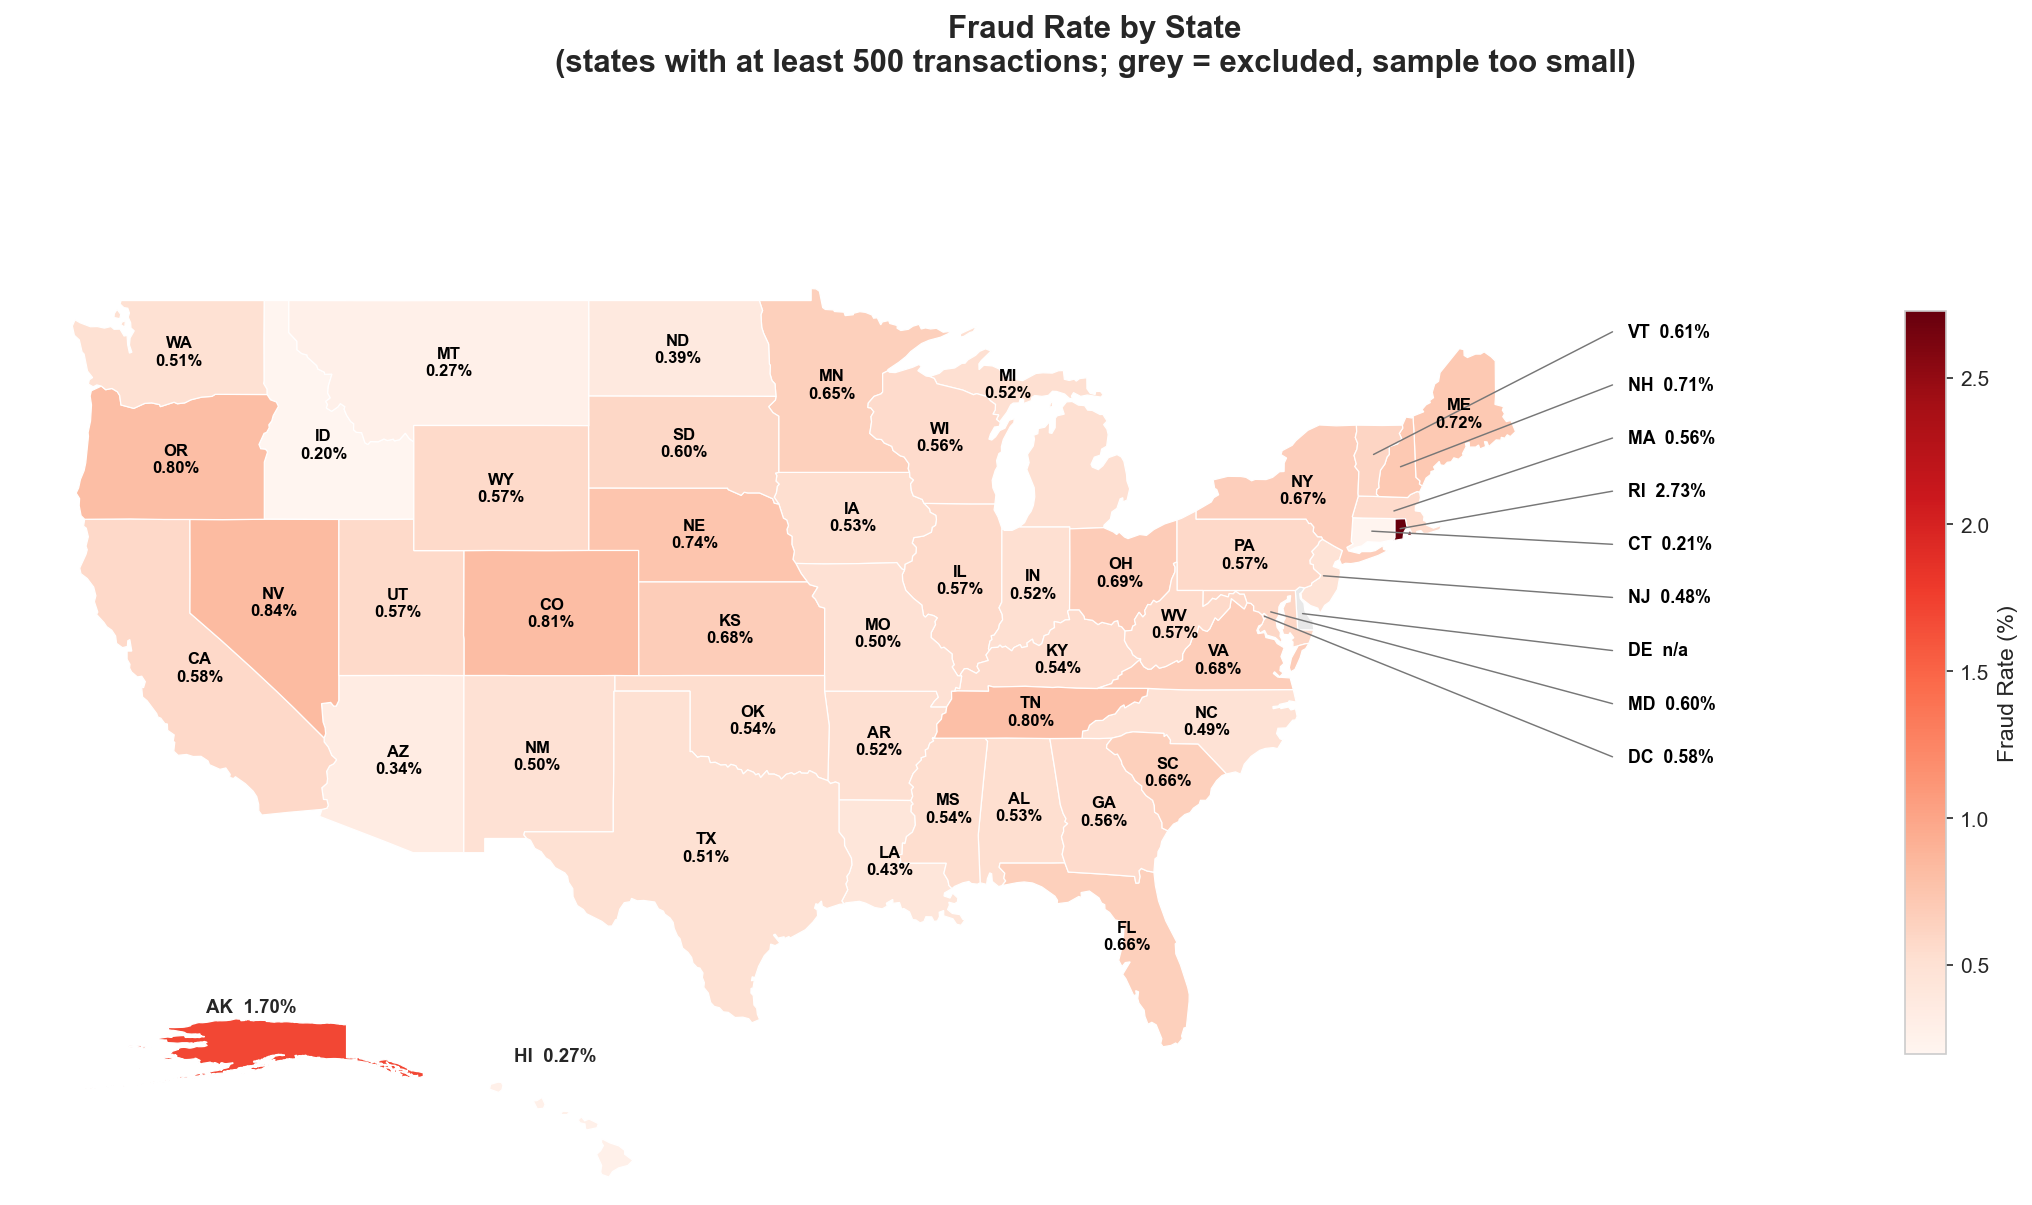

Chart saved: chart_fraud_rate_by_state.png

Drawing transaction location map...


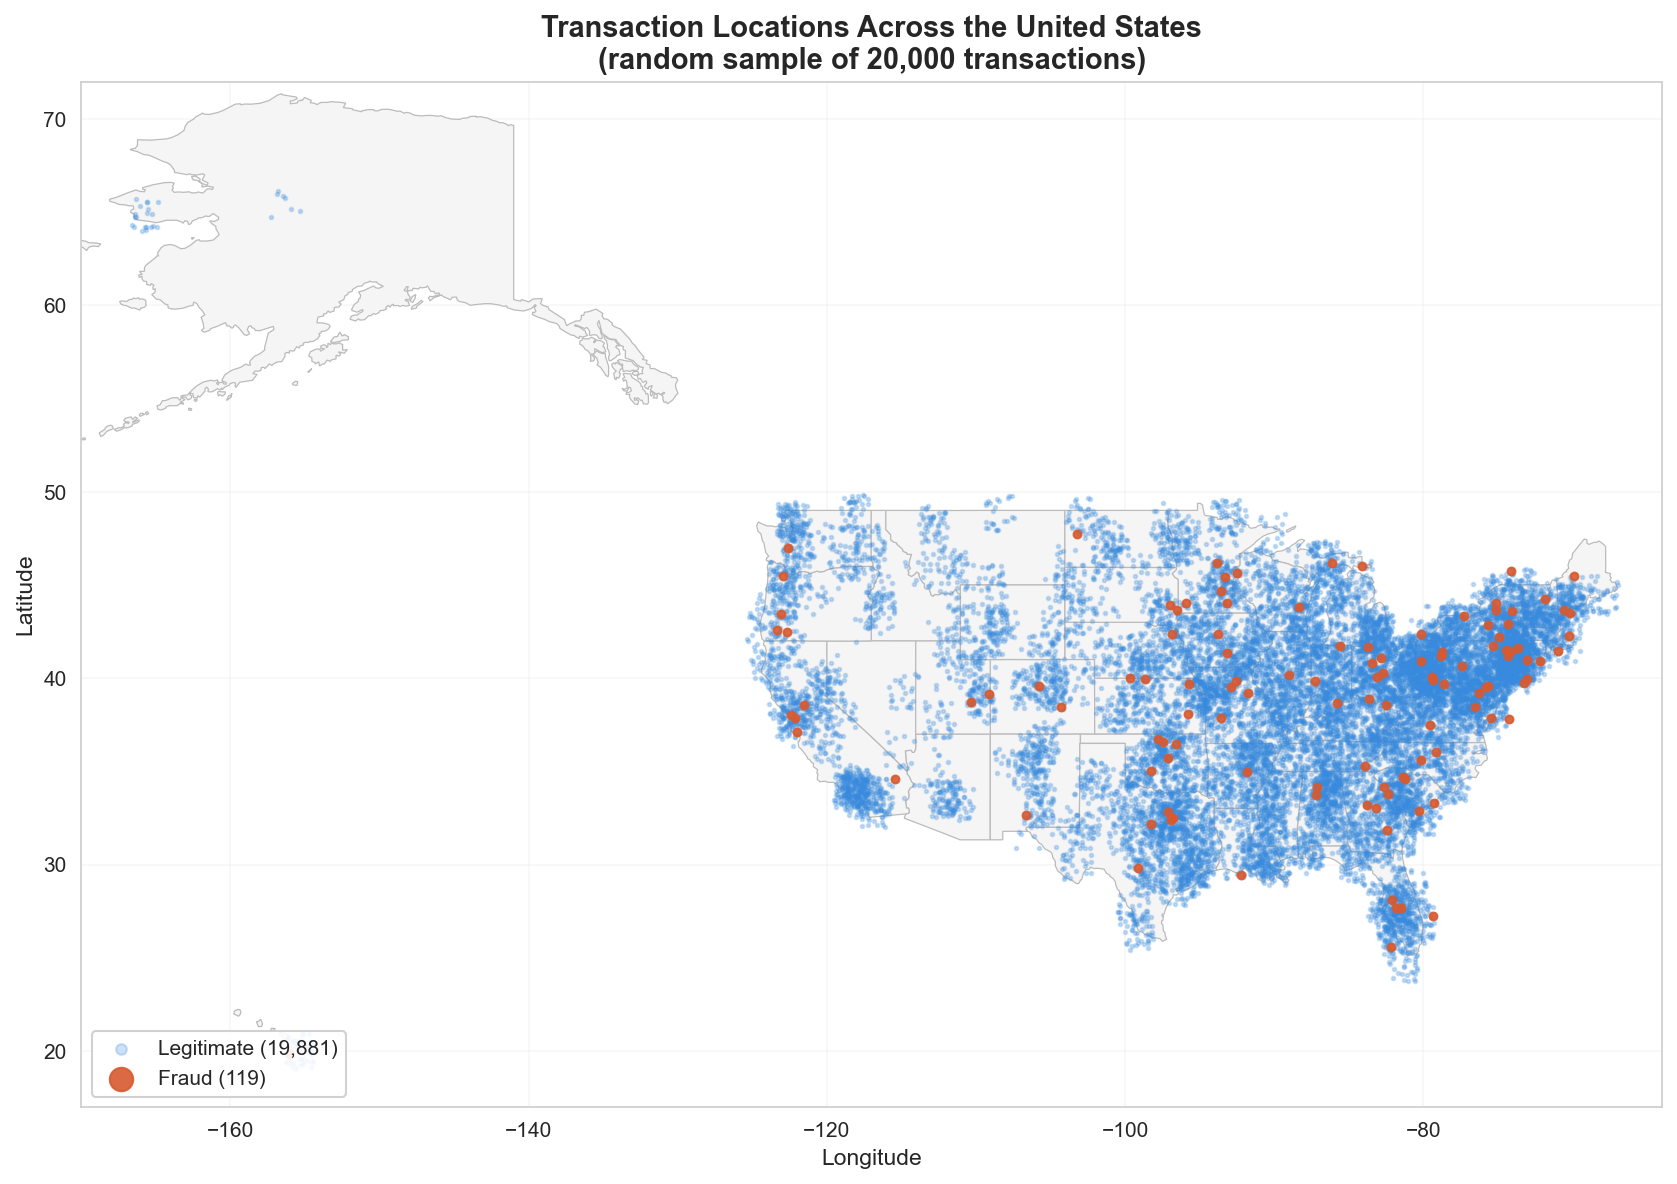

Chart saved: chart_transaction_locations.png


In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import numpy as np
import json
import os
import urllib.request
from IPython.display import Image, display

print("Building geographic visualisations...")
print()

# FRAUD RATE BY STATE
state_fraud = train.groupby('state')['is_fraud'].agg(
    total='count',
    fraud_count='sum',
    fraud_rate='mean'
).reset_index()
state_fraud['fraud_rate_pct'] = (state_fraud['fraud_rate'] * 100).round(3)

# states with very few transactions produce a noisy, unreliable fraud
# rate: a state with only 9 transactions showing "100% fraud" is not a
# genuine hotspot, it is a small sample producing a meaningless number.
# States below this threshold are excluded from the ranking and the map
# so a handful of tiny samples cannot dominate either one.
MIN_STATE_TRANSACTIONS = 500
excluded_states = state_fraud[state_fraud['total'] < MIN_STATE_TRANSACTIONS]
state_fraud_reliable = state_fraud[
    state_fraud['total'] >= MIN_STATE_TRANSACTIONS].copy()

if len(excluded_states) > 0:
    print(f"Excluded {len(excluded_states)} state(s) with fewer than "
          f"{MIN_STATE_TRANSACTIONS} transactions (rate too noisy to be "
          f"meaningful): {', '.join(excluded_states['state'].tolist())}")
    print()

print("Fraud rate by state (10 highest, reliable states only):")
print()
top_states = state_fraud_reliable.sort_values(
    'fraud_rate_pct', ascending=False).head(10)
for _, row in top_states.iterrows():
    print(f"  {row['state']:<4} {row['fraud_rate_pct']:>8.3f}%   "
          f"({row['fraud_count']:,} of {row['total']:,} transactions)")
print()

# STATE BOUNDARY GEOMETRY
# The outlines of the US states are downloaded once as a GeoJSON file
# and cached locally, so the map is drawn with matplotlib alone and
# needs no mapping library or browser based renderer.
GEOJSON_FILE = 'us-states.json'
GEOJSON_URL = ('https://raw.githubusercontent.com/PublicaMundi/'
               'MappingAPI/master/data/geojson/us-states.json')

us_geojson = None
try:
    if not os.path.exists(GEOJSON_FILE):
        print("Downloading US state boundaries (one time only)...")
        urllib.request.urlretrieve(GEOJSON_URL, GEOJSON_FILE)
        print("Download complete.")
        print()
    with open(GEOJSON_FILE) as f:
        us_geojson = json.load(f)
    print(f"State boundaries loaded: "
          f"{len(us_geojson['features'])} features.")
    print()
except Exception as exc:
    print(f"Could not obtain the state boundary file: {exc}")
    print()
    print("The geographic charts below are skipped. Nothing in Parts 3")
    print("onward depends on them. To fix, download this file manually")
    print("and save it next to this notebook as 'us-states.json':")
    print(f"  {GEOJSON_URL}")

if us_geojson is not None:
    STATE_NAME_TO_CODE = {
        'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR',
        'California': 'CA', 'Colorado': 'CO', 'Connecticut': 'CT',
        'Delaware': 'DE', 'District of Columbia': 'DC', 'Florida': 'FL',
        'Georgia': 'GA', 'Hawaii': 'HI', 'Idaho': 'ID', 'Illinois': 'IL',
        'Indiana': 'IN', 'Iowa': 'IA', 'Kansas': 'KS', 'Kentucky': 'KY',
        'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
        'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN',
        'Mississippi': 'MS', 'Missouri': 'MO', 'Montana': 'MT',
        'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH',
        'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY',
        'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH',
        'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA',
        'Rhode Island': 'RI', 'South Carolina': 'SC', 'South Dakota': 'SD',
        'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT',
        'Virginia': 'VA', 'Washington': 'WA', 'West Virginia': 'WV',
        'Wisconsin': 'WI', 'Wyoming': 'WY',
    }


    def polygon_rings(geometry):
        # returns every outer ring of a Polygon or MultiPolygon as a list
        # of (lon, lat) coordinate arrays
        if geometry['type'] == 'Polygon':
            return [np.array(geometry['coordinates'][0])]
        rings = []
        for part in geometry['coordinates']:
            rings.append(np.array(part[0]))
        return rings


    def ring_centroid(ring):
        # centroid of a closed polygon ring using the standard area formula,
        # which sits inside the shape far more reliably than a simple
        # average of the vertices
        x, y = ring[:, 0], ring[:, 1]
        x_next, y_next = np.roll(x, -1), np.roll(y, -1)
        cross = x * y_next - x_next * y
        area = cross.sum() / 2.0
        if abs(area) < 1e-12:
            return x.mean(), y.mean()
        cx = ((x + x_next) * cross).sum() / (6.0 * area)
        cy = ((y + y_next) * cross).sum() / (6.0 * area)
        return cx, cy


    rate_lookup = dict(zip(state_fraud_reliable['state'],
                           state_fraud_reliable['fraud_rate_pct']))

    vmin = state_fraud_reliable['fraud_rate_pct'].min()
    vmax = state_fraud_reliable['fraud_rate_pct'].max()
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.get_cmap('Reds')

    # small states in the north east cannot hold a readable label inside
    # their own borders, so their labels are placed in a column to the
    # right of the map with a thin line pointing back to the state
    OFFSET_LABELS = {
        'VT': (-62.5, 48.0), 'NH': (-62.5, 46.3), 'MA': (-62.5, 44.6),
        'RI': (-62.5, 42.9), 'CT': (-62.5, 41.2), 'NJ': (-62.5, 39.5),
        'DE': (-62.5, 37.8), 'MD': (-62.5, 36.1), 'DC': (-62.5, 34.4),
    }

    print("Drawing choropleth map...")
    fig = plt.figure(figsize=(15, 9))
    ax = fig.add_axes([0.02, 0.05, 0.80, 0.86])       # main continental map
    ax_ak = fig.add_axes([0.045, 0.08, 0.16, 0.24])    # Alaska inset
    ax_hi = fig.add_axes([0.215, 0.08, 0.09, 0.13])    # Hawaii inset


    def draw_state(target_ax, rings, face):
        for ring in rings:
            target_ax.add_patch(mpatches.Polygon(
                ring, closed=True, facecolor=face,
                edgecolor='white', linewidth=0.6))


    for feature in us_geojson['features']:
        name = feature['properties']['name']
        code = STATE_NAME_TO_CODE.get(name)
        if code is None:                                # skips Puerto Rico
            continue

        rings = polygon_rings(feature['geometry'])
        rate = rate_lookup.get(code)
        face = '#E8E8E8' if rate is None else cmap(norm(rate))

        if code == 'AK':
            draw_state(ax_ak, rings, face)
            continue
        if code == 'HI':
            draw_state(ax_hi, rings, face)
            continue

        draw_state(ax, rings, face)

        # label the state, using the largest ring so islands and small
        # outlying parts do not pull the label off the mainland
        largest = max(rings, key=len)
        cx, cy = ring_centroid(largest)
        label = f"{code}\n{rate:.2f}%" if rate is not None else f"{code}\nn/a"

        if code in OFFSET_LABELS:
            lx, ly = OFFSET_LABELS[code]
            ax.plot([cx, lx - 0.6], [cy, ly], color='#777777',
                    linewidth=0.7, zorder=5)
            ax.text(lx, ly, label.replace('\n', '  '),
                    ha='left', va='center', fontsize=8.5,
                    fontweight='bold', color='black', zorder=6)
        else:
            text_colour = 'white' if (
                rate is not None and norm(rate) > 0.62) else 'black'
            ax.text(cx, cy, label, ha='center', va='center',
                    fontsize=8, fontweight='bold',
                    color=text_colour, linespacing=1.2, zorder=6)

    ax.set_xlim(-127, -55)
    ax.set_ylim(23, 51)
    ax.set_aspect(1.25)
    ax.axis('off')

    # Alaska and Hawaii are drawn as insets because their real positions
    # would stretch the map far beyond the continental United States
    for inset_ax, code, xlim, ylim, aspect in [
            (ax_ak, 'AK', (-180, -129), (51, 72), 0.5),
            (ax_hi, 'HI', (-161, -154), (18.5, 22.8), 1.0)]:
        inset_ax.set_xlim(*xlim)
        inset_ax.set_ylim(*ylim)
        inset_ax.set_aspect(aspect)
        inset_ax.axis('off')
        rate = rate_lookup.get(code)
        label = f"{code}  {rate:.2f}%" if rate is not None else f"{code}  n/a"
        inset_ax.set_title(label, fontsize=9, fontweight='bold', pad=2)

    cax = fig.add_axes([0.86, 0.20, 0.018, 0.55])
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label('Fraud Rate (%)', fontsize=11)

    fig.suptitle(
        'Fraud Rate by State\n'
        f'(states with at least {MIN_STATE_TRANSACTIONS} transactions; '
        'grey = excluded, sample too small)',
        fontsize=15, fontweight='bold', y=0.97)

    plt.savefig('chart_fraud_rate_by_state.png',
                dpi=CHART_DPI, bbox_inches='tight')
    plt.close(fig)
    # the saved file is read back and embedded directly in the cell
    # output, which displays reliably in any Jupyter front end and
    # keeps the image in the notebook when it is saved or exported
    display(Image(filename='chart_fraud_rate_by_state.png'))
    print("Chart saved: chart_fraud_rate_by_state.png")
    print()

    # CHART 2: SAMPLE OF TRANSACTION LOCATIONS
    # a sample is used: plotting all 1.29 million points would be far
    # too slow to render and unreadable on a single map
    print("Drawing transaction location map...")
    map_sample = train.sample(
        n=min(20000, len(train)),
        random_state=RANDOM_STATE
    ).copy()

    legit_pts = map_sample[map_sample['is_fraud'] == 0]
    fraud_pts = map_sample[map_sample['is_fraud'] == 1]

    fig, ax = plt.subplots(figsize=(14, 8))

    # the state outlines are drawn underneath the points so the scatter
    # can be read against real geography rather than floating in space
    for feature in us_geojson['features']:
        name = feature['properties']['name']
        if STATE_NAME_TO_CODE.get(name) is None:
            continue
        for ring in polygon_rings(feature['geometry']):
            ax.add_patch(mpatches.Polygon(
                ring, closed=True, facecolor='#F5F5F5',
                edgecolor='#BBBBBB', linewidth=0.6, zorder=1))

    # legitimate transactions first, fraud drawn on top so the rare
    # fraud points are not hidden underneath the majority class
    ax.scatter(legit_pts['merch_long'], legit_pts['merch_lat'],
               s=3, c='#378ADD', alpha=0.25, zorder=2,
               label=f'Legitimate ({len(legit_pts):,})')
    ax.scatter(fraud_pts['merch_long'], fraud_pts['merch_lat'],
               s=14, c='#D85A30', alpha=0.9, zorder=3,
               label=f'Fraud ({len(fraud_pts):,})')

    ax.set_xlabel('Longitude', fontsize=11)
    ax.set_ylabel('Latitude', fontsize=11)
    ax.set_title(
        f'Transaction Locations Across the United States\n'
        f'(random sample of {len(map_sample):,} transactions)',
        fontsize=14, fontweight='bold')
    ax.legend(loc='lower left', markerscale=3, framealpha=0.9)
    ax.set_xlim(-170, -64)
    ax.set_ylim(17, 72)
    ax.set_aspect(1.25)
    ax.grid(True, alpha=0.15)

    plt.tight_layout()
    plt.savefig('chart_transaction_locations.png',
                dpi=CHART_DPI, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename='chart_transaction_locations.png'))
    print("Chart saved: chart_transaction_locations.png")


# Part 3: Data Preprocessing

This part turns the enriched, readable dataset into a numeric matrix a model can be trained on: irrelevant columns are dropped, new features are engineered, missing values are imputed, text columns are encoded, and the training set is rebalanced with SMOTE. The output is `train_preprocessed.csv` and `test_preprocessed.csv`, used throughout Part 4.

## 3.1 Drop Irrelevant Columns

Removes identifiers and plain text columns (card number, names, address, transaction ID) that carry no generalisable fraud signal.

In [29]:
cols_to_drop = [
    'trans_date_trans_time',   # replaced by temporal features later
    'cc_num',                  # card number: identifier not a pattern
    'first',                   # cardholder first name: not predictive
    'last',                    # cardholder last name: not predictive
    'street',                  # street address: too specific
    'trans_num',               # transaction ID: unique identifier
    'unix_time',                # duplicate of trans_date_trans_time
    'dob',                     # date of birth: we will extract age instead
]

print("Columns before dropping:")
print(f"  {train.shape[1]} columns")
print()

# every column in cols_to_drop is guaranteed to exist in the raw
# Sparkov data, so no errors= parameter is needed here
train_clean = train.drop(columns=cols_to_drop)
test_clean  = test.drop(columns=cols_to_drop)

print("Columns after dropping irrelevant columns:")
print(f"  {train_clean.shape[1]} columns")
print()
print("Remaining columns:")
for i, col in enumerate(train_clean.columns, 1):
    print(f"  {i:>2}. {col}")

Columns before dropping:
  31 columns

Columns after dropping irrelevant columns:
  23 columns

Remaining columns:
   1. merchant
   2. category
   3. amt
   4. gender
   5. city
   6. state
   7. zip
   8. lat
   9. long
  10. city_pop
  11. job
  12. merch_lat
  13. merch_long
  14. is_fraud
  15. median_age
  16. pct_male
  17. pct_female
  18. median_household_income
  19. pct_hispanic_latino
  20. pct_white
  21. pct_black
  22. pct_native_american
  23. pct_asian


## 3.2 Feature Engineering: Time and Distance

Builds `trans_hour`, `trans_day`, `trans_month`, `trans_year` from the transaction timestamp, `age` from date of birth, and `distance` between cardholder and merchant location.

In [30]:
# we need the original columns before they were dropped
# so this step pulls them again from the original train and test files
train_dates = pd.read_csv(TRAIN_ENRICHED_FILE,
    usecols=['trans_date_trans_time', 'dob'])           # load only the two date columns
test_dates  = pd.read_csv(TEST_ENRICHED_FILE,
    usecols=['trans_date_trans_time', 'dob'])           # same for test

# convert to datetime format so we can extract parts from them
train_dates['trans_date_trans_time'] = pd.to_datetime(
    train_dates['trans_date_trans_time'])
train_dates['dob'] = pd.to_datetime(train_dates['dob'])

test_dates['trans_date_trans_time'] = pd.to_datetime(
    test_dates['trans_date_trans_time'])
test_dates['dob'] = pd.to_datetime(test_dates['dob'])

# extract useful time features from the transaction timestamp
train_clean['trans_hour']    = train_dates[
    'trans_date_trans_time'].dt.hour                   # hour of day (0-23)
train_clean['trans_day']     = train_dates[
    'trans_date_trans_time'].dt.dayofweek              # day of week (0=Mon 6=Sun)
train_clean['trans_month']   = train_dates[
    'trans_date_trans_time'].dt.month                  # month (1-12)
train_clean['trans_year']    = train_dates[
    'trans_date_trans_time'].dt.year                   # year

test_clean['trans_hour']     = test_dates[
    'trans_date_trans_time'].dt.hour
test_clean['trans_day']      = test_dates[
    'trans_date_trans_time'].dt.dayofweek
test_clean['trans_month']    = test_dates[
    'trans_date_trans_time'].dt.month
test_clean['trans_year']     = test_dates[
    'trans_date_trans_time'].dt.year

# calculate cardholder age from date of birth
# age = year of transaction minus year of birth
train_clean['age'] = (
    train_dates['trans_date_trans_time'].dt.year -
    train_dates['dob'].dt.year                         # subtract birth year from transaction year
)
test_clean['age'] = (
    test_dates['trans_date_trans_time'].dt.year -
    test_dates['dob'].dt.year
)

# calculate the straight-line separation between cardholder and merchant
# in degrees of latitude and longitude. This is Euclidean distance, not
# Haversine: it does not account for the curvature of the Earth, and a
# degree of longitude shrinks towards the poles, so the measure is not
# uniform across the United States. It is used because the model needs
# only a relative sense of how far from home a transaction occurred.
# this tells us how far from home the transaction happened
train_clean['distance'] = np.sqrt(
    (train_clean['lat']       - train_clean['merch_lat'])**2 +
    (train_clean['long']      - train_clean['merch_long'])**2  # straight line distance
)
test_clean['distance'] = np.sqrt(
    (test_clean['lat']        - test_clean['merch_lat'])**2 +
    (test_clean['long']       - test_clean['merch_long'])**2
)

print("New features added:")
print()
print("  trans_hour   : hour of transaction (0-23)")
print("  trans_day    : day of week (0=Monday, 6=Sunday)")
print("  trans_month  : month of year (1-12)")
print("  trans_year   : year of transaction")
print("  age          : cardholder age in years")
print("  distance     : distance between cardholder and merchant")
print()
print(f"Training set now has {train_clean.shape[1]} columns")
print(f"Test set now has     {test_clean.shape[1]} columns")
print()
print("Sample of new features (first 5 rows):")
print()
new_feats = ['trans_hour','trans_day','trans_month',
             'trans_year','age','distance']
print(train_clean[new_feats].head().to_string(index=False))

New features added:

  trans_hour   : hour of transaction (0-23)
  trans_day    : day of week (0=Monday, 6=Sunday)
  trans_month  : month of year (1-12)
  trans_year   : year of transaction
  age          : cardholder age in years
  distance     : distance between cardholder and merchant

Training set now has 29 columns
Test set now has     29 columns

Sample of new features (first 5 rows):

 trans_hour  trans_day  trans_month  trans_year  age  distance
          0          1            1        2019   31  0.872830
          0          1            1        2019   41  0.272310
          0          1            1        2019   57  0.975845
          0          1            1        2019   52  0.919802
          0          1            1        2019   33  0.868505


## 3.3 Handle Missing Values

Missing Census values are filled using the median calculated from the training set only. The same training medians are reused for the test set so no information from the test set leaks into preprocessing.

In [31]:
print("Missing values BEFORE imputation:")
print()
for col in train_clean.columns:
    nulls = train_clean[col].isnull().sum()
    if nulls > 0:
        pct = nulls / len(train_clean) * 100
        print(f"  {col:<30} {nulls:>8,}  ({pct:.2f}%)")

# we use median imputation for all Census numeric columns
# median is better than mean because it is not affected
# by extreme values at either end of the distribution
census_numeric = [
    'median_age',
    'pct_male',
    'pct_female',
    'median_household_income',
    'pct_hispanic_latino',
    'pct_white',
    'pct_black',
    'pct_native_american',
    'pct_asian'
]

# calculate medians from TRAINING data only
# we never calculate anything from test data
# to avoid leaking future information into preprocessing
medians = {}
for col in census_numeric:
    medians[col] = train_clean[col].median()           # store median for each column

print()
print("Median values calculated from training data:")
print()
for col, median_val in medians.items():
    print(f"  {col:<30} {median_val:>10.3f}")

# fill missing values in train using training medians
for col in census_numeric:
    train_clean[col] = train_clean[col].fillna(
        medians[col]                                   # fill NaN with training median
    )

# fill missing values in test using the SAME training medians
# not test medians: this is critical to prevent data leakage
for col in census_numeric:
    test_clean[col] = test_clean[col].fillna(
        medians[col]                                   # same medians from training
    )

print()
print("Missing values AFTER imputation:")
print()
still_missing = False
for col in train_clean.columns:
    nulls = train_clean[col].isnull().sum()
    if nulls > 0:
        pct = nulls / len(train_clean) * 100
        print(f"  {col:<30} {nulls:>8,}  ({pct:.2f}%)")
        still_missing = True
if not still_missing:
    print("  No missing values remaining in training set.")

print()
for col in test_clean.columns:
    nulls = test_clean[col].isnull().sum()
    if nulls > 0:
        pct = nulls / len(test_clean) * 100
        print(f"  {col:<30} {nulls:>8,}  ({pct:.2f}%)")
        still_missing = True
if not still_missing:
    print("  No missing values remaining in test set.")

Missing values BEFORE imputation:

  median_age                       20,507  (1.58%)
  pct_male                         14,935  (1.15%)
  pct_female                       14,935  (1.15%)
  median_household_income          87,062  (6.71%)
  pct_hispanic_latino              14,935  (1.15%)
  pct_white                        14,935  (1.15%)
  pct_black                        14,935  (1.15%)
  pct_native_american              14,935  (1.15%)
  pct_asian                        14,935  (1.15%)

Median values calculated from training data:

  median_age                         42.100
  pct_male                           49.440
  pct_female                         50.560
  median_household_income         56563.000
  pct_hispanic_latino                 3.000
  pct_white                          88.000
  pct_black                           0.900
  pct_native_american                 0.000
  pct_asian                           0.200

Missing values AFTER imputation:

  No missing values remainin

## 3.4 Encode Categorical Variables

Gender, category, and state are label encoded. City, merchant, and job are dropped instead of encoded, since they have far too many unique values to be useful.

In [32]:
print("Categorical columns that need encoding:")
print()

# identify text columns that need to be converted to numbers
cat_cols = train_clean.select_dtypes(
    include='object').columns.tolist()                 # get all text columns

for col in cat_cols:
    n_unique = train_clean[col].nunique()
    print(f"  {col:<15} {n_unique:>6,} unique values")

print()
print("Encoding strategy:")
print("  gender    -> Label Encoding (only 2 values: M and F)")
print("  category  -> Label Encoding (14 values, low cardinality)")
print("  state     -> Label Encoding (51 values, low cardinality)")
print("  city      -> drop (too many unique values, causes noise)")
print("  merchant  -> drop (too many unique values, causes noise)")
print("  job       -> drop (too many unique values, causes noise)")
print()

# drop high cardinality columns
# these have too many unique values for a model to learn
# meaningful patterns from; they would just add noise
# all three columns are confirmed present above (see cat_cols),
# so no errors= parameter is needed here
train_clean = train_clean.drop(columns=['city', 'merchant', 'job'])
test_clean = test_clean.drop(columns=['city', 'merchant', 'job'])

from sklearn.preprocessing import LabelEncoder        # tool to convert text to numbers

# encode gender: M becomes 1, F becomes 0
le_gender = LabelEncoder()
le_gender.fit(train_clean['gender'])                  # learn encoding from train only

train_clean['gender'] = le_gender.transform(
    train_clean['gender'])                            # apply to train
test_clean['gender']  = le_gender.transform(
    test_clean['gender'])                             # apply same encoding to test

# encode category
le_category = LabelEncoder()
le_category.fit(train_clean['category'])              # learn from train only

train_clean['category'] = le_category.transform(
    train_clean['category'])
test_clean['category']  = le_category.transform(
    test_clean['category'])

# encode state
le_state = LabelEncoder()
le_state.fit(train_clean['state'])                    # learn from train only

train_clean['state'] = le_state.transform(
    train_clean['state'])
test_clean['state']  = le_state.transform(
    test_clean['state'])

print("Encoding complete.")
print()
print(f"Training set now has {train_clean.shape[1]} columns")
print(f"Test set now has     {test_clean.shape[1]} columns")
print()
print("Sample of encoded columns (first 5 rows):")
print()
print(train_clean[['gender','category','state']].head().to_string(
    index=False))
print()
print("Gender encoding:   ",
      dict(zip(le_gender.classes_,
               le_gender.transform(le_gender.classes_))))
print("Category encoding: ",
      dict(zip(le_category.classes_,
               le_category.transform(le_category.classes_))))

Categorical columns that need encoding:

  merchant           693 unique values
  category            14 unique values
  gender               2 unique values
  city               894 unique values
  state               51 unique values
  job                494 unique values

Encoding strategy:
  gender    -> Label Encoding (only 2 values: M and F)
  category  -> Label Encoding (14 values, low cardinality)
  state     -> Label Encoding (51 values, low cardinality)
  city      -> drop (too many unique values, causes noise)
  merchant  -> drop (too many unique values, causes noise)
  job       -> drop (too many unique values, causes noise)

Encoding complete.

Training set now has 26 columns
Test set now has     26 columns

Sample of encoded columns (first 5 rows):

 gender  category  state
      0         8     27
      0         4     47
      1         0     13
      1         2     26
      1         9     45

Gender encoding:    {'F': np.int64(0), 'M': np.int64(1)}
Category encoding:

## 3.5 Drop Redundant Columns

Removes columns that are now redundant: `pct_female` (perfectly correlated with `pct_male`), and raw latitude/longitude (replaced by the `distance` feature).

In [33]:
cols_to_drop = [
    'pct_female',   # perfectly correlated with pct_male (-1.00)
    'lat',          # replaced by distance feature
    'long',         # replaced by distance feature
    'merch_lat',    # replaced by distance feature
    'merch_long',   # replaced by distance feature
    'zip',          # signal already captured by Census columns
]

# all six columns are confirmed present at this point in the
# pipeline, so no errors= parameter is needed here
train_clean = train_clean.drop(columns=cols_to_drop)   # drop from train
test_clean  = test_clean.drop(columns=cols_to_drop)    # drop from test

print(f"Columns dropped: {cols_to_drop}")
print()
print(f"Training set now has {train_clean.shape[1]} columns")
print(f"Test set now has     {test_clean.shape[1]} columns")
print()
print("Final column list:")
print()
for i, col in enumerate(train_clean.columns, 1):
    print(f"  {i:>2}. {col}")

Columns dropped: ['pct_female', 'lat', 'long', 'merch_lat', 'merch_long', 'zip']

Training set now has 20 columns
Test set now has     20 columns

Final column list:

   1. category
   2. amt
   3. gender
   4. state
   5. city_pop
   6. is_fraud
   7. median_age
   8. pct_male
   9. median_household_income
  10. pct_hispanic_latino
  11. pct_white
  12. pct_black
  13. pct_native_american
  14. pct_asian
  15. trans_hour
  16. trans_day
  17. trans_month
  18. trans_year
  19. age
  20. distance


## 3.6 Split Features and Target, and Verify Data Types

Separates the input features (`X`) from the label (`y`), then confirms every remaining column is numeric before scaling.

In [34]:
# separate the input features (X) from the target label (y)
# X contains everything the model uses to make predictions
# y contains what the model is trying to predict (fraud or not)

X_train = train_clean.drop(columns=['is_fraud'])       # all columns except the label
y_train = train_clean['is_fraud']                      # the label column only

X_test  = test_clean.drop(columns=['is_fraud'])        # same for test
y_test  = test_clean['is_fraud']                       # test labels

print("Features and target separated successfully.")
print()
print(f"X_train shape: {X_train.shape}")               # rows x columns
print(f"y_train shape: {y_train.shape}")               # rows only
print()
print(f"X_test shape:  {X_test.shape}")
print(f"y_test shape:  {y_test.shape}")
print()
print(f"Features used for prediction ({X_train.shape[1]} total):")
print()
for i, col in enumerate(X_train.columns, 1):
    print(f"  {i:>2}. {col}")
print()
print("Target variable distribution:")
print()
print(f"  Train, Legitimate: {(y_train==0).sum():,}  "
      f"Fraud: {(y_train==1).sum():,}  "
      f"Fraud rate: {y_train.mean()*100:.3f}%")
print(f"  Test,  Legitimate: {(y_test==0).sum():,}  "
      f"Fraud: {(y_test==1).sum():,}  "
      f"Fraud rate: {y_test.mean()*100:.3f}%")

Features and target separated successfully.

X_train shape: (1296675, 19)
y_train shape: (1296675,)

X_test shape:  (555719, 19)
y_test shape:  (555719,)

Features used for prediction (19 total):

   1. category
   2. amt
   3. gender
   4. state
   5. city_pop
   6. median_age
   7. pct_male
   8. median_household_income
   9. pct_hispanic_latino
  10. pct_white
  11. pct_black
  12. pct_native_american
  13. pct_asian
  14. trans_hour
  15. trans_day
  16. trans_month
  17. trans_year
  18. age
  19. distance

Target variable distribution:

  Train, Legitimate: 1,289,169  Fraud: 7,506  Fraud rate: 0.579%
  Test,  Legitimate: 553,574  Fraud: 2,145  Fraud rate: 0.386%


In [35]:
# check what data types are in X_train
print("Columns in X_train that are not numeric:")
print(X_train.select_dtypes(exclude='number').columns.tolist())
print()
print("All column types:")
print(X_train.dtypes)

Columns in X_train that are not numeric:
[]

All column types:
category                     int64
amt                        float64
gender                       int64
state                        int64
city_pop                     int64
median_age                 float64
pct_male                   float64
median_household_income    float64
pct_hispanic_latino        float64
pct_white                  float64
pct_black                  float64
pct_native_american        float64
pct_asian                  float64
trans_hour                   int32
trans_day                    int32
trans_month                  int32
trans_year                   int32
age                          int32
distance                   float64
dtype: object


## 3.7 Feature Scaling

Standardises every feature to have a mean of 0 and a standard deviation of 1, fitted on the training set only.

In [36]:
from sklearn.preprocessing import StandardScaler      # for scaling features

scaler = StandardScaler()                             # create the scaler
scaler.fit(X_train)                                   # learn from training data only

X_train_scaled = scaler.transform(X_train)            # scale training features
X_test_scaled  = scaler.transform(X_test)             # scale test features

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns)                          # keep column names
X_test_scaled  = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns)                           # keep column names

print("Features scaled successfully.")
print()
print("Before scaling (first 3 rows):")
print(X_train[['amt','age','distance',
               'trans_hour']].head(3).to_string(index=False))
print()
print("After scaling (same columns):")
print(X_train_scaled[['amt','age','distance',
                       'trans_hour']].head(3).to_string(index=False))
print()
print(f"  {'Feature':<30} {'Mean':>12} {'Std':>12}")
print()
for col, mean, std in zip(X_train.columns,
                          scaler.mean_,
                          scaler.scale_):
    print(f"  {col:<30} {mean:>12.4f} {std:>12.4f}")

Features scaled successfully.

Before scaling (first 3 rows):
   amt  age  distance  trans_hour
  4.97   31  0.872830           0
107.23   41  0.272310           0
220.11   57  0.975845           0

After scaling (same columns):
      amt       age  distance  trans_hour
-0.407826 -0.864629  0.376362   -1.878145
 0.230039 -0.289333 -1.732586   -1.878145
 0.934149  0.631140  0.738140   -1.878145

  Feature                                Mean          Std

  category                             6.2278       3.9134
  amt                                 70.3510     160.3160
  gender                               0.4526       0.4977
  state                               26.6773      14.3310
  city_pop                         88824.4406  301956.2443
  median_age                          43.1280       8.9566
  pct_male                            49.7075       6.3698
  median_household_income          61037.2513   24685.4123
  pct_hispanic_latino                  8.5480      14.8984
  pct_white

In [37]:
# check what data types are in X_train
print("Columns in X_train that are not numeric:")
print(X_train.select_dtypes(exclude='number').columns.tolist())
print()
print("All column types:")
print(X_train.dtypes)

Columns in X_train that are not numeric:
[]

All column types:
category                     int64
amt                        float64
gender                       int64
state                        int64
city_pop                     int64
median_age                 float64
pct_male                   float64
median_household_income    float64
pct_hispanic_latino        float64
pct_white                  float64
pct_black                  float64
pct_native_american        float64
pct_asian                  float64
trans_hour                   int32
trans_day                    int32
trans_month                  int32
trans_year                   int32
age                          int32
distance                   float64
dtype: object


## 3.8 Install imbalanced-learn

In [38]:
import subprocess
import sys
import importlib

# sys.executable is the exact Python interpreter running this
# notebook's kernel, so the package always installs where it
# can actually be imported, regardless of which Python install
# happens to be first on the system PATH
result = subprocess.run(
    [sys.executable, '-m', 'pip', 'install', 'imbalanced-learn'],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("imbalanced-learn installed successfully.")
else:
    print("WARNING: pip install failed. See stderr above for details.")

# refresh Python's import system so a package installed just now
# in this same kernel session can be found immediately; if the
# import below still fails, restart the kernel and rerun from here
importlib.invalidate_caches()


## 3.9 Import SMOTE


In [39]:
from imblearn.over_sampling import SMOTE
print("SMOTE imported successfully.")


## 3.10 Balance the Training Set with SMOTE

SMOTE generates synthetic fraud examples so the model sees a more balanced training set. It is applied to the training data only: the test set is left untouched so it still reflects real world class imbalance.

In [40]:
from imblearn.over_sampling import SMOTE              # for balancing classes

print("Class distribution BEFORE SMOTE:")
print(f"  Legitimate: {(y_train==0).sum():,}")
print(f"  Fraud:      {(y_train==1).sum():,}")
print(f"  Fraud rate: {y_train.mean()*100:.3f}%")
print()

smote = SMOTE(random_state=RANDOM_STATE)                        # create SMOTE object

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train)                          # apply SMOTE to scaled training data

print("Class distribution AFTER SMOTE:")
print(f"  Legitimate: {(y_train_balanced==0).sum():,}")
print(f"  Fraud:      {(y_train_balanced==1).sum():,}")
print(f"  Fraud rate: {y_train_balanced.mean()*100:.3f}%")
print()
print(f"Training set size before SMOTE: {len(X_train_scaled):,}")
print(f"Training set size after SMOTE:  {len(X_train_balanced):,}")
print(f"Synthetic fraud rows added:     "
      f"{len(X_train_balanced) - len(X_train_scaled):,}")
print()
print("NOTE: SMOTE is applied to TRAINING data only.")
print("      The test set remains untouched and imbalanced")
print("      to reflect real world conditions.")

Class distribution BEFORE SMOTE:
  Legitimate: 1,289,169
  Fraud:      7,506
  Fraud rate: 0.579%

Class distribution AFTER SMOTE:
  Legitimate: 1,289,169
  Fraud:      1,289,169
  Fraud rate: 50.000%

Training set size before SMOTE: 1,296,675
Training set size after SMOTE:  2,578,338
Synthetic fraud rows added:     1,281,663

NOTE: SMOTE is applied to TRAINING data only.
      The test set remains untouched and imbalanced
      to reflect real world conditions.


## 3.11 Save the Preprocessed Datasets

In [41]:

train_balanced = pd.DataFrame(
    X_train_balanced,
    columns=X_train.columns)                          # features after SMOTE
train_balanced['is_fraud'] = y_train_balanced         # add label column

test_final = X_test_scaled.copy()                     # scaled test features
test_final['is_fraud'] = y_test.values                # add label column

train_balanced.to_csv(
    TRAIN_PREPROCESSED_FILE, index=False)         # save training data
test_final.to_csv(
    TEST_PREPROCESSED_FILE,  index=False)         # save test data

print("Preprocessed datasets saved successfully.")
print()
print(f"{TRAIN_PREPROCESSED_FILE}")
print(f"  Rows:    {len(train_balanced):,}")
print(f"  Columns: {train_balanced.shape[1]}")
print(f"  Fraud rate: {train_balanced['is_fraud'].mean()*100:.1f}%")
print()
print(f"{TEST_PREPROCESSED_FILE}")
print(f"  Rows:    {len(test_final):,}")
print(f"  Columns: {test_final.shape[1]}")
print(f"  Fraud rate: {test_final['is_fraud'].mean()*100:.3f}%")

Preprocessed datasets saved successfully.

train_preprocessed.csv
  Rows:    2,578,338
  Columns: 20
  Fraud rate: 50.0%

test_preprocessed.csv
  Rows:    555,719
  Columns: 20
  Fraud rate: 0.386%


# Part 4: Model Training and Evaluation

Four classifiers are trained and compared: Logistic Regression, Random Forest, XGBoost, and a Deep Neural Network (DNN). All four are evaluated on the same untouched, imbalanced test set using AUPRC as the primary metric, since accuracy is not meaningful on a dataset this imbalanced. XGBoost is then examined further with SHAP to understand which features drive its predictions.

## 4.1 Load Preprocessed Data

In [42]:
import pandas as pd                       # for handling data tables
import numpy as np                        # for numerical operations
import matplotlib.pyplot as plt           # for charts
import seaborn as sns                     # for nicer charts
import warnings                           # to suppress warnings
warnings.filterwarnings('ignore')         # hide unnecessary warnings

np.random.seed(RANDOM_STATE)              # fix randomness for reproducibility

# load the preprocessed training and test files
train = pd.read_csv(TRAIN_PREPROCESSED_FILE)   # balanced training data
test  = pd.read_csv(TEST_PREPROCESSED_FILE)    # real world test data

# separate features from target variable
X_train = train.drop(columns=['is_fraud'])      # training features
y_train = train['is_fraud']                     # training labels

X_test  = test.drop(columns=['is_fraud'])       # test features
y_test  = test['is_fraud']                      # test labels

print("Data loaded successfully.")
print()
print(f"X_train: {X_train.shape[0]:,} rows  x  {X_train.shape[1]} columns")
print(f"y_train: {y_train.shape[0]:,} labels")
print(f"X_test:  {X_test.shape[0]:,} rows  x  {X_test.shape[1]} columns")
print(f"y_test:  {y_test.shape[0]:,} labels")
print()
print(f"Training fraud rate: {y_train.mean()*100:.1f}%")
print(f"Test fraud rate:     {y_test.mean()*100:.3f}%")

Data loaded successfully.

X_train: 2,578,338 rows  x  19 columns
y_train: 2,578,338 labels
X_test:  555,719 rows  x  19 columns
y_test:  555,719 labels

Training fraud rate: 50.0%
Test fraud rate:     0.386%


## 4.2 Feature Scaling

A fresh scaler is fitted here so this part can be run independently of Part 3.

In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()                             # create the scaler
scaler.fit(X_train)                                   # learn from training data only

X_train_scaled = scaler.transform(X_train)            # scale training features
X_test_scaled  = scaler.transform(X_test)             # scale test features

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns)                          # keep column names
X_test_scaled  = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns)                           # keep column names

print("Scaling complete.")
print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_test_scaled:  {X_test_scaled.shape}")

Scaling complete.
X_train_scaled: (2578338, 19)
X_test_scaled:  (555719, 19)


## 4.3 Logistic Regression: Baseline Model

Logistic Regression is used as the baseline model. The same tuning approach is used as for Random Forest and XGBoost below: a small grid search on a sample of the data, then the best configuration is retrained on the full training set.


In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (average_precision_score,
                             roc_auc_score,
                             f1_score,
                             precision_score,
                             recall_score,
                             classification_report)

print("Training Logistic Regression with hyperparameter tuning...")
print()

# sample for hyperparameter search, same approach and sample size
# as Random Forest and XGBoost below
sample_size = HYPERPARAM_SAMPLE_SIZE
idx      = np.random.choice(len(X_train_scaled),
                             sample_size,
                             replace=False)            # random sample indices
X_sample = X_train_scaled.iloc[idx]                   # sampled scaled features
y_sample = y_train.iloc[idx]                          # sampled labels

print(f"Using {sample_size:,} rows for hyperparameter search")
print(f"Sample fraud rate: {y_sample.mean()*100:.1f}%")
print()

# hyperparameter grid: regularisation strength
lr_param_grid = {
    'C': [0.01, 0.1, 1, 10]                            # inverse regularisation strength
}

lr_model = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000,
    solver='lbfgs'                                      # scales well to large datasets
)

lr_grid = GridSearchCV(
    lr_model,
    lr_param_grid,
    scoring='average_precision',                       # judge by AUPRC
    cv=3,                                              # 3-fold cross validation
    n_jobs=1,                                          # single core
    verbose=1                                          # print progress
)

lr_grid.fit(X_sample, y_sample)                       # tune on sample

print()
print(f"Best hyperparameters: {lr_grid.best_params_}")
print(f"Best CV AUPRC score:  {lr_grid.best_score_:.4f}")
print()

# retrain on full training data
print("Retraining best model on full training data...")
lr_best = LogisticRegression(
    C=lr_grid.best_params_['C'],
    random_state=RANDOM_STATE,
    max_iter=1000,
    solver='lbfgs'
)
lr_best.fit(X_train_scaled, y_train)                  # train on all scaled rows
print("Training complete.")
print()

# predict on test set
lr_pred  = lr_best.predict(X_test_scaled)             # 0/1 predictions
lr_proba = lr_best.predict_proba(X_test_scaled)[:, 1]  # fraud probabilities

# evaluate
print("Logistic Regression Test Set Results:")
print()
print(f"  AUPRC:     {average_precision_score(y_test, lr_proba):.4f}")
print(f"  ROC AUC:   {roc_auc_score(y_test, lr_proba):.4f}")
print(f"  F1 Score:  {f1_score(y_test, lr_pred):.4f}")
print(f"  Precision: {precision_score(y_test, lr_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, lr_pred):.4f}")
print()
print("Classification Report:")
print()
print(classification_report(y_test, lr_pred,
      target_names=['Legitimate', 'Fraud']))


Training Logistic Regression with hyperparameter tuning...

Using 100,000 rows for hyperparameter search
Sample fraud rate: 50.0%

Fitting 3 folds for each of 4 candidates, totalling 12 fits

Best hyperparameters: {'C': 0.01}
Best CV AUPRC score:  0.9003

Retraining best model on full training data...
Training complete.

Logistic Regression Test Set Results:

  AUPRC:     0.1447
  ROC AUC:   0.8514
  F1 Score:  0.1616
  Precision: 0.0908
  Recall:    0.7380

Classification Report:

              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.98    553574
       Fraud       0.09      0.74      0.16      2145

    accuracy                           0.97    555719
   macro avg       0.54      0.85      0.57    555719
weighted avg       1.00      0.97      0.98    555719



## 4.4 Random Forest

Hyperparameters are tuned with a grid search on a sample of the data (searching the full 2.5 million rows would be too slow), then the best combination is retrained on the full training set.

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

print("Training Random Forest with hyperparameter tuning...")
print()

# sample for hyperparameter search to avoid memory issues
sample_size = HYPERPARAM_SAMPLE_SIZE
idx      = np.random.choice(len(X_train),
                             sample_size,
                             replace=False)            # random sample indices
X_sample = X_train.iloc[idx]                          # sampled features
y_sample = y_train.iloc[idx]                          # sampled labels

print(f"Using {sample_size:,} rows for hyperparameter search")
print(f"Sample fraud rate: {y_sample.mean()*100:.1f}%")
print()

# hyperparameter grid
rf_param_grid = {
    'n_estimators':      [100, 200],                  # number of trees
    'max_depth':         [10, 20],                    # tree depth
    'min_samples_split': [2, 5]                       # minimum samples to split
}

rf_model = RandomForestClassifier(random_state=RANDOM_STATE,
                                   n_jobs=-1)

rf_grid = GridSearchCV(
    rf_model,
    rf_param_grid,
    scoring='average_precision',                       # judge by AUPRC
    cv=3,                                              # 3-fold cross validation
    n_jobs=1,                                          # single core
    verbose=1                                          # print progress
)

rf_grid.fit(X_sample, y_sample)                       # tune on sample

print()
print(f"Best hyperparameters: {rf_grid.best_params_}")
print(f"Best CV AUPRC score:  {rf_grid.best_score_:.4f}")
print()

# retrain on full training data
print("Retraining best model on full training data...")
rf_best = RandomForestClassifier(
    n_estimators=rf_grid.best_params_['n_estimators'],
    max_depth=rf_grid.best_params_['max_depth'],
    min_samples_split=rf_grid.best_params_['min_samples_split'],
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_best.fit(X_train, y_train)                         # train on all 2.5M rows
print("Training complete.")
print()

# predict on test set
rf_pred  = rf_best.predict(X_test)                    # 0/1 predictions
rf_proba = rf_best.predict_proba(X_test)[:, 1]        # fraud probabilities

# evaluate
print("Random Forest Test Set Results:")
print()
print(f"  AUPRC:     {average_precision_score(y_test, rf_proba):.4f}")
print(f"  ROC AUC:   {roc_auc_score(y_test, rf_proba):.4f}")
print(f"  F1 Score:  {f1_score(y_test, rf_pred):.4f}")
print(f"  Precision: {precision_score(y_test, rf_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, rf_pred):.4f}")
print()
print("Classification Report:")
print()
print(classification_report(y_test, rf_pred,
      target_names=['Legitimate', 'Fraud']))

Training Random Forest with hyperparameter tuning...

Using 100,000 rows for hyperparameter search
Sample fraud rate: 49.9%

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best hyperparameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Best CV AUPRC score:  0.9994

Retraining best model on full training data...
Training complete.

Random Forest Test Set Results:

  AUPRC:     0.7872
  ROC AUC:   0.9895
  F1 Score:  0.7348
  Precision: 0.6960
  Recall:    0.7781

Classification Report:

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    553574
       Fraud       0.70      0.78      0.73      2145

    accuracy                           1.00    555719
   macro avg       0.85      0.89      0.87    555719
weighted avg       1.00      1.00      1.00    555719



## 4.5 Install XGBoost

In [46]:
import subprocess
import sys
import importlib

# sys.executable is the exact Python interpreter running this
# notebook's kernel, so the package always installs where it
# can actually be imported, regardless of which Python install
# happens to be first on the system PATH
result = subprocess.run(
    [sys.executable, '-m', 'pip', 'install', 'xgboost'],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("xgboost installed successfully.")
else:
    print("WARNING: pip install failed. See stderr above for details.")

# refresh Python's import system so a package installed just now
# in this same kernel session can be found immediately; if the
# import below still fails, restart the kernel and rerun from here
importlib.invalidate_caches()


## 4.6 XGBoost

Same tuning approach as Random Forest: grid search on a sample, then retrain the best configuration on the full training set. This turns out to be the best performing model in this dissertation.

In [47]:
import xgboost as xgb                                 # XGBoost model

print("Training XGBoost with hyperparameter tuning...")
print()

# sample for hyperparameter search
sample_size = HYPERPARAM_SAMPLE_SIZE
idx      = np.random.choice(len(X_train),
                             sample_size,
                             replace=False)            # random sample indices
X_sample = X_train.iloc[idx]                          # sampled features
y_sample = y_train.iloc[idx]                          # sampled labels

print(f"Using {sample_size:,} rows for hyperparameter search")
print(f"Sample fraud rate: {y_sample.mean()*100:.1f}%")
print()

# hyperparameter grid
xgb_param_grid = {
    'n_estimators':  [100, 200],                      # number of boosting rounds
    'max_depth':     [4, 6],                          # tree depth
    'learning_rate': [0.01, 0.1],                     # step size for each round
    'subsample':     [0.8]                            # fraction of rows per tree
}

xgb_model = xgb.XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric='logloss',                             # evaluation metric
    verbosity=0                                        # suppress XGBoost output
)

xgb_grid = GridSearchCV(
    xgb_model,
    xgb_param_grid,
    scoring='average_precision',                       # judge by AUPRC
    cv=3,                                              # 3-fold cross validation
    n_jobs=1,                                          # single core
    verbose=1                                          # print progress
)

xgb_grid.fit(X_sample, y_sample)                      # tune on sample

print()
print(f"Best hyperparameters: {xgb_grid.best_params_}")
print(f"Best CV AUPRC score:  {xgb_grid.best_score_:.4f}")
print()

# retrain on full training data
print("Retraining best model on full training data...")
xgb_best = xgb.XGBClassifier(
    n_estimators=xgb_grid.best_params_['n_estimators'],
    max_depth=xgb_grid.best_params_['max_depth'],
    learning_rate=xgb_grid.best_params_['learning_rate'],
    subsample=xgb_grid.best_params_['subsample'],
    random_state=RANDOM_STATE,
    eval_metric='logloss',
    verbosity=0
)
xgb_best.fit(X_train, y_train)                        # train on all 2.5M rows
print("Training complete.")
print()

# predict on test set
xgb_pred  = xgb_best.predict(X_test)                  # 0/1 predictions
xgb_proba = xgb_best.predict_proba(X_test)[:, 1]      # fraud probabilities

# evaluate
print("XGBoost Test Set Results:")
print()
print(f"  AUPRC:     {average_precision_score(y_test, xgb_proba):.4f}")
print(f"  ROC AUC:   {roc_auc_score(y_test, xgb_proba):.4f}")
print(f"  F1 Score:  {f1_score(y_test, xgb_pred):.4f}")
print(f"  Precision: {precision_score(y_test, xgb_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, xgb_pred):.4f}")
print()
print("Classification Report:")
print()
print(classification_report(y_test, xgb_pred,
      target_names=['Legitimate', 'Fraud']))

Training XGBoost with hyperparameter tuning...

Using 100,000 rows for hyperparameter search
Sample fraud rate: 49.9%

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best hyperparameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}
Best CV AUPRC score:  0.9999

Retraining best model on full training data...
Training complete.

XGBoost Test Set Results:

  AUPRC:     0.8600
  ROC AUC:   0.9955
  F1 Score:  0.7615
  Precision: 0.7101
  Recall:    0.8210

Classification Report:

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    553574
       Fraud       0.71      0.82      0.76      2145

    accuracy                           1.00    555719
   macro avg       0.85      0.91      0.88    555719
weighted avg       1.00      1.00      1.00    555719



## 4.7 Deep Neural Networks (DNN)

A deeper feedforward network than the previous version, with seven hidden layers, batch normalisation, dropout, and early stopping. Learning rate and dropout rate are tuned first on a sample, using the same tune on a sample then train on full data approach used for Logistic Regression, Random Forest, and XGBoost, before the best configuration is trained on the full data.


In [48]:
import tensorflow as tf                               # deep learning library
from tensorflow import keras                          # high level interface
from tensorflow.keras import layers                   # building blocks

def build_dnn(learning_rate, dropout_rate, input_dim):
    # seven hidden layers, extending the same tapering pattern one
    # step further, with the four widest layers using batch
    # normalisation to stabilise training at this depth, and dropout
    # throughout to control overfitting
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),              # input layer: one node per feature
        layers.Dense(512, activation='relu'),           # hidden layer 1: 512 neurons
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),
        layers.Dense(256, activation='relu'),           # hidden layer 2: 256 neurons
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),
        layers.Dense(128, activation='relu'),            # hidden layer 3: 128 neurons
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),
        layers.Dense(64, activation='relu'),             # hidden layer 4: 64 neurons
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),
        layers.Dense(32, activation='relu'),             # hidden layer 5: 32 neurons
        layers.Dropout(dropout_rate * 0.7),
        layers.Dense(16, activation='relu'),             # hidden layer 6: 16 neurons
        layers.Dropout(dropout_rate * 0.7),
        layers.Dense(8, activation='relu'),              # hidden layer 7: 8 neurons
        layers.Dense(1, activation='sigmoid')            # output: fraud probability
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',                    # loss for binary classification
        # the metric is given an explicit name: Keras otherwise
        # auto-names it 'auc', then 'auc_1', 'auc_2' and so on for each
        # further model built in the same session, which makes the
        # history key unpredictable when models are built in a loop
        metrics=[keras.metrics.AUC(name='auc')]         # track AUC during training
    )
    return model


print("Tuning DNN hyperparameters on a sample...")
print()

# same sample size and same sample-first approach used to tune
# Logistic Regression, Random Forest, and XGBoost above
sample_size = HYPERPARAM_SAMPLE_SIZE
idx           = np.random.choice(len(X_train_scaled),
                                  sample_size,
                                  replace=False)         # random sample indices
X_dnn_sample  = X_train_scaled.iloc[idx]                # sampled scaled features
y_dnn_sample  = y_train.iloc[idx]                        # sampled labels

print(f"Using {sample_size:,} rows for hyperparameter search")
print()

# small grid: learning rate and dropout rate
dnn_param_grid = [
    {'learning_rate': 0.001,  'dropout_rate': 0.3},
    {'learning_rate': 0.001,  'dropout_rate': 0.4},
    {'learning_rate': 0.0005, 'dropout_rate': 0.3},
]

best_val_auc  = -1
best_dnn_params = None

for params in dnn_param_grid:
    tf.random.set_seed(RANDOM_STATE)                    # fix randomness for a fair comparison

    search_model = build_dnn(
        params['learning_rate'], params['dropout_rate'], X_dnn_sample.shape[1])

    search_early_stopping = keras.callbacks.EarlyStopping(
        monitor='val_auc', mode='max', patience=3, restore_best_weights=True)

    search_history = search_model.fit(
        X_dnn_sample, y_dnn_sample,
        epochs=15,                                       # short run, just for comparison
        batch_size=1024,
        validation_split=0.15,
        callbacks=[search_early_stopping],
        verbose=0
    )

    # locate the validation AUC key defensively. The comparison is
    # case insensitive because Keras records the metric under whatever
    # name it was given: compiling with metrics=['AUC'] produces the
    # key 'val_AUC', which a lowercase-only lookup would miss.
    auc_keys = [k for k in search_history.history
                if k.lower().startswith('val_auc')]
    if not auc_keys:
        raise KeyError(
            "No validation AUC found in training history. "
            f"Available keys: {list(search_history.history)}")
    val_auc = max(search_history.history[auc_keys[0]])
    print(f"  learning_rate={params['learning_rate']:<7} "
          f"dropout_rate={params['dropout_rate']:<4} "
          f"-> validation AUC {val_auc:.4f}")

    if val_auc > best_val_auc:
        best_val_auc    = val_auc
        best_dnn_params = params

print()
print(f"Best configuration: {best_dnn_params} "
      f"(validation AUC {best_val_auc:.4f})")
print()

# retrain the best configuration on the full training set
print("Training Deep Neural Network (DNN) on full training data...")
print()

tf.random.set_seed(RANDOM_STATE)                        # fix randomness

model = build_dnn(
    best_dnn_params['learning_rate'],
    best_dnn_params['dropout_rate'],
    X_train_scaled.shape[1]
)

# print the model structure
model.summary()
print()

# stop training once validation AUC stops improving, and keep the
# best performing weights rather than whatever epoch training ends on
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=5,
    restore_best_weights=True
)

# train the model
# more epochs than a shallow baseline would need, with early stopping
# so the deeper network does not just overfit the training set
history = model.fit(
    X_train_scaled, y_train,                            # scaled training data
    epochs=50,                                          # upper bound on training passes
    batch_size=1024,                                    # rows processed at once
    validation_split=0.1,                               # 10% for validation monitoring
    callbacks=[early_stopping],
    verbose=1                                           # print progress per epoch
)

print()
print(f"Training complete. Stopped after {len(history.history['loss'])} epochs.")
print()

# predict on test set
dnn_proba = model.predict(
    X_test_scaled, verbose=0).ravel()                   # fraud probabilities
dnn_pred  = (dnn_proba > DEFAULT_THRESHOLD).astype(int)  # convert to 0/1 predictions

# evaluate
print("Deep Neural Network (DNN) Test Set Results:")
print()
print(f"  AUPRC:     {average_precision_score(y_test, dnn_proba):.4f}")
print(f"  ROC AUC:   {roc_auc_score(y_test, dnn_proba):.4f}")
print(f"  F1 Score:  {f1_score(y_test, dnn_pred):.4f}")
print(f"  Precision: {precision_score(y_test, dnn_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, dnn_pred):.4f}")
print()
print("Classification Report:")
print()
print(classification_report(y_test, dnn_pred,
      target_names=['Legitimate', 'Fraud']))

Tuning DNN hyperparameters on a sample...

Using 100,000 rows for hyperparameter search

  learning_rate=0.001   dropout_rate=0.3  -> validation AUC 0.9903
  learning_rate=0.001   dropout_rate=0.4  -> validation AUC 0.9847
  learning_rate=0.0005  dropout_rate=0.3  -> validation AUC 0.9823

Best configuration: {'learning_rate': 0.001, 'dropout_rate': 0.3} (validation AUC 0.9903)

Training Deep Neural Network (DNN) on full training data...



Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                     │ (None, 512)                 │          10,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_14               │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_15               │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_28 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_22 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_29 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_23 (Dropout)                 │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_30 (Dense)                     │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_31 (Dense)                     │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 189,313 (739.50 KB)

 Trainable params: 187,393 (732.00 KB)

 Non-trainable params: 1,920 (7.50 KB)


Epoch 1/50
2267/2267 ━━━━━━━━━━━━━━━━━━━━ 154s 61ms/step - auc: 0.9521 - loss: 0.2533 - val_auc: 0.0000e+00 - val_loss: 0.1076
Epoch 2/50
2267/2267 ━━━━━━━━━━━━━━━━━━━━ 98s 43ms/step - auc: 0.9925 - loss: 0.1052 - val_auc: 0.0000e+00 - val_loss: 0.0651
Epoch 3/50
2267/2267 ━━━━━━━━━━━━━━━━━━━━ 147s 45ms/step - auc: 0.9958 - loss: 0.0765 - val_auc: 0.0000e+00 - val_loss: 0.0518
Epoch 4/50
2267/2267 ━━━━━━━━━━━━━━━━━━━━ 104s 46ms/step - auc: 0.9970 - loss: 0.0627 - val_auc: 0.0000e+00 - val_loss: 0.0388
Epoch 5/50
2267/2267 ━━━━━━━━━━━━━━━━━━━━ 113s 50ms/step - auc: 0.9976 - loss: 0.0545 - val_auc: 0.0000e+00 - val_loss: 0.0402
Epoch 6/50
2267/2267 ━━━━━━━━━━━━━━━━━━━━ 112s 49ms/step - auc: 0.9980 - loss: 0.0494 - val_auc: 0.0000e+00 - val_loss: 0.0315

Training complete. Stopped after 6 epochs.

Deep Neural Network (DNN) Test Set Results:

  AUPRC:     0.7286
  ROC AUC:   0.9714
  F1 Score:  0.2951
  Precision: 0.1784
  Recall:    0.8545

Classification Report:

              precision

## 4.8 Model Comparison

Brings AUPRC, ROC AUC, F1, precision, and recall for all four models into one table and one chart.

Model comparison table:

                    Model    AUPRC  ROC_AUC       F1  Precision   Recall
      Logistic Regression 0.144735 0.851414 0.161630   0.090753 0.737995
            Random Forest 0.787220 0.989501 0.734757   0.695997 0.778089
                  XGBoost 0.859991 0.995463 0.761514   0.710081 0.820979
Deep Neural Network (DNN) 0.728624 0.971373 0.295122   0.178359 0.854545

  Best model: XGBoost (AUPRC 0.8600)


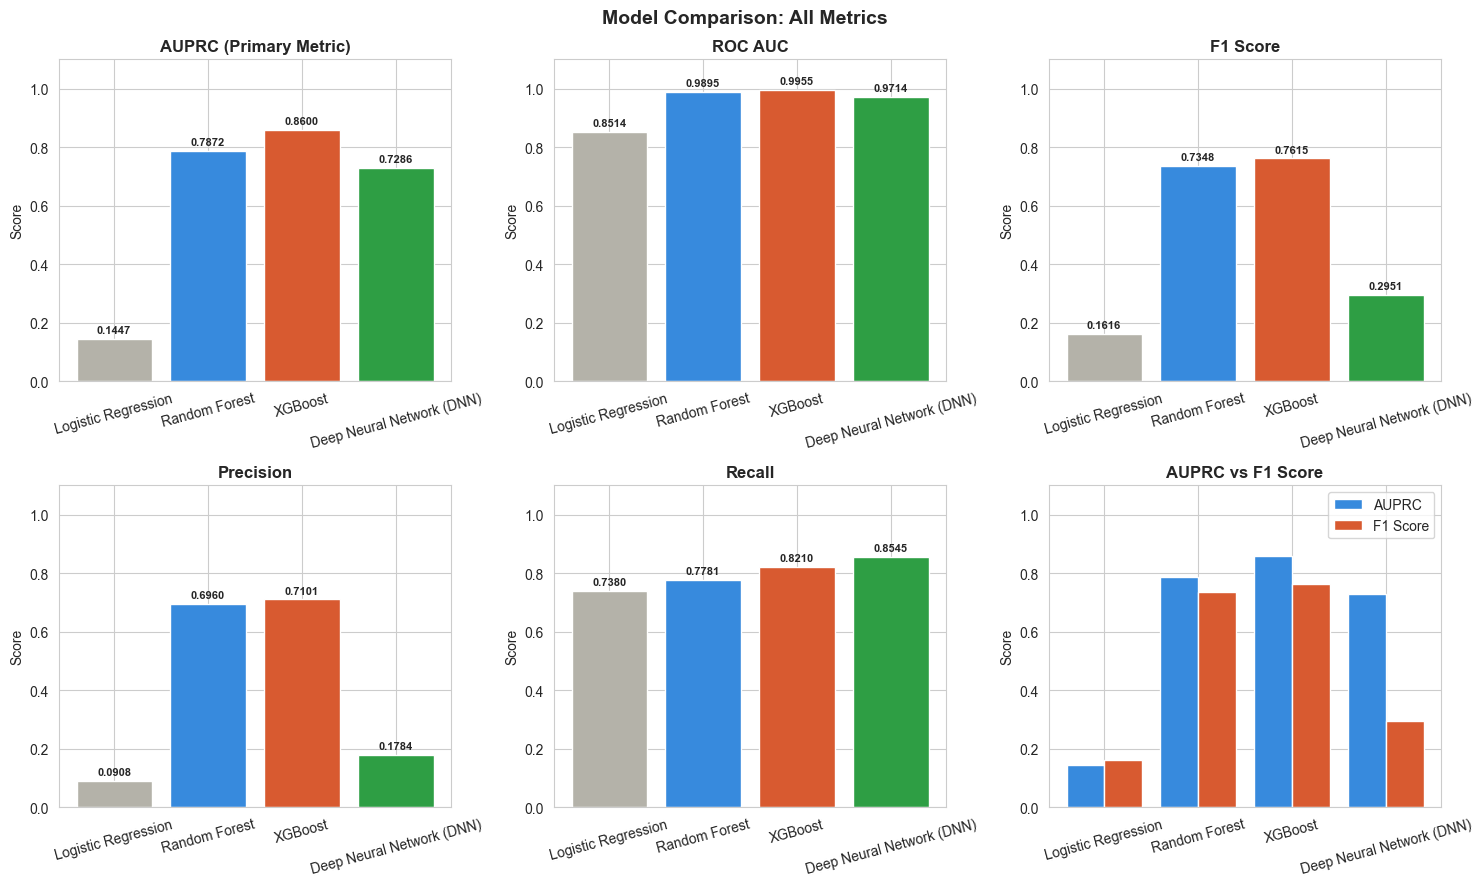


Chart saved: chart_model_comparison.png


In [49]:
import matplotlib.pyplot as plt
import numpy as np

# build the comparison table from the actual predictions computed
# above (Parts 4.3, 4.4, 4.6 and 4.7), rather than retyping numbers
model_names_all = ['Logistic Regression', 'Random Forest',
                    'XGBoost', 'Deep Neural Network (DNN)']
probas_all = [lr_proba, rf_proba, xgb_proba, dnn_proba]
preds_all  = [lr_pred, rf_pred, xgb_pred, dnn_pred]

results = {
    'Model': model_names_all,
    'AUPRC':     [average_precision_score(y_test, p) for p in probas_all],
    'ROC_AUC':   [roc_auc_score(y_test, p) for p in probas_all],
    'F1':        [f1_score(y_test, p) for p in preds_all],
    'Precision': [precision_score(y_test, p) for p in preds_all],
    'Recall':    [recall_score(y_test, p) for p in preds_all],
}

results_df = pd.DataFrame(results)                    # convert to dataframe
print("Model comparison table:")
print()
print(results_df.to_string(index=False))

best_row = results_df.loc[results_df['AUPRC'].idxmax()]
print()
print(f"  Best model: {best_row['Model']} (AUPRC {best_row['AUPRC']:.4f})")

# colours for each model
colors = ['#B4B2A9', '#378ADD', '#D85A30', '#2E9E44']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))       # 2 rows 3 columns of charts
axes = axes.flatten()                                  # flatten for easy looping

metrics = ['AUPRC', 'ROC_AUC', 'F1', 'Precision', 'Recall']
titles  = ['AUPRC (Primary Metric)', 'ROC AUC',
           'F1 Score', 'Precision', 'Recall']

for i, (metric, title) in enumerate(zip(metrics, titles)):
    axes[i].bar(
        results_df['Model'],
        results_df[metric],
        color=colors                                   # different colour per model
    )
    axes[i].set_title(title, fontweight='bold')
    axes[i].set_ylabel('Score')
    axes[i].set_ylim(0, 1.1)                          # y axis from 0 to 1.1
    axes[i].tick_params(axis='x', rotation=15)        # rotate model names

    # add value labels on top of each bar
    for j, val in enumerate(results_df[metric]):
        axes[i].text(j, val + 0.02, f'{val:.4f}',
                     ha='center', fontsize=8,
                     fontweight='bold')

# use the 6th chart for a summary style grouped bar
axes[5].bar(
    np.arange(len(results_df)) - 0.2,
    results_df['AUPRC'],
    width=0.4, color='#378ADD',
    label='AUPRC')                                    # AUPRC bars
axes[5].bar(
    np.arange(len(results_df)) + 0.2,
    results_df['F1'],
    width=0.4, color='#D85A30',
    label='F1 Score')                                 # F1 bars
axes[5].set_title('AUPRC vs F1 Score', fontweight='bold')
axes[5].set_xticks(np.arange(len(results_df)))
axes[5].set_xticklabels(results_df['Model'], rotation=15)
axes[5].set_ylabel('Score')
axes[5].set_ylim(0, 1.1)
axes[5].legend()

plt.suptitle('Model Comparison: All Metrics',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_model_comparison.png',
            dpi=CHART_DPI, bbox_inches='tight')             # save chart
plt.show()
print()
print("Chart saved: chart_model_comparison.png")


## 4.9 Confusion Matrices

Reuses the predictions already computed for each model in Parts 4.3 to 4.7; nothing is retrained here.


Logistic Regression:
  True Negatives  (correct legitimate): 537,714
  False Positives (wrong fraud alert):  15,860
  False Negatives (missed fraud):       562
  True Positives  (caught fraud):       1,583
  Fraud caught:   1583/2145 (73.8%)
  False alerts:   15,860

Random Forest:
  True Negatives  (correct legitimate): 552,845
  False Positives (wrong fraud alert):  729
  False Negatives (missed fraud):       476
  True Positives  (caught fraud):       1,669
  Fraud caught:   1669/2145 (77.8%)
  False alerts:   729

XGBoost:
  True Negatives  (correct legitimate): 552,855
  False Positives (wrong fraud alert):  719
  False Negatives (missed fraud):       384
  True Positives  (caught fraud):       1,761
  Fraud caught:   1761/2145 (82.1%)
  False alerts:   719

Deep Neural Network (DNN):
  True Negatives  (correct legitimate): 545,130
  False Positives (wrong fraud alert):  8,444
  False Negatives (missed fraud):       312
  True Positives  (caught fraud):       1,833
  Fraud caught:

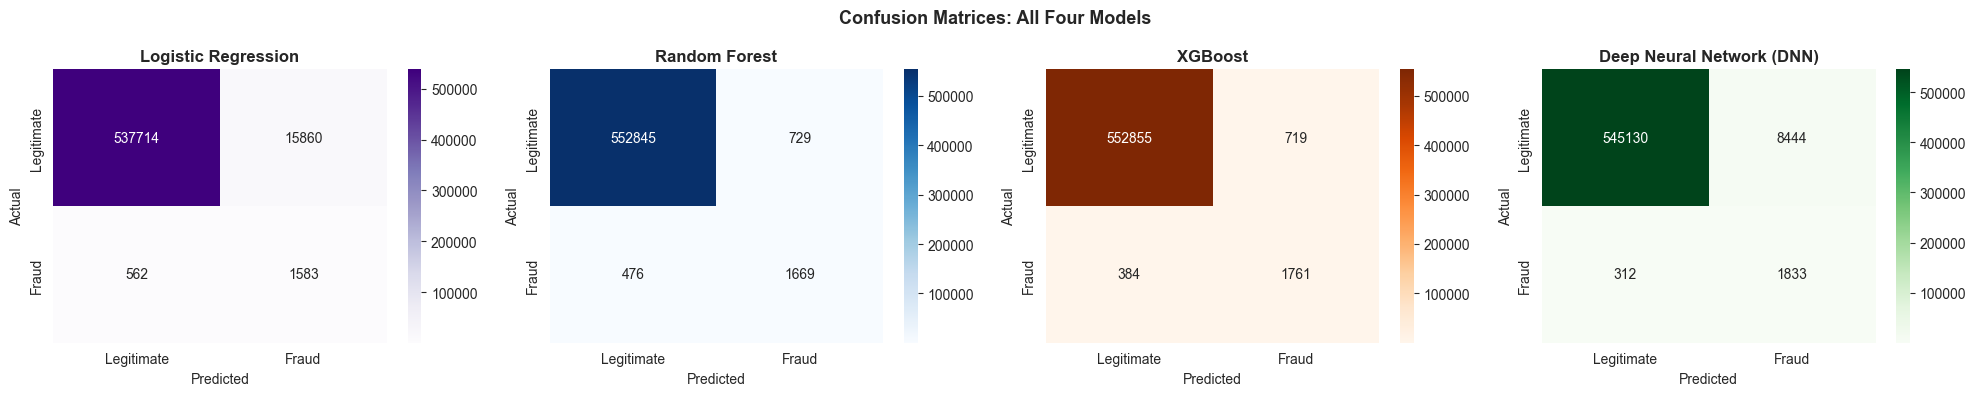

Chart saved: chart_confusion_matrices.png


In [50]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# lr_pred, rf_pred, xgb_pred and dnn_pred all already exist from
# Parts 4.3, 4.4, 4.6 and 4.7, so nothing needs to be retrained here

fig, axes = plt.subplots(1, 4, figsize=(20, 4))       # 1 row 4 charts

model_names = model_names_all                          # from Part 4.8
preds       = preds_all                                # from Part 4.8
colors      = ['Purples', 'Blues', 'Oranges', 'Greens']

confusion_rows = []                                     # collected for Part 7

for i, (name, pred, cmap) in enumerate(
        zip(model_names, preds, colors)):

    cm = confusion_matrix(y_test, pred)                # compute confusion matrix
    tn, fp, fn, tp = cm.ravel()                        # unpack four values

    sns.heatmap(
        cm,
        annot=True,                                    # show numbers in cells
        fmt='d',                                       # integer format
        cmap=cmap,                                     # colour per model
        ax=axes[i],
        xticklabels=['Legitimate', 'Fraud'],
        yticklabels=['Legitimate', 'Fraud']
    )
    axes[i].set_title(f'{name}', fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

    print(f"{name}:")
    print(f"  True Negatives  (correct legitimate): {tn:,}")
    print(f"  False Positives (wrong fraud alert):  {fp:,}")
    print(f"  False Negatives (missed fraud):       {fn:,}")
    print(f"  True Positives  (caught fraud):       {tp:,}")
    print(f"  Fraud caught:   {tp}/{tp+fn} "
          f"({tp/(tp+fn)*100:.1f}%)")
    print(f"  False alerts:   {fp:,}")
    print()

    confusion_rows.append({
        'Model': name, 'Caught': tp, 'Missed': fn,
        'False_Alerts': fp, 'Detection_Rate': tp / (tp + fn) * 100
    })

confusion_df = pd.DataFrame(confusion_rows)            # reused in Part 7

plt.suptitle(
    'Confusion Matrices: All Four Models',
    fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_confusion_matrices.png',
            dpi=CHART_DPI, bbox_inches='tight')              # save chart
plt.show()
print("Chart saved: chart_confusion_matrices.png")


## 4.10 Precision Recall Curves

AUPRC is the primary metric for this dissertation because it is far more informative than ROC AUC on a heavily imbalanced dataset like this one.

Generating Precision Recall curves for all four models...



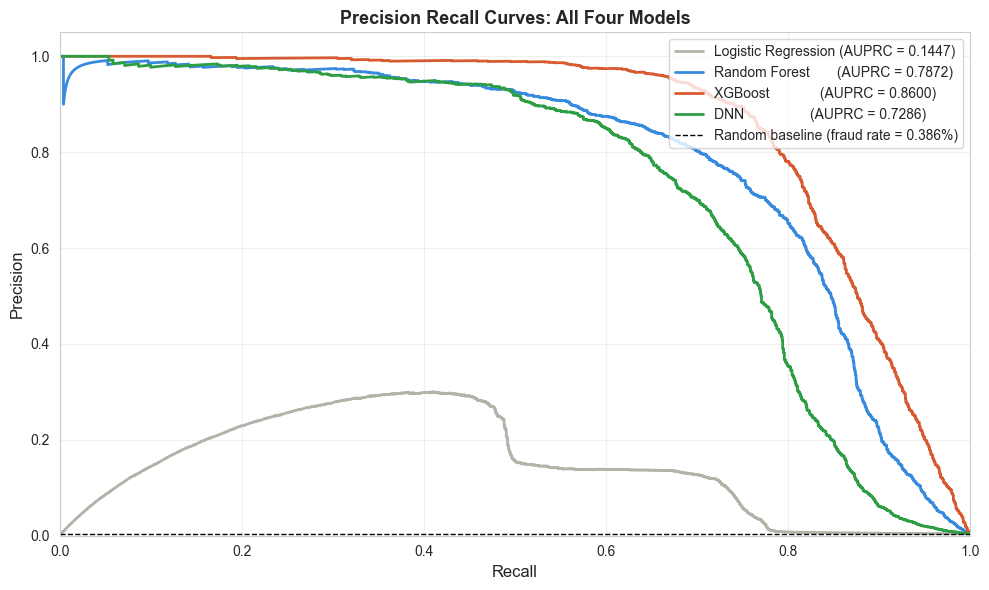

AUPRC Summary:

  Logistic Regression: 0.1447
  Random Forest:       0.7872
  XGBoost:             0.8600
  DNN:                 0.7286
  Random baseline:     0.0039

Chart saved: chart_precision_recall_curves.png


In [51]:
from sklearn.metrics import precision_recall_curve, average_precision_score

print("Generating Precision Recall curves for all four models...")
print()

# calculate precision recall curve for each model
lr_precision,  lr_recall,  _ = precision_recall_curve(y_test, lr_proba)
rf_precision,  rf_recall,  _ = precision_recall_curve(y_test, rf_proba)
xgb_precision, xgb_recall, _ = precision_recall_curve(y_test, xgb_proba)
dnn_precision, dnn_recall, _ = precision_recall_curve(y_test, dnn_proba)

# AUPRC for each model, computed live rather than retyped
lr_auprc  = average_precision_score(y_test, lr_proba)
rf_auprc  = average_precision_score(y_test, rf_proba)
xgb_auprc = average_precision_score(y_test, xgb_proba)
dnn_auprc = average_precision_score(y_test, dnn_proba)

# plot all four curves on one chart
plt.figure(figsize=(10, 6))

plt.plot(lr_recall,  lr_precision,
         color='#B4B2A9', linewidth=2,
         label=f'Logistic Regression (AUPRC = {lr_auprc:.4f})')

plt.plot(rf_recall,  rf_precision,
         color='#378ADD', linewidth=2,
         label=f'Random Forest       (AUPRC = {rf_auprc:.4f})')

plt.plot(xgb_recall, xgb_precision,
         color='#D85A30', linewidth=2,
         label=f'XGBoost             (AUPRC = {xgb_auprc:.4f})')

plt.plot(dnn_recall, dnn_precision,
         color='#2E9E44', linewidth=2,
         label=f'DNN                 (AUPRC = {dnn_auprc:.4f})')

# add a baseline: a random classifier on this dataset
# baseline = fraud rate = 0.386%
baseline = y_test.mean()                               # fraud rate in test set
plt.axhline(y=baseline, color='black',
            linestyle='--', linewidth=1,
            label=f'Random baseline (fraud rate = {baseline*100:.3f}%)')

plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision Recall Curves: All Four Models',
          fontsize=13, fontweight='bold')
plt.legend(loc='upper right', fontsize=10)
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('chart_precision_recall_curves.png',
            dpi=CHART_DPI, bbox_inches='tight')              # save chart
plt.show()

print("AUPRC Summary:")
print()
print(f"  Logistic Regression: {lr_auprc:.4f}")
print(f"  Random Forest:       {rf_auprc:.4f}")
print(f"  XGBoost:             {xgb_auprc:.4f}")
print(f"  DNN:                 {dnn_auprc:.4f}")
print(f"  Random baseline:     {baseline:.4f}")
print()
print("Chart saved: chart_precision_recall_curves.png")


## 4.11 ROC Curves

Included for completeness and comparison with the Precision Recall curves above.

Generating ROC curves for all four models...



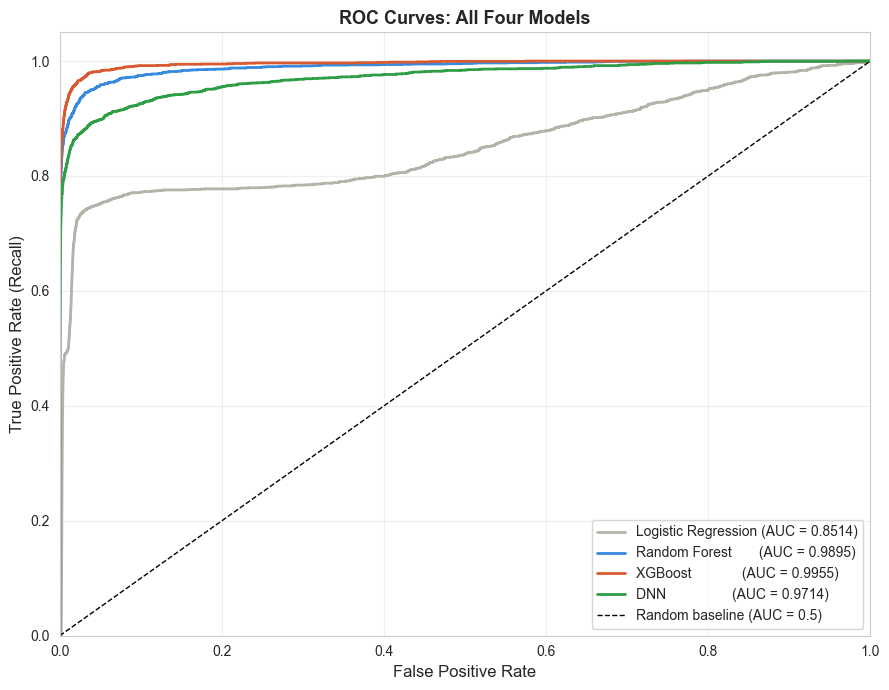

ROC AUC Summary:

  Logistic Regression: 0.8514
  Random Forest:       0.9895
  XGBoost:             0.9955
  DNN:                 0.9714
  Random baseline:     0.5000

Chart saved: chart_roc_curves.png


In [52]:
from sklearn.metrics import roc_curve, roc_auc_score

print("Generating ROC curves for all four models...")
print()

# calculate ROC curve for each model
lr_fpr,  lr_tpr,  _ = roc_curve(y_test, lr_proba)
rf_fpr,  rf_tpr,  _ = roc_curve(y_test, rf_proba)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_proba)
dnn_fpr, dnn_tpr, _ = roc_curve(y_test, dnn_proba)

# ROC AUC for each model, computed live rather than retyped
lr_roc_auc  = roc_auc_score(y_test, lr_proba)
rf_roc_auc  = roc_auc_score(y_test, rf_proba)
xgb_roc_auc = roc_auc_score(y_test, xgb_proba)
dnn_roc_auc = roc_auc_score(y_test, dnn_proba)

# plot all four curves on one chart
plt.figure(figsize=(9, 7))

plt.plot(lr_fpr,  lr_tpr,
         color='#B4B2A9', linewidth=2,
         label=f'Logistic Regression (AUC = {lr_roc_auc:.4f})')

plt.plot(rf_fpr,  rf_tpr,
         color='#378ADD', linewidth=2,
         label=f'Random Forest       (AUC = {rf_roc_auc:.4f})')

plt.plot(xgb_fpr, xgb_tpr,
         color='#D85A30', linewidth=2,
         label=f'XGBoost             (AUC = {xgb_roc_auc:.4f})')

plt.plot(dnn_fpr, dnn_tpr,
         color='#2E9E44', linewidth=2,
         label=f'DNN                 (AUC = {dnn_roc_auc:.4f})')

# random classifier baseline: diagonal line
plt.plot([0, 1], [0, 1],
         color='black', linestyle='--',
         linewidth=1, label='Random baseline (AUC = 0.5)')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curves: All Four Models',
          fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('chart_roc_curves.png',
            dpi=CHART_DPI, bbox_inches='tight')              # save chart
plt.show()

print("ROC AUC Summary:")
print()
print(f"  Logistic Regression: {lr_roc_auc:.4f}")
print(f"  Random Forest:       {rf_roc_auc:.4f}")
print(f"  XGBoost:             {xgb_roc_auc:.4f}")
print(f"  DNN:                 {dnn_roc_auc:.4f}")
print(f"  Random baseline:     0.5000")
print()
print("Chart saved: chart_roc_curves.png")


## 4.12 Install SHAP

In [53]:
import subprocess
import sys
import importlib

# sys.executable is the exact Python interpreter running this
# notebook's kernel, so the package always installs where it
# can actually be imported, regardless of which Python install
# happens to be first on the system PATH
result = subprocess.run(
    [sys.executable, '-m', 'pip', 'install', 'shap'],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("shap installed successfully.")
else:
    print("WARNING: pip install failed. See stderr above for details.")

# refresh Python's import system so a package installed just now
# in this same kernel session can be found immediately; if the
# import below still fails, restart the kernel and rerun from here
importlib.invalidate_caches()


## 4.13 SHAP Feature Importance: XGBoost

SHAP is computed on a sample of the test set (the full test set would be too slow) to explain which features drive XGBoost's fraud predictions, and in which direction.

Computing SHAP values for XGBoost...
(Using XGBoost as it is the best performing model)

SHAP values computed for 1000 test transactions.
SHAP values shape: (1000, 19)



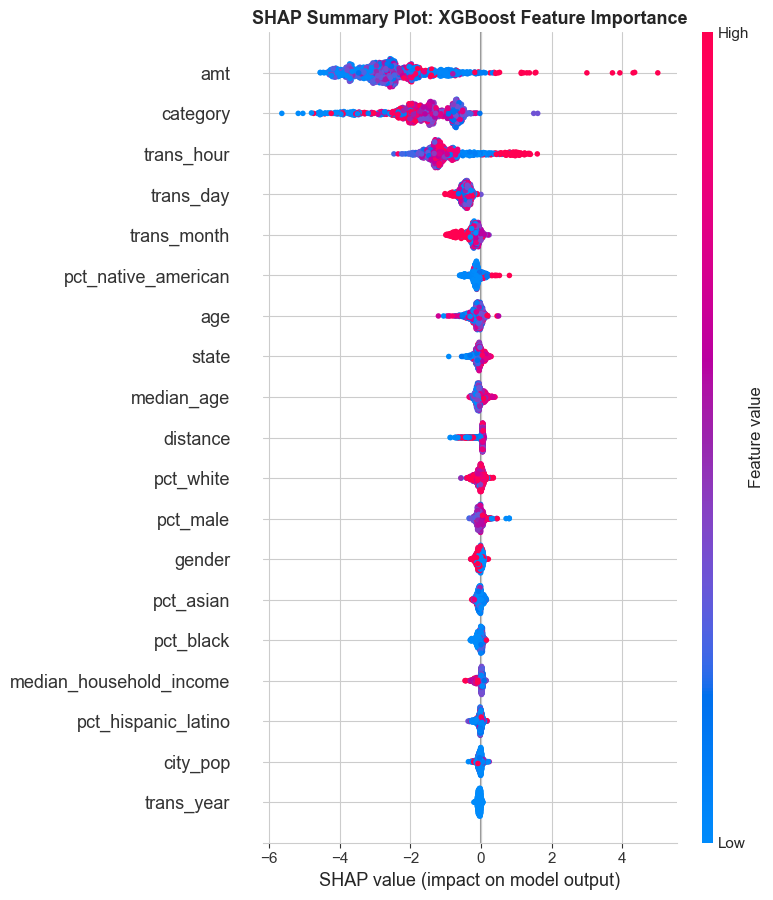

Chart saved: chart_shap_summary.png



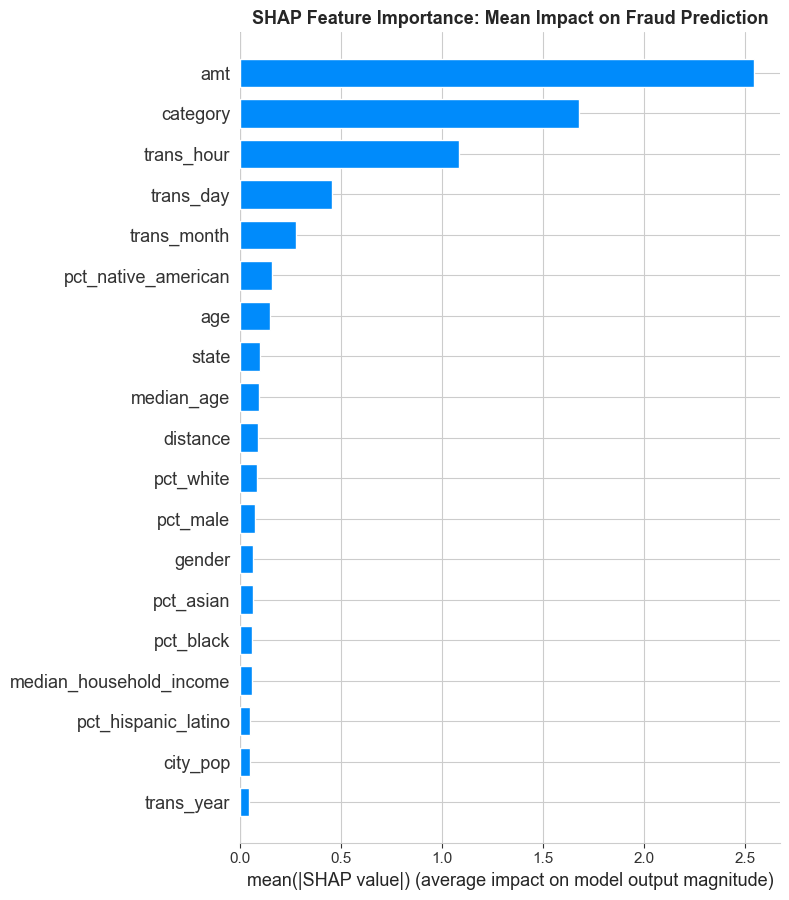

Chart saved: chart_shap_importance.png

Top 10 most important features (by mean absolute SHAP value):

  amt                            2.5464
  category                       1.6778
  trans_hour                     1.0863
  trans_day                      0.4557
  trans_month                    0.2764
  pct_native_american            0.1565
  age                            0.1473
  state                          0.0975
  median_age                     0.0948
  distance                       0.0905


In [54]:
import shap                                            # explainability library

print("Computing SHAP values for XGBoost...")
print("(Using XGBoost as it is the best performing model)")
print()

# use a sample of test data for SHAP
# computing SHAP on all 555,719 rows would be very slow
shap_sample_size = SHAP_SAMPLE_SIZE
idx_shap = np.random.choice(len(X_test),
                             shap_sample_size,
                             replace=False)            # random sample indices
X_shap = X_test.iloc[idx_shap]                        # sampled test features

# create a SHAP explainer for XGBoost
# TreeExplainer is fast and exact for tree based models
explainer   = shap.TreeExplainer(xgb_best)            # create explainer
shap_values = explainer.shap_values(X_shap)           # compute SHAP values

print(f"SHAP values computed for {shap_sample_size} test transactions.")
print(f"SHAP values shape: {shap_values.shape}")
print()

# CHART 1: Summary plot (beeswarm)
# shows which features matter most and in which direction
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_test.columns.tolist(),             # feature names
    show=False                                         # do not display yet
)
plt.title('SHAP Summary Plot: XGBoost Feature Importance',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_shap_summary.png',
            dpi=CHART_DPI, bbox_inches='tight')              # save chart
plt.show()
print("Chart saved: chart_shap_summary.png")
print()

# CHART 2: Bar plot (mean importance)
# shows the average impact of each feature on predictions
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_test.columns.tolist(),
    plot_type='bar',                                   # bar chart version
    show=False
)
plt.title('SHAP Feature Importance: Mean Impact on Fraud Prediction',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_shap_importance.png',
            dpi=CHART_DPI, bbox_inches='tight')              # save chart
plt.show()
print("Chart saved: chart_shap_importance.png")
print()

# print the top 10 most important features by mean SHAP value
print("Top 10 most important features (by mean absolute SHAP value):")
print()
mean_shap = np.abs(shap_values).mean(axis=0)          # mean absolute SHAP per feature
feature_importance = pd.DataFrame({
    'Feature':    X_test.columns.tolist(),
    'Mean_SHAP':  mean_shap
}).sort_values('Mean_SHAP', ascending=False)           # sort by importance

for i, row in feature_importance.head(10).iterrows():
    print(f"  {row['Feature']:<30} {row['Mean_SHAP']:.4f}")

## 4.14 SHAP: Direction of Effect and Local Interpretability

The ranking in Part 4.13 shows which features carry the most weight, but not which way each one pushes a prediction. This section prints the complete ranking across all features, so nothing is obscured by the top-five truncation in the summary chart, then plots the direction of effect for the highest ranked features and breaks down two individual predictions.


Complete SHAP ranking, all features:

  Rank   Feature                       Mean |SHAP|   % of total

  1      amt                                2.5464        35.5%
  2      category                           1.6778        23.4%
  3      trans_hour                         1.0863        15.1%
  4      trans_day                          0.4557         6.3%
  5      trans_month                        0.2764         3.9%
  6      pct_native_american                0.1565         2.2%
  7      age                                0.1473         2.1%
  8      state                              0.0975         1.4%
  9      median_age                         0.0948         1.3%
  10     distance                           0.0905         1.3%
  11     pct_white                          0.0834         1.2%
  12     pct_male                           0.0762         1.1%
  13     gender                             0.0651         0.9%
  14     pct_asian                          0.0619         0.9%
 

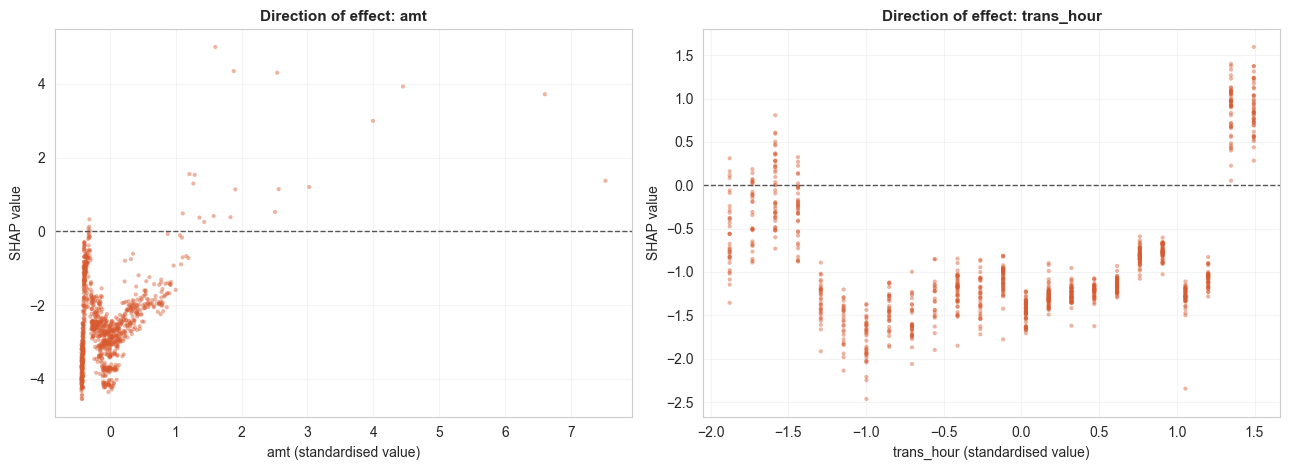

Chart saved: chart_shap_dependence.png

Direction of effect for amt:
  Highest quartile of amt: mean SHAP  -1.9075
  Lowest quartile of  amt: mean SHAP  -2.7940
  A higher amt pushes a transaction towards being flagged as fraud.



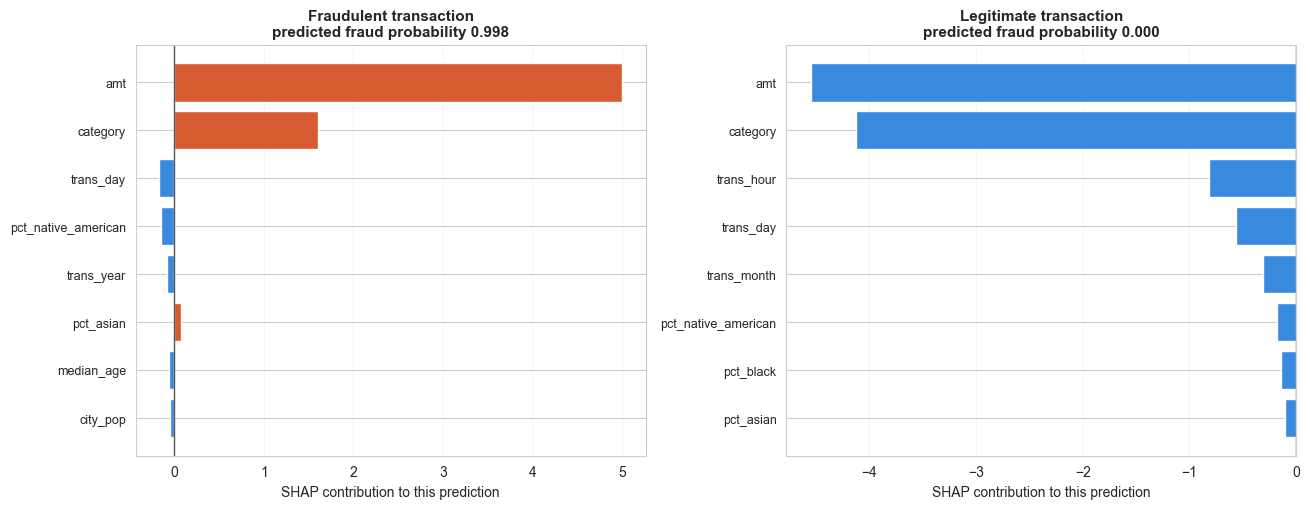

Chart saved: chart_shap_local.png

Orange bars pushed the prediction towards fraud, blue bars away from it.
These are the eight largest contributions for each transaction.


In [55]:
# SHAP: DIRECTION OF EFFECT AND LOCAL INTERPRETABILITY
# The ranking in Part 4.13 establishes which features matter most, but a
# ranking alone does not say which way a feature pushes a prediction. A
# reader told that transaction amount is the dominant feature will
# reasonably ask whether it is a high or a low amount that drives a
# transaction towards being flagged. The plots below answer that, and
# then examine individual predictions rather than the average.

# 1. FULL FEATURE RANKING
# The bar chart in Part 4.13 is truncated to the five highest ranked
# features for legibility. The complete ordering across all features is
# printed here so nothing is hidden by that truncation.
mean_abs_shap = np.abs(shap_values).mean(axis=0)
full_ranking = pd.DataFrame({
    'Feature': X_shap.columns,
    'Mean_SHAP': mean_abs_shap
}).sort_values('Mean_SHAP', ascending=False).reset_index(drop=True)

print("Complete SHAP ranking, all features:")
print()
print(f"  {'Rank':<6} {'Feature':<28} {'Mean |SHAP|':>12}  {'% of total':>11}")
print()
total = full_ranking['Mean_SHAP'].sum()
for i, row in full_ranking.iterrows():
    print(f"  {i+1:<6} {row['Feature']:<28} {row['Mean_SHAP']:>12.4f}  "
          f"{row['Mean_SHAP']/total*100:>10.1f}%")
print()
top5_share = full_ranking.head(5)['Mean_SHAP'].sum() / total * 100
print(f"The five highest ranked features account for {top5_share:.1f}% of "
      f"total attribution,")
print("which is why the summary chart is limited to those five.")
print()

# 2. DEPENDENCE PLOT: DIRECTION OF EFFECT FOR TRANSACTION AMOUNT
# Each point is one transaction. The horizontal axis is the feature
# value and the vertical axis is that feature's SHAP value for that
# transaction. Points above zero were pushed towards a fraud
# prediction, points below zero away from it.
top_feature = full_ranking.iloc[0]['Feature']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for ax, feat in zip(axes, [top_feature, full_ranking.iloc[2]['Feature']]):
    col_idx = list(X_shap.columns).index(feat)
    ax.scatter(X_shap[feat], shap_values[:, col_idx],
               s=9, alpha=0.45, c='#D85A30', edgecolors='none')
    ax.axhline(0, color='#555555', linewidth=1, linestyle='--')
    ax.set_xlabel(f'{feat} (standardised value)', fontsize=10)
    ax.set_ylabel('SHAP value', fontsize=10)
    ax.set_title(f'Direction of effect: {feat}', fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('chart_shap_dependence.png', dpi=CHART_DPI, bbox_inches='tight')
plt.show()
print("Chart saved: chart_shap_dependence.png")
print()

# state the direction numerically as well as visually, so the finding
# does not depend on reading a scatter plot correctly
col_idx = list(X_shap.columns).index(top_feature)
vals = X_shap[top_feature].values
sv = shap_values[:, col_idx]
high = vals >= np.percentile(vals, 75)
low = vals <= np.percentile(vals, 25)
print(f"Direction of effect for {top_feature}:")
print(f"  Highest quartile of {top_feature}: mean SHAP {sv[high].mean():>+8.4f}")
print(f"  Lowest quartile of  {top_feature}: mean SHAP {sv[low].mean():>+8.4f}")
direction = "higher" if sv[high].mean() > sv[low].mean() else "lower"
print(f"  A {direction} {top_feature} pushes a transaction towards being "
      f"flagged as fraud.")
print()

# 3. LOCAL INTERPRETABILITY: INDIVIDUAL PREDICTIONS
# Global rankings describe average behaviour. A fraud analyst reviewing
# a specific alert needs to know why that particular transaction was
# flagged, which is what a per-transaction breakdown provides.
y_shap = y_test.iloc[idx_shap].values
proba_shap = xgb_best.predict_proba(X_shap)[:, 1]

# pick the fraud case the model was most confident about, and a
# legitimate transaction it was most confident about, so the two
# explanations contrast clearly
fraud_idx = np.where(y_shap == 1)[0]
legit_idx = np.where(y_shap == 0)[0]
case_fraud = fraud_idx[np.argmax(proba_shap[fraud_idx])] if len(fraud_idx) else None
case_legit = legit_idx[np.argmin(proba_shap[legit_idx])]

cases = [(case_fraud, 'Fraudulent transaction'),
         (case_legit, 'Legitimate transaction')]
cases = [(i, lab) for i, lab in cases if i is not None]

fig, axes = plt.subplots(1, len(cases), figsize=(6.6 * len(cases), 5.2))
if len(cases) == 1:
    axes = [axes]

for ax, (case_i, label) in zip(axes, cases):
    contrib = pd.Series(shap_values[case_i], index=X_shap.columns)
    contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:8]
    contrib = contrib.iloc[::-1]
    colours = ['#D85A30' if v > 0 else '#378ADD' for v in contrib.values]
    ax.barh(range(len(contrib)), contrib.values, color=colours)
    ax.set_yticks(range(len(contrib)))
    ax.set_yticklabels(contrib.index, fontsize=9)
    ax.axvline(0, color='#555555', linewidth=1)
    ax.set_xlabel('SHAP contribution to this prediction', fontsize=10)
    ax.set_title(f'{label}\npredicted fraud probability '
                 f'{proba_shap[case_i]:.3f}', fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.2, axis='x')

plt.tight_layout()
plt.savefig('chart_shap_local.png', dpi=CHART_DPI, bbox_inches='tight')
plt.show()
print("Chart saved: chart_shap_local.png")
print()
print("Orange bars pushed the prediction towards fraud, blue bars away "
      "from it.")
print("These are the eight largest contributions for each transaction.")


# Part 4.14: Statistical Significance of Model Differences

The comparison in Part 4.8 establishes an ordering of the four classifiers, but an ordering alone does not show that the differences between them exceed what sampling variation would produce. McNemar's test is applied pairwise to the predictions, and bootstrap resampling of the test set gives confidence intervals for the AUPRC differences relative to XGBoost. Both operate on predictions already computed above, so no model is retrained.


In [56]:
# STATISTICAL SIGNIFICANCE TESTING
# The model comparison in Part 4.8 ranks the four classifiers, but a
# ranking alone does not establish whether the gaps between them are
# larger than sampling variation would produce. Two tests are applied
# here, both operating on predictions that already exist, so no model
# is retrained.
#
#   1. McNemar's test compares two classifiers on the same test set by
#      counting cases where exactly one of them is correct. It is the
#      standard paired test for this situation.
#   2. Bootstrap resampling of the test set gives a confidence interval
#      for the difference in AUPRC between two models.
#
# McNemar's test is implemented directly from scipy rather than through
# statsmodels, so this cell needs no package beyond those already used
# elsewhere in the notebook.

from scipy.stats import chi2, binomtest
from itertools import combinations

def mcnemar_test(n10, n01):
    """McNemar's test on the two discordant counts.

    n10 = cases only the first model classified correctly
    n01 = cases only the second model classified correctly

    Uses the exact binomial test when the discordant total is small,
    where the chi-squared approximation is unreliable, and the
    continuity-corrected chi-squared statistic otherwise.
    """
    n = n10 + n01
    if n == 0:
        return 1.0, 'identical'
    if n < 25:
        p = binomtest(min(n10, n01), n, 0.5).pvalue
        return p, 'exact'
    stat = (abs(n10 - n01) - 1) ** 2 / n
    return chi2.sf(stat, 1), 'chi2'

print("STATISTICAL SIGNIFICANCE TESTING")
print()

model_preds = {
    'Logistic Regression': lr_pred,
    'Random Forest':       rf_pred,
    'XGBoost':             xgb_pred,
    'DNN':                 dnn_pred,
}
model_probas = {
    'Logistic Regression': lr_proba,
    'Random Forest':       rf_proba,
    'XGBoost':             xgb_proba,
    'DNN':                 dnn_proba,
}

y_arr = np.asarray(y_test)

print("1. McNemar's test, pairwise, on the correctness of each prediction")
print()
print(f"  {'Comparison':<40} {'b':>8} {'c':>8} {'p-value':>12}  {'Signif.':>8}")
print()

mcnemar_rows = []
for a, b in combinations(model_preds, 2):
    pa = np.asarray(model_preds[a]) == y_arr          # a correct
    pb = np.asarray(model_preds[b]) == y_arr          # b correct
    n10 = int(np.sum(pa & ~pb))                       # only a correct
    n01 = int(np.sum(~pa & pb))                       # only b correct
    pval, method = mcnemar_test(n10, n01)
    sig = 'yes' if pval < 0.05 else 'no'
    print(f"  {a + ' vs ' + b:<40} {n10:>8,} {n01:>8,} {pval:>12.3e}  {sig:>8}")
    mcnemar_rows.append({'Comparison': f"{a} vs {b}", 'b': n10, 'c': n01,
                          'p_value': pval, 'Method': method, 'Significant': sig})

print()
print("  b = cases only the first model classified correctly")
print("  c = cases only the second model classified correctly")
print()

print("2. Bootstrap 95% confidence intervals for the AUPRC difference")
print("   (2,000 resamples of the test set, XGBoost as the reference)")
print()

N_BOOT = 2000
rng = np.random.default_rng(RANDOM_STATE)
n_test = len(y_arr)
ref = 'XGBoost'
ref_proba = np.asarray(model_probas[ref])

print(f"  {'Comparison':<38} {'Mean diff':>11}   {'95% CI':>24} {'Excl. 0':>9}")
print()

boot_rows = []
for name in model_probas:
    if name == ref:
        continue
    other = np.asarray(model_probas[name])
    diffs = []
    for _ in range(N_BOOT):
        idx = rng.integers(0, n_test, n_test)          # resample with replacement
        yb = y_arr[idx]
        if yb.sum() == 0:                              # skip degenerate resamples
            continue
        diffs.append(average_precision_score(yb, ref_proba[idx])
                     - average_precision_score(yb, other[idx]))
    diffs = np.array(diffs)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    excl = 'yes' if (lo > 0 or hi < 0) else 'no'
    print(f"  {ref + ' - ' + name:<38} {diffs.mean():>11.4f}   "
          f"[{lo:>9.4f}, {hi:>8.4f}] {excl:>9}")
    boot_rows.append({'Comparison': f"{ref} - {name}", 'Mean_diff': diffs.mean(),
                       'CI_low': lo, 'CI_high': hi, 'Excludes_zero': excl})

mcnemar_df = pd.DataFrame(mcnemar_rows)
significance_df = pd.DataFrame(boot_rows)

print()
print("A confidence interval excluding zero indicates the AUPRC difference")
print("is unlikely to be a product of sampling variation alone.")


STATISTICAL SIGNIFICANCE TESTING

1. McNemar's test, pairwise, on the correctness of each prediction

  Comparison                                      b        c      p-value   Signif.

  Logistic Regression vs Random Forest          284   15,501    0.000e+00       yes
  Logistic Regression vs XGBoost                215   15,534    0.000e+00       yes
  Logistic Regression vs DNN                  5,665   13,331    0.000e+00       yes
  Random Forest vs XGBoost                      381      483    5.902e-04       yes
  Random Forest vs DNN                        7,847      296    0.000e+00       yes
  XGBoost vs DNN                              7,924      271    0.000e+00       yes

  b = cases only the first model classified correctly
  c = cases only the second model classified correctly

2. Bootstrap 95% confidence intervals for the AUPRC difference
   (2,000 resamples of the test set, XGBoost as the reference)

  Comparison                               Mean diff                   

# Part 4.15: Socioeconomic Ablation

The SHAP ranking shows that no Census-derived feature reaches the upper ranks of attribution, but a low attribution score describes how a fitted model uses the features it was given rather than what would happen if they were withheld. This ablation tests the second research question directly: each model is retrained twice on identical data, once with the eight Census features and once without, with every other element of the pipeline held constant, so any difference in AUPRC is attributable to the enrichment itself.


SOCIOECONOMIC ABLATION

  Census features withheld in the ablated condition: 8
    median_age, median_household_income, pct_male, pct_hispanic_latino, pct_white, pct_black, pct_native_american, pct_asian
  Features with Census:    19
  Features without Census: 11

  Training rows per fit: 200,000
  Test rows (full, untouched): 555,719

  Fitting Logistic Regression without Census features ...
  Fitting Logistic Regression with Census features ...
  Fitting Random Forest without Census features ...
  Fitting Random Forest with Census features ...
  Fitting XGBoost without Census features ...
  Fitting XGBoost with Census features ...

Ablation results: effect of withholding the Census features

  Model                   AUPRC without   AUPRC with   Difference

  Logistic Regression            0.1452       0.1450      -0.0003
  Random Forest                  0.8288       0.7680      -0.0609
  XGBoost                        0.8578       0.8480      -0.0098

  Model                      F1

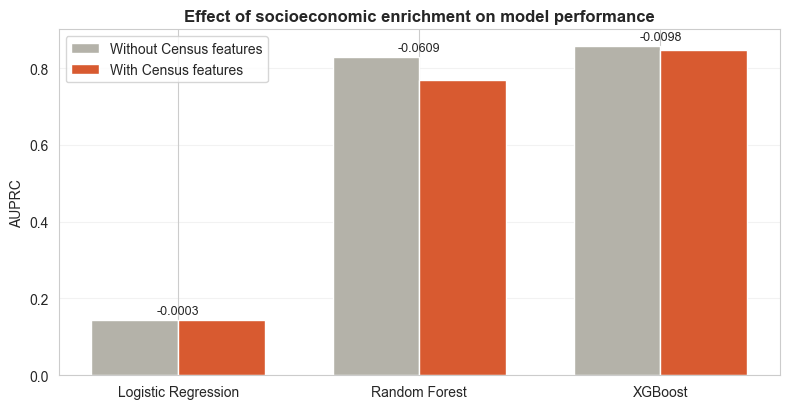

Chart saved: chart_census_ablation.png


In [57]:
# SOCIOECONOMIC ABLATION: DOES CENSUS ENRICHMENT ADD PREDICTIVE VALUE?
# The SHAP ranking in Part 4.13 shows that no Census-derived feature reaches
# the upper ranks of attribution, but a low attribution score is not the same
# as no contribution: SHAP describes how a fitted model uses the features it
# was given, not what would happen if those features were withheld.
#
# This ablation answers the question directly. Each model is retrained twice
# on identical data, once with the eight Census features and once without,
# with every other element of the pipeline held constant. Any difference in
# AUPRC is therefore attributable to the enrichment itself.

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier      # imported explicitly: the notebook
                                        # elsewhere uses `import xgboost as xgb`,
                                        # so the bare class name is not in scope
import gc

CENSUS_FEATURES = [c for c in [
    'median_age', 'median_household_income', 'pct_male',
    'pct_hispanic_latino', 'pct_white', 'pct_black',
    'pct_native_american', 'pct_asian'] if c in X_train.columns]

non_census = [c for c in X_train.columns if c not in CENSUS_FEATURES]

print("SOCIOECONOMIC ABLATION")
print()
print(f"  Census features withheld in the ablated condition: {len(CENSUS_FEATURES)}")
print(f"    {', '.join(CENSUS_FEATURES)}")
print(f"  Features with Census:    {len(X_train.columns)}")
print(f"  Features without Census: {len(non_census)}")
print()

# a training sample keeps the study tractable: six model fits on 2.5 million
# rows would take far longer than the comparison warrants. The test set is
# the full held-out set in every condition, so the two conditions remain
# directly comparable with one another.
ABLATION_SAMPLE = 200_000
rs = np.random.RandomState(RANDOM_STATE)
sample_idx = rs.choice(len(X_train_scaled), ABLATION_SAMPLE, replace=False)

print(f"  Training rows per fit: {ABLATION_SAMPLE:,}")
print(f"  Test rows (full, untouched): {len(y_test):,}")
print()


def fit_and_score(model_name, cols):
    """Train one model on the given feature subset and score it on the test set."""
    Xtr = X_train_scaled.iloc[sample_idx][cols]
    ytr = y_train.iloc[sample_idx]
    Xte = X_test_scaled[cols]

    if model_name == 'XGBoost':
        clf = XGBClassifier(
            n_estimators=xgb_grid_best['n_estimators'],
            max_depth=xgb_grid_best['max_depth'],
            learning_rate=xgb_grid_best['learning_rate'],
            subsample=xgb_grid_best['subsample'],
            random_state=RANDOM_STATE, eval_metric='logloss')
    elif model_name == 'Random Forest':
        clf = RandomForestClassifier(
            n_estimators=rf_grid_best['n_estimators'],
            max_depth=rf_grid_best['max_depth'],
            min_samples_split=rf_grid_best['min_samples_split'],
            random_state=RANDOM_STATE, n_jobs=2)
    else:
        clf = LogisticRegression(
            C=lr_grid_best['C'], random_state=RANDOM_STATE,
            max_iter=1000, solver='lbfgs')

    clf.fit(Xtr, ytr)
    proba = clf.predict_proba(Xte)[:, 1]
    pred = (proba > DEFAULT_THRESHOLD).astype(int)
    result = (average_precision_score(y_test, proba), f1_score(y_test, pred))
    del clf
    gc.collect()
    return result


# the tuned hyperparameters are reused so the ablation compares feature sets
# rather than configurations; these are captured from the searches in Part 4
xgb_grid_best = xgb_grid.best_params_ if 'xgb_grid' in dir() else {
    'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'subsample': 0.8}
rf_grid_best = rf_grid.best_params_ if 'rf_grid' in dir() else {
    'n_estimators': 200, 'max_depth': 20, 'min_samples_split': 2}
lr_grid_best = lr_grid.best_params_ if 'lr_grid' in dir() else {'C': 0.01}

rows = []
for name in ['Logistic Regression', 'Random Forest', 'XGBoost']:
    print(f"  Fitting {name} without Census features ...")
    auprc_wo, f1_wo = fit_and_score(name, non_census)
    print(f"  Fitting {name} with Census features ...")
    auprc_w, f1_w = fit_and_score(name, list(X_train.columns))
    rows.append({'Model': name,
                 'AUPRC_without': auprc_wo, 'AUPRC_with': auprc_w,
                 'AUPRC_delta': auprc_w - auprc_wo,
                 'F1_without': f1_wo, 'F1_with': f1_w,
                 'F1_delta': f1_w - f1_wo})

ablation_df = pd.DataFrame(rows)

print()
print("Ablation results: effect of withholding the Census features")
print()
print(f"  {'Model':<22} {'AUPRC without':>14} {'AUPRC with':>12} {'Difference':>12}")
print()
for _, r in ablation_df.iterrows():
    print(f"  {r['Model']:<22} {r['AUPRC_without']:>14.4f} {r['AUPRC_with']:>12.4f} "
          f"{r['AUPRC_delta']:>+12.4f}")
print()
print(f"  {'Model':<22} {'F1 without':>14} {'F1 with':>12} {'Difference':>12}")
print()
for _, r in ablation_df.iterrows():
    print(f"  {r['Model']:<22} {r['F1_without']:>14.4f} {r['F1_with']:>12.4f} "
          f"{r['F1_delta']:>+12.4f}")

print()
mean_delta = ablation_df['AUPRC_delta'].mean()
print(f"  Mean AUPRC change from adding the Census features: {mean_delta:+.4f}")
print()
if abs(mean_delta) < 0.005:
    print("  The change is negligible across all three models, which supports")
    print("  the SHAP finding directly: the socioeconomic enrichment does not")
    print("  add measurable predictive value on this dataset.")
else:
    print("  The change is not negligible and should be reported as such,")
    print("  since it qualifies the interpretation of the SHAP ranking.")

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(ablation_df))
w = 0.36
ax.bar(x - w/2, ablation_df['AUPRC_without'], w,
       label='Without Census features', color='#B4B2A9')
ax.bar(x + w/2, ablation_df['AUPRC_with'], w,
       label='With Census features', color='#D85A30')
ax.set_xticks(x)
ax.set_xticklabels(ablation_df['Model'])
ax.set_ylabel('AUPRC')
ax.set_title('Effect of socioeconomic enrichment on model performance',
             fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.25, axis='y')
for i, r in ablation_df.iterrows():
    ax.text(i, max(r['AUPRC_with'], r['AUPRC_without']) + 0.015,
            f"{r['AUPRC_delta']:+.4f}", ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('chart_census_ablation.png', dpi=CHART_DPI, bbox_inches='tight')
plt.show()
print("Chart saved: chart_census_ablation.png")


# Part 5: Threshold Optimisation

Every model above classifies a transaction as fraud whenever its predicted probability is above 0.5. That default cut off is not necessarily the best one. Moving it changes the trade off between catching more fraud (recall) and raising fewer false alerts (precision). This part uses XGBoost, the best performing model, to find a better cut off point in two ways: first by maximising F1, and then by minimising a business cost that weighs a missed fraud against a false alert.

## 5.1 Threshold Sweep: Precision, Recall and F1

Sweeps every possible threshold and tracks precision, recall, and F1 at each one, using the thresholds already produced by the Precision Recall curve in Part 4.

Sweeping classification thresholds for XGBoost...

Default threshold:        0.5
Best F1 threshold:        0.8242
F1 at default threshold:  0.7615
F1 at best threshold:     0.8161



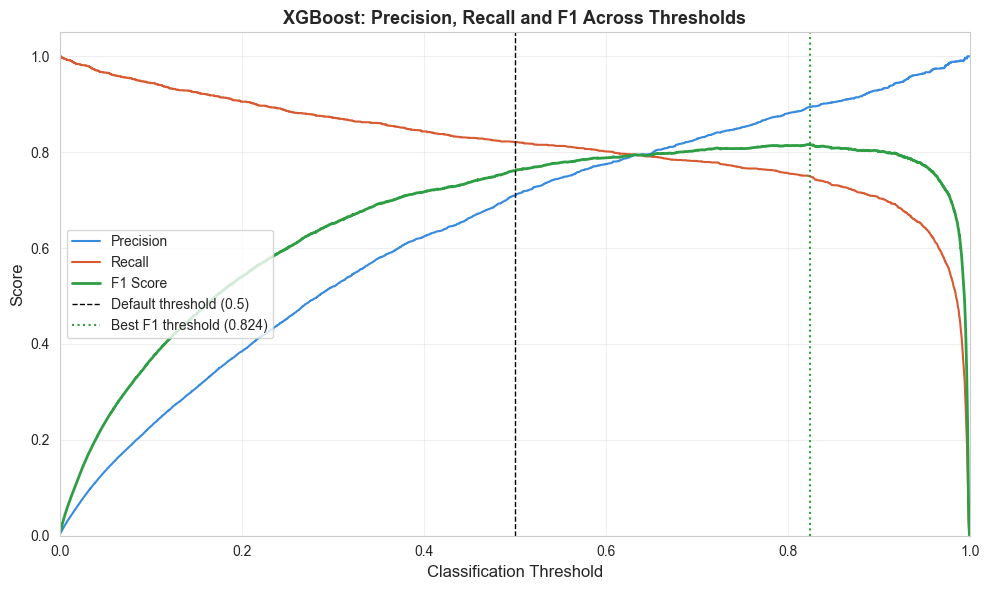

Chart saved: chart_threshold_optimisation.png


In [58]:
from sklearn.metrics import precision_recall_curve, f1_score

print("Sweeping classification thresholds for XGBoost...")
print()

# xgb_proba and y_test already exist from Part 4, no need to retrain anything here
precision_vals, recall_vals, thresholds = precision_recall_curve(y_test, xgb_proba)

# precision_recall_curve returns one more precision/recall value than
# thresholds, so the final precision/recall value is dropped to line them up
precision_vals = precision_vals[:-1]
recall_vals    = recall_vals[:-1]

# F1 score at every threshold (a small number is added to avoid dividing by zero)
f1_vals = 2 * (precision_vals * recall_vals) / (precision_vals + recall_vals + 1e-10)

best_f1_idx       = f1_vals.argmax()
best_f1_threshold = thresholds[best_f1_idx]

default_preds = (xgb_proba >= DEFAULT_THRESHOLD).astype(int)

print(f"Default threshold:        {DEFAULT_THRESHOLD}")
print(f"Best F1 threshold:        {best_f1_threshold:.4f}")
print(f"F1 at default threshold:  {f1_score(y_test, default_preds):.4f}")
print(f"F1 at best threshold:     {f1_vals[best_f1_idx]:.4f}")
print()

# plot precision, recall and F1 against threshold
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision_vals, label='Precision', color='#378ADD')
plt.plot(thresholds, recall_vals, label='Recall', color='#D85A30')
plt.plot(thresholds, f1_vals, label='F1 Score', color='#2E9E44', linewidth=2)
plt.axvline(x=DEFAULT_THRESHOLD, color='black', linestyle='--', linewidth=1,
            label=f'Default threshold ({DEFAULT_THRESHOLD})')
plt.axvline(x=best_f1_threshold, color='#2E9E44', linestyle=':', linewidth=1.5,
            label=f'Best F1 threshold ({best_f1_threshold:.3f})')
plt.xlabel('Classification Threshold', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.title('XGBoost: Precision, Recall and F1 Across Thresholds',
          fontsize=13, fontweight='bold')
plt.legend(loc='center left', fontsize=10)
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('chart_threshold_optimisation.png', dpi=CHART_DPI, bbox_inches='tight')
plt.show()
print("Chart saved: chart_threshold_optimisation.png")

## 5.2 Cost Sensitive Threshold

F1 treats a missed fraud and a false alert as equally bad, which is rarely true in practice. This step assigns a cost to each type of mistake (set in the Configuration Constants cell) and finds the threshold that minimises the total cost across the test set.

Finding the threshold that minimises total business cost...

Cost assumptions: missed fraud = 100, false alert = 5

Default threshold (0.5):            total cost = 41,995
Cost optimal threshold (0.2085):  total cost = 35,240
Cost saved by switching:                  6,755


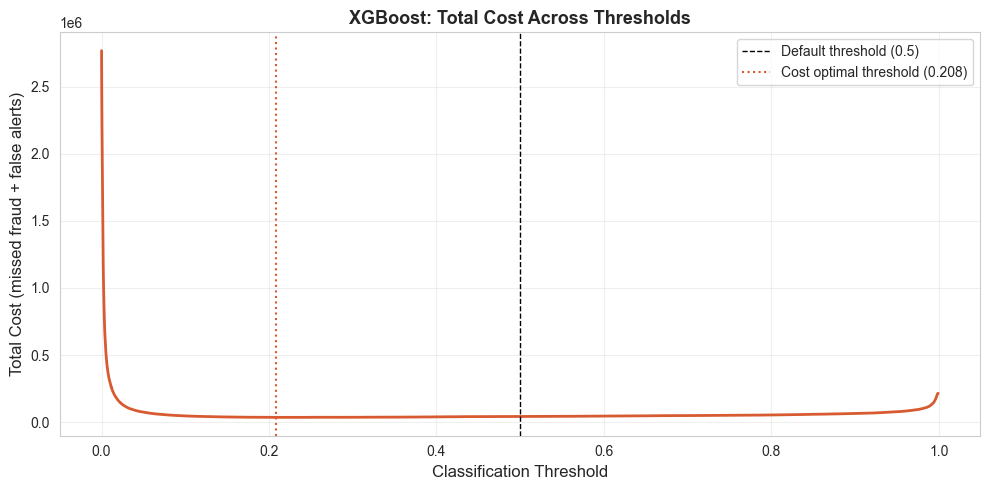


Chart saved: chart_threshold_cost.png


In [59]:
from sklearn.metrics import confusion_matrix

print("Finding the threshold that minimises total business cost...")
print()

# precision_vals, recall_vals and thresholds already exist from the cell
# above. True positives and false positives at every threshold can be
# worked out directly from precision and recall, with simple algebra,
# instead of looping through every threshold and rebuilding a confusion
# matrix from scratch each time (which is far too slow on a large test set)
total_positives = y_test.sum()                        # total real fraud cases in the test set

true_positives  = recall_vals * total_positives                    # tp = recall * actual positives
false_negatives = total_positives - true_positives                 # fn = actual positives - tp

# precision = tp / (tp + fp), rearranged gives fp = tp / precision - tp
# a small number is added to precision_vals to avoid dividing by zero
false_positives = true_positives / (precision_vals + 1e-10) - true_positives

total_costs = (false_negatives * COST_PER_MISSED_FRAUD) + (false_positives * COST_PER_FALSE_ALERT)

candidate_thresholds = thresholds
best_cost_idx       = total_costs.argmin()
best_cost_threshold = candidate_thresholds[best_cost_idx]

# cost at the default threshold, for comparison (a single confusion matrix,
# not one per threshold, so this stays fast)
tn, fp, fn, tp = confusion_matrix(y_test, default_preds).ravel()
default_cost = (fn * COST_PER_MISSED_FRAUD) + (fp * COST_PER_FALSE_ALERT)

print(f"Cost assumptions: missed fraud = {COST_PER_MISSED_FRAUD}, false alert = {COST_PER_FALSE_ALERT}")
print()
print(f"Default threshold ({DEFAULT_THRESHOLD}):            total cost = {default_cost:,}")
print(f"Cost optimal threshold ({best_cost_threshold:.4f}):  total cost = {total_costs[best_cost_idx]:,.0f}")
print(f"Cost saved by switching:                  {default_cost - total_costs[best_cost_idx]:,.0f}")

plt.figure(figsize=(10, 5))
plt.plot(candidate_thresholds, total_costs, color='#D85A30', linewidth=2)
plt.axvline(x=DEFAULT_THRESHOLD, color='black', linestyle='--', linewidth=1,
            label=f'Default threshold ({DEFAULT_THRESHOLD})')
plt.axvline(x=best_cost_threshold, color='#D85A30', linestyle=':', linewidth=1.5,
            label=f'Cost optimal threshold ({best_cost_threshold:.3f})')
plt.xlabel('Classification Threshold', fontsize=12)
plt.ylabel('Total Cost (missed fraud + false alerts)', fontsize=12)
plt.title('XGBoost: Total Cost Across Thresholds', fontsize=13, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('chart_threshold_cost.png', dpi=CHART_DPI, bbox_inches='tight')
plt.show()
print()
print("Chart saved: chart_threshold_cost.png")

## 5.3 Threshold Comparison Summary

In [60]:
print("THRESHOLD COMPARISON SUMMARY: XGBoost")
print()

thresholds_to_compare = {
    'Default (0.5)': DEFAULT_THRESHOLD,
    'Best F1':        best_f1_threshold,
    'Lowest cost':    best_cost_threshold,
}

print(f"  {'Threshold':<16} {'Value':>8} {'Precision':>10} {'Recall':>8} "
      f"{'F1':>8} {'Fraud Caught':>15} {'False Alerts':>13}")
print()

for label, t in thresholds_to_compare.items():
    preds = (xgb_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    caught = f"{tp:,}/{tp + fn:,}"
    print(f"  {label:<16} {t:>8.4f} {prec:>10.4f} {rec:>8.4f} "
          f"{f1:>8.4f} {caught:>15} {fp:>13,}")

print()
print("Choosing a threshold is a business decision as much as a")
print("modelling one: the best F1 threshold treats a missed fraud")
print("and a false alert as equally costly, while the lowest cost")
print("threshold reflects the cost assumptions set in the")
print("Configuration Constants cell at the top of this notebook.")

THRESHOLD COMPARISON SUMMARY: XGBoost

  Threshold           Value  Precision   Recall       F1    Fraud Caught  False Alerts

  Default (0.5)      0.5000     0.7101   0.8210   0.7615     1,761/2,145           719
  Best F1            0.8242     0.8949   0.7501   0.8161     1,609/2,145           189
  Lowest cost        0.2085     0.3969   0.9044   0.5517     1,940/2,145         2,948

Choosing a threshold is a business decision as much as a
modelling one: the best F1 threshold treats a missed fraud
and a false alert as equally costly, while the lowest cost
threshold reflects the cost assumptions set in the
Configuration Constants cell at the top of this notebook.


## Install river

`river` provides the ADWIN and DDM concept drift detectors used in Part 6.

**Note on compatibility:** `river` requires NumPy 2.3 or higher, which conflicts with `numba` (a SHAP dependency that requires NumPy 2.2 or lower). The `--no-deps` flag installs `river` without upgrading NumPy, keeping SHAP working correctly.

In [61]:
import subprocess
import sys
import importlib

# sys.executable is the exact Python interpreter running this
# notebook's kernel, so the package always installs where it
# can actually be imported, regardless of which Python install
# happens to be first on the system PATH
result = subprocess.run(
    [sys.executable, '-m', 'pip', 'install', 'river', '--no-deps'],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("river installed successfully.")
else:
    print("WARNING: pip install failed. See stderr above for details.")

# refresh Python's import system so a package installed just now
# in this same kernel session can be found immediately; if the
# import below still fails, restart the kernel and rerun from here
importlib.invalidate_caches()

# --no-deps is used on purpose here: river requires numpy 2.3.4 or higher,
# which directly conflicts with numba (a SHAP dependency), which requires
# numpy 2.2 or lower. river is not imported anywhere else in this notebook,
# so installing it without its numpy requirement keeps SHAP working
# correctly on every run, including after a fresh kernel restart.

# Part 6: Concept Drift Detection

ADWIN and DDM are applied to the XGBoost model's prediction errors on the time-ordered test stream. Both algorithms watch whether the error rate changes significantly as transactions arrive one by one.

- **ADWIN** (Adaptive Windowing): keeps a sliding window over the error stream and signals drift when the recent error rate diverges from the older error rate. Conservative, with few false alarms.
- **DDM** (Drift Detection Method): monitors the error rate against its historical minimum and signals drift when errors rise significantly. More sensitive than ADWIN.

Both detectors receive the same input: a stream of 0s and 1s where 1 means the XGBoost model made an error on that transaction and 0 means it was correct.

Running concept drift detection on the XGBoost test stream...

Total test transactions:  555,719
Total model errors:       1,103
Overall error rate:       0.198%

ADWIN detected 2 drift points
  First drift at transaction: 282,367
  Last  drift at transaction: 417,439

DDM detected 25 drift points
  First drift at transaction: 1,044
  Last  drift at transaction: 285,474



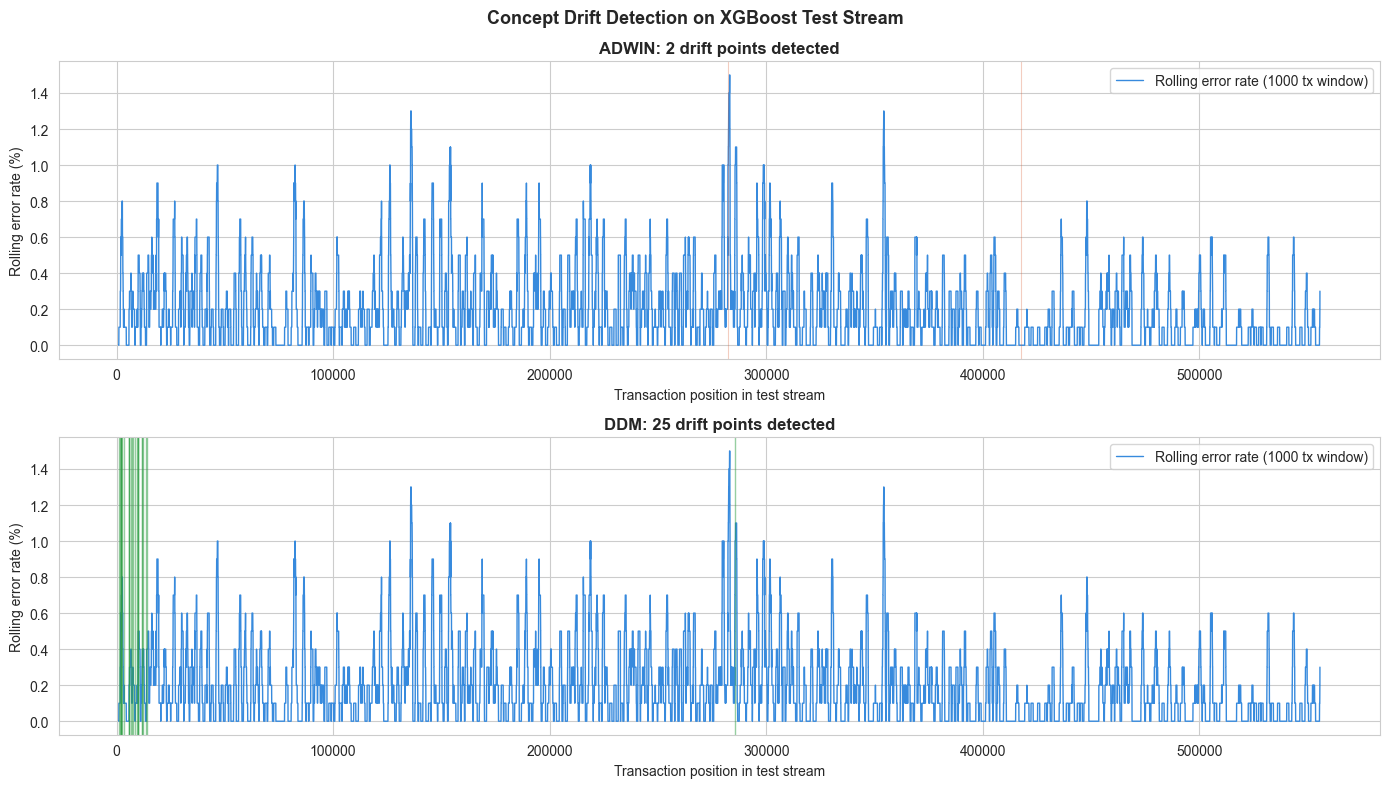

Chart saved: chart_drift_detection.png

Monthly error rate on test stream:

  Month          Error Rate

  2020-06            0.253%
  2020-07            0.191%
  2020-08            0.244%
  2020-09            0.242%
  2020-10            0.280%
  2020-11            0.172%
  2020-12            0.114%


In [62]:
from river import drift                               # ADWIN and DDM detectors

print("Running concept drift detection on the XGBoost test stream...")
print()

# build the error stream from XGBoost predictions
# 1 = model prediction was wrong, 0 = model prediction was correct
errors = (xgb_pred != y_test.values).astype(int)

print(f"Total test transactions:  {len(errors):,}")
print(f"Total model errors:       {errors.sum():,}")
print(f"Overall error rate:       {errors.mean()*100:.3f}%")
print()

# --- ADWIN ---
adwin        = drift.ADWIN()                          # create ADWIN detector
adwin_drifts = []                                     # positions where drift was detected

for i, error in enumerate(errors):
    adwin.update(error)                               # feed the next error value
    if adwin.drift_detected:                          # if ADWIN raises an alarm
        adwin_drifts.append(i)                        # record the position

print(f"ADWIN detected {len(adwin_drifts)} drift points")
if adwin_drifts:
    print(f"  First drift at transaction: {adwin_drifts[0]:,}")
    print(f"  Last  drift at transaction: {adwin_drifts[-1]:,}")
print()

# --- DDM ---
ddm        = drift.binary.DDM()                       # create DDM detector
ddm_drifts = []                                       # positions where drift was detected

for i, error in enumerate(errors):
    ddm.update(error)                                 # feed the next error value
    if ddm.drift_detected:                            # if DDM raises an alarm
        ddm_drifts.append(i)                          # record the position

print(f"DDM detected {len(ddm_drifts)} drift points")
if ddm_drifts:
    print(f"  First drift at transaction: {ddm_drifts[0]:,}")
    print(f"  Last  drift at transaction: {ddm_drifts[-1]:,}")
print()

# --- rolling error rate chart ---
# a 1,000-transaction rolling window smooths out noise so the
# underlying trend is easier to see
window         = 1000
rolling_errors = pd.Series(errors).rolling(window=window).mean() * 100

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# top chart: ADWIN drift points
axes[0].plot(rolling_errors, color='#378ADD', linewidth=1,
             label=f'Rolling error rate ({window} tx window)')
for point in adwin_drifts:
    axes[0].axvline(x=point, color='#D85A30',
                    alpha=0.3, linewidth=0.8)          # red line at each drift point
axes[0].set_title(f'ADWIN: {len(adwin_drifts)} drift points detected',
                  fontweight='bold')
axes[0].set_xlabel('Transaction position in test stream')
axes[0].set_ylabel('Rolling error rate (%)')
axes[0].legend()

# bottom chart: DDM drift points
axes[1].plot(rolling_errors, color='#378ADD', linewidth=1,
             label=f'Rolling error rate ({window} tx window)')
for point in ddm_drifts:
    axes[1].axvline(x=point, color='#2E9E44',
                    alpha=0.5, linewidth=1)             # green line at each drift point
axes[1].set_title(f'DDM: {len(ddm_drifts)} drift points detected',
                  fontweight='bold')
axes[1].set_xlabel('Transaction position in test stream')
axes[1].set_ylabel('Rolling error rate (%)')
axes[1].legend()

plt.suptitle('Concept Drift Detection on XGBoost Test Stream',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('chart_drift_detection.png', dpi=CHART_DPI, bbox_inches='tight')
plt.show()
print("Chart saved: chart_drift_detection.png")
print()

# --- monthly error rate ---
# loads the test dates from the enriched file so we can group
# errors by month and see how model performance shifts over time
test_dates = pd.read_csv(TEST_ENRICHED_FILE,
                          usecols=['trans_date_trans_time'])
test_dates['trans_date_trans_time'] = pd.to_datetime(
    test_dates['trans_date_trans_time'])
test_dates['error'] = errors
test_dates['month'] = test_dates['trans_date_trans_time'].dt.to_period('M')

monthly_errors = test_dates.groupby('month')['error'].mean() * 100

print("Monthly error rate on test stream:")
print()
print(f"  {'Month':<12} {'Error Rate':>12}")
print()
for month, rate in monthly_errors.items():
    print(f"  {str(month):<12} {rate:>11.3f}%")


# Part 7: Final Results Summary

Brings together the headline numbers from every part above: model comparison, confusion matrix summary, top SHAP features, concept drift detection, dataset summary, and the full list of charts produced. The model comparison below uses each model's default 0.5 threshold. See Part 5 for how XGBoost performs at its optimised threshold instead.

In [63]:
print("FINAL RESULTS SUMMARY")
print()

# every number below is pulled from variables already computed in
# Parts 4, 4.13 and 6 above, rather than retyped by hand, so this
# summary always matches whatever the notebook actually produced

print("1. MODEL PERFORMANCE COMPARISON")
print()
print(f"  {'Model':<28} {'AUPRC':>8} {'ROC AUC':>9} "
      f"{'F1':>8} {'Precision':>10} {'Recall':>8}")
print()

for _, row in results_df.iterrows():
    print(f"  {row['Model']:<28} {row['AUPRC']:>8.4f} {row['ROC_AUC']:>9.4f} "
          f"{row['F1']:>8.4f} {row['Precision']:>10.4f} {row['Recall']:>8.4f}")

best_row = results_df.loc[results_df['AUPRC'].idxmax()]
print()
print(f"  Best model: {best_row['Model']} (AUPRC {best_row['AUPRC']:.4f})")
print(f"  Primary metric (AUPRC): {best_row['AUPRC']:.4f}")
print()

print("2. FRAUD DETECTION SUMMARY (CONFUSION MATRIX)")
print()
print(f"  {'Model':<28} {'Caught':>8} {'Missed':>8} "
      f"{'False Alerts':>14} {'Detection Rate':>15}")
print()

for _, row in confusion_df.iterrows():
    print(f"  {row['Model']:<28} {row['Caught']:>8,} {row['Missed']:>8,} "
          f"{row['False_Alerts']:>14,} {row['Detection_Rate']:>14.1f}%")

print()

print("3. TOP 5 MOST IMPORTANT FEATURES (SHAP, XGBoost)")
print()
for _, row in feature_importance.head(5).iterrows():
    print(f"  {row['Feature']:<28} {row['Mean_SHAP']:>8.4f}")

print()

print("4. CONCEPT DRIFT DETECTION SUMMARY")
print()
print(f"  {'Detector':<12} {'Drift Points':>14} {'First Detection':>22}")
print()
adwin_first = f"Transaction {adwin_drifts[0]:,}" if adwin_drifts else "None detected"
ddm_first   = f"Transaction {ddm_drifts[0]:,}"   if ddm_drifts   else "None detected"
print(f"  {'ADWIN':<12} {len(adwin_drifts):>14} {adwin_first:>22}")
print(f"  {'DDM':<12} {len(ddm_drifts):>14} {ddm_first:>22}")
print()
print(f"  Monthly error rate range: {monthly_errors.min():.3f}% to {monthly_errors.max():.3f}%")
print(f"  Monthly fraud rate range: {all_monthly['fraud_rate_pct'].min():.3f}% "
      f"to {all_monthly['fraud_rate_pct'].max():.3f}%")
print(f"  Drift confirmed across {all_monthly['month_str'].nunique()} months of data")
print()

print("5. DATASET SUMMARY")
print()
print(f"  Source          Sparkov simulated transactions")
print(f"                  + US Census ACS 2019 enrichment")
print(f"  Training rows   {len(y_train):,} (after SMOTE)")
print(f"  Test rows       {len(y_test):,}")
print(f"  Features        {X_train.shape[1]}")
print(f"  Fraud rate      {y_train.mean()*100:.1f}% train / {y_test.mean()*100:.3f}% test")
print(f"  Time period     Jan 2019 to Dec 2020 (24 months)")
print()

print("6. CHARTS PRODUCED")
print()
charts = [
    'chart_class_imbalance.png',
    'chart_amount_analysis.png',
    'chart_fraud_by_category.png',
    'chart_fraud_by_gender.png',
    'chart_temporal_analysis.png',
    'chart_census_distributions.png',
    'chart_correlation_heatmap.png',
    'chart_fraud_rate_by_state.png',
    'chart_transaction_locations.png',
    'chart_concept_drift.png',
    'chart_model_comparison.png',
    'chart_confusion_matrices.png',
    'chart_precision_recall_curves.png',
    'chart_roc_curves.png',
    'chart_shap_summary.png',
    'chart_shap_importance.png',
    'chart_threshold_optimisation.png',
    'chart_threshold_cost.png',
    'chart_drift_detection.png',
]
for i, chart in enumerate(charts, 1):
    print(f"  {i:>2}. {chart}")

print()
print("ANALYSIS COMPLETE")


FINAL RESULTS SUMMARY

1. MODEL PERFORMANCE COMPARISON

  Model                           AUPRC   ROC AUC       F1  Precision   Recall

  Logistic Regression            0.1447    0.8514   0.1616     0.0908   0.7380
  Random Forest                  0.7872    0.9895   0.7348     0.6960   0.7781
  XGBoost                        0.8600    0.9955   0.7615     0.7101   0.8210
  Deep Neural Network (DNN)      0.7286    0.9714   0.2951     0.1784   0.8545

  Best model: XGBoost (AUPRC 0.8600)
  Primary metric (AUPRC): 0.8600

2. FRAUD DETECTION SUMMARY (CONFUSION MATRIX)

  Model                          Caught   Missed   False Alerts  Detection Rate

  Logistic Regression             1,583      562         15,860           73.8%
  Random Forest                   1,669      476            729           77.8%
  XGBoost                         1,761      384            719           82.1%
  Deep Neural Network (DNN)       1,833      312          8,444           85.5%

3. TOP 5 MOST IMPORTANT FEA